# C1: Delivery date estimation at checkout

## The problem and its stakeholder

**Problem (regression).** At checkout, estimate how many days an order will take to arrive, and turn
that estimate into the delivery date quoted to the customer, which we call the **promise**.

**Stakeholder.** Olist's operations team, which sets the delivery date quoted at checkout. As set out
in Phase 1, the prediction is the quoted date itself, so it is applied automatically to every order
and no one has to act on each prediction.

**Why it matters.** Phase 1 found that late orders receive much lower review scores. A promise one
day faster raised sales by 0.73% in a field experiment (Cui et
al., 2024).

**Target.** `delivery_days`: calendar days from purchase to delivery, for delivered orders, built
from the order timestamps.

**Prediction point.** At checkout, when the customer is ready to go ahead with the purchase.

**Success criteria.**
- **The estimate:** a lower error than the best simple baseline on time-ordered validation folds.
- **The promise:** at the same late rate as Olist's quotes, a shorter average promise. This answers
  the Phase 1 feedback ("What does beating the platform's own estimate look like?"); an error
  measure alone treats a day early and a day late alike.


## How this notebook is organised

- **Part A. Preparing the data:** the orders used, the split into training and test months, the
  cleaning decisions and the features: 17, plus 2 payment features that Part B tests.
- **Part B. The linear models:** correlations, baselines, ordinary least squares (OLS) and its checks,
  Ridge, Lasso and quantile regression, and the promise against Olist's quote.
- **Part C. Trees and the ensemble:** a decision tree, a random forest and the final model, the
  ensemble of OLS and the forest.
- **Part D. The test:** the test results, their uncertainty, insights, limitations and the saved
  model.

Tables and figures are numbered within each part: Table B12 is the twelfth table of Part B.

The four parts were first built as separate notebooks and then merged into this one. So that each
part can still be run on its own, each one starts by loading what it needs from the files saved by the
parts before it. This repeats some imports and set-up steps, such as rebuilding the validation folds in
Part C.


# Part A. Preparing the data

This part sets out the orders the model will be built on, the split into training and test months,
the cleaning decisions and the features. The test months are used here only for the split, the data
checks and building their features by the same rules; nothing is learned from them.

## A1. Setup


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# The notebook lives in notebooks/ and the data in <Phase 2>/data, so step up a level when the
# kernel starts inside notebooks/, which is the VS Code default.
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESSED    = PROJECT_ROOT / "data" / "processed"
RAW          = PROJECT_ROOT / "data" / "raw"

RANDOM_SEED = 42                     # every random step in the C1 notebooks uses this
WINDOW      = ("2017-01", "2018-08")  # usable purchase months, from Phase 1 Section 5
TEST_FROM   = "2018-05"              # first test month; every earlier month is training

pd.set_option("display.max_columns", 50)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
BLUE, AMBER = "#3b6ea8", "#d08c2e"


In [2]:
DATES = ["order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
         "order_delivered_customer_date", "order_estimated_delivery_date"]
ol = pd.read_csv(PROCESSED / "order_level.csv", parse_dates=DATES, low_memory=False)
print(f"order_level from Phase 1: {len(ol):,} orders, {ol.shape[1]} columns")


order_level from Phase 1: 99,441 orders, 36 columns


## A2. Population

A model can learn only from orders whose delivery time is known, so the population is the delivered
orders bought within the usable window found in Phase 1, January 2017 to August 2018. The model
therefore estimates the delivery time of orders that arrive. Table A1 shows how many orders remain at
each step, and the check after it tests whether leaving out the undelivered orders is safe.


In [3]:
month     = ol["order_purchase_timestamp"].dt.to_period("M").astype(str)
in_window = month.between(*WINDOW)
delivered = ol["is_delivered_complete"].astype(bool)

funnel = pd.DataFrame([
    {"step": "all orders",                                    "orders": len(ol)},
    {"step": "delivered, with a delivery date",               "orders": int(delivered.sum())},
    {"step": f"and purchased {WINDOW[0]} to {WINDOW[1]}",     "orders": int((delivered & in_window).sum())},
])
funnel["share of all orders"] = 100 * funnel["orders"] / len(ol)
print("Table A1. From all orders to the population: delivered orders inside the usable window")
display(funnel.style.format({"orders": "{:,}", "share of all orders": "{:.2f}"}).hide(axis="index"))

c1 = ol.loc[delivered & in_window].copy()
c1["purchase_month"] = month[delivered & in_window]
print(f"delivered orders outside the window, set aside: {int((delivered & ~in_window).sum()):,}")


Table A1. From all orders to the population: delivered orders inside the usable window


step,orders,share of all orders
all orders,"99,441",100.00
"delivered, with a delivery date","96,470",97.01
and purchased 2017-01 to 2018-08,"96,203",96.74


delivered orders outside the window, set aside: 267


### Orders left out of the population

The orders left out are mainly of two kinds. Some failed: Olist records them as cancelled or
unavailable. Others were still in progress when the data ends, mostly already shipped. These matter
more. An order still on its way had taken at least as long as it had been open, so leaving the slowest
orders out could make deliveries look faster than they are; such an outcome is called *censored*. The
next cell counts each kind in the training and test months (Table A2) and checks how long the open
orders had been waiting.


In [4]:
window = ol.loc[in_window].copy()
window["month"] = month[in_window]
IN_PROGRESS = ["shipped", "invoiced", "processing", "approved", "created"]
window["group"] = np.select(
    [window["is_delivered_complete"].astype(bool),
     window["order_status"].isin(["canceled", "unavailable"]),
     window["order_status"].isin(IN_PROGRESS)],
    ["delivered (the population)", "failed: canceled or unavailable", "still in progress"],
    default="marked delivered, but no delivery date")
window["period"] = np.where(window["month"] >= TEST_FROM, "test months", "training months")

groups = (pd.crosstab(window["group"], window["period"])
            [["training months", "test months"]].reset_index())
for p in ["training months", "test months"]:
    groups[f"% of {p}"] = 100 * groups[p] / groups[p].sum()
print("Table A2. Orders in the usable window by outcome, in the training and test months")
display(groups.style.format({"training months": "{:,}", "test months": "{:,}",
                             "% of training months": "{:.2f}", "% of test months": "{:.2f}"})
        .hide(axis="index"))

data_end  = ol["order_delivered_customer_date"].max().normalize()
prog      = window.loc[window["group"] == "still in progress"]
open_days = (data_end - prog["order_purchase_timestamp"].dt.normalize()).dt.days
print(f"the last delivery recorded anywhere in the data is on {data_end.date()}")
print(f"still in progress: {len(prog):,} orders ({len(prog) / len(window):.2%} of the window), "
      f"{int((prog['order_status'] == 'shipped').sum()):,} of them shipped")
print(f"by that date every one had been open at least {open_days.min()} days "
      f"(median {open_days.median():.0f})")

# Compared with how long delivered TRAINING orders took; the test target stays unexamined.
train_days = c1.loc[c1["purchase_month"] < TEST_FROM, "delivery_days"]
print(f"for comparison, delivered training orders: 95% arrived within "
      f"{train_days.quantile(.95):.0f} days, and {(train_days >= open_days.min()).mean():.2%} "
      f"took {open_days.min()} days or more")

# Orders bought near the end can appear only if they arrived before the data ends. Judging by
# training delivery times, this is the share of each test month's orders likely cut off that way.
test_orders = c1.loc[c1["purchase_month"] >= TEST_FROM]
time_left   = (data_end - test_orders["order_purchase_timestamp"].dt.normalize()).dt.days
sorted_days = np.sort(train_days.to_numpy())
cut_off     = 1 - np.searchsorted(sorted_days, time_left.to_numpy(), side="right") / len(sorted_days)
by_month    = pd.Series(cut_off).groupby(test_orders["purchase_month"].to_numpy()).mean()
print(f"test orders had at least {time_left.min()} days to arrive before the data ends; judging by "
      f"training delivery times, about {cut_off.mean():.2%} of them would have been cut off "
      f"({', '.join(f'{m}: {v:.2%}' for m, v in by_month.items())})")


Table A2. Orders in the usable window by outcome, in the training and test months


group,training months,test months,% of training months,% of test months
delivered (the population),"70,851","25,352",96.73,98.10
failed: canceled or unavailable,970,212,1.32,0.82
"marked delivered, but no delivery date",2,6,0.00,0.02
still in progress,"1,425",274,1.95,1.06


the last delivery recorded anywhere in the data is on 2018-10-17
still in progress: 1,699 orders (1.71% of the window), 1,097 of them shipped
by that date every one had been open at least 54 days (median 320)
for comparison, delivered training orders: 95% arrived within 32 days, and 0.65% took 54 days or more


test orders had at least 49 days to arrive before the data ends; judging by training delivery times, about 0.13% of them would have been cut off (2018-05: 0.03%, 2018-06: 0.06%, 2018-07: 0.11%, 2018-08: 0.31%)


Leaving out the orders still in progress looks safe. There are 1,699 of them, 1.71% of the window,
1,097 already shipped, and all had been open at least 54 days when the data ends. Only 0.65% of
delivered training orders took that long, so these orders look stalled or lost. They are also rarer
in the test months, 1.06% against 1.95% in training; if slow orders were being cut off, that share
would rise towards the end of the data, so there is no sign of that here. The 8 orders
marked delivered without a delivery date are left out too, as they have no target.


### The target

The target, `delivery_days`, was built in Phase 1. The next cell checks that it is exactly the number
of calendar days from purchase to delivery, by rebuilding it from the two timestamps, each reduced to
its date. The target therefore counts whole days.


In [5]:
rebuilt = (c1["order_delivered_customer_date"].dt.normalize()
           - c1["order_purchase_timestamp"].dt.normalize()).dt.days

assert (rebuilt == c1["delivery_days"]).all(), "delivery_days does not match its definition"
assert c1["delivery_days"].notna().all() and (c1["delivery_days"] >= 0).all()
assert not c1["order_id"].duplicated().any()
print(f"delivery_days equals purchase-to-delivery calendar days on all {len(c1):,} orders, "
      f"with no missing or negative values and no duplicate orders")


delivery_days equals purchase-to-delivery calendar days on all 96,203 orders, with no missing or negative values and no duplicate orders


## A3. Training and test split

The orders are split by time, as Phase 1 feedback asked: the model learns from the earlier months and
is tested on the last four, May to August 2018. This matches how the model would be used, estimating
future orders from past ones. A random split would put orders from the same weeks on both sides, so the
model would be tested partly on periods it had already learned from, which could make its score look
better than it would be in use. Figure A1 shows the number of orders in each month, with the test
months marked, and the median delivery time in each training month.


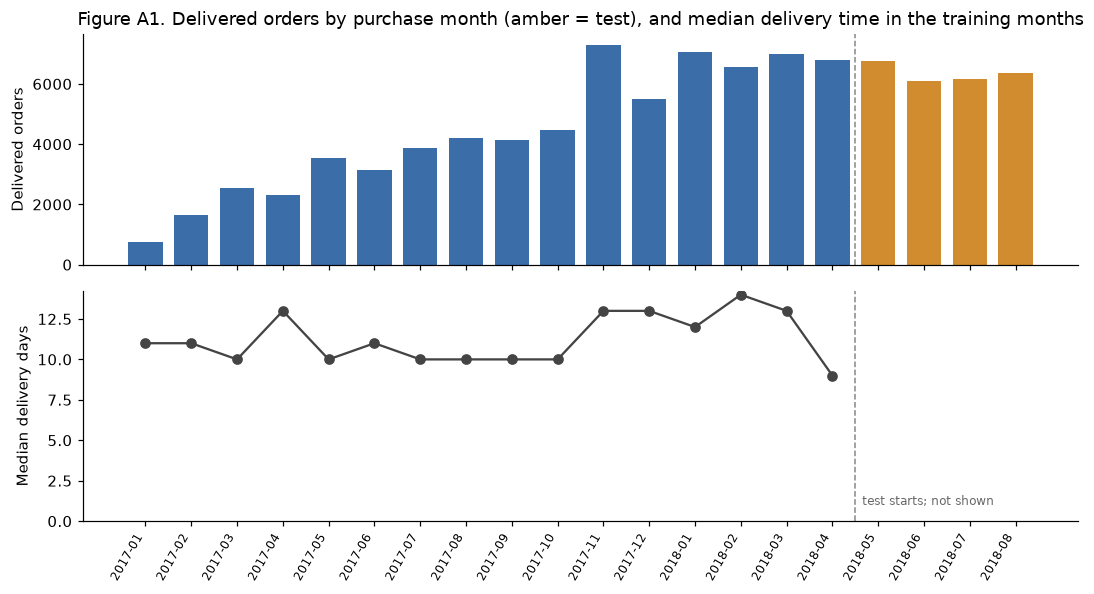

2017-01 to 2017-10: monthly median delivery between 10 and 13 days
2017-11 to 2018-03: monthly median delivery between 12 and 14 days
2018-04: monthly median delivery 9 days


In [6]:
c1["split"] = np.where(c1["purchase_month"] >= TEST_FROM, "test", "train")

# Order counts for every month show where the split falls. Delivery times are summarised for the
# training months only, so nothing here describes how fast the test months were.
monthly = (c1.groupby("purchase_month")
             .agg(orders=("order_id", "size"), split=("split", "first"))
             .reset_index())
train_median = c1.loc[c1["split"] == "train"].groupby("purchase_month")["delivery_days"].median()
monthly["median_days"] = monthly["purchase_month"].map(train_median)      # empty for test months

fig, axes = plt.subplots(2, 1, figsize=(10, 5.5), sharex=True)
x = np.arange(len(monthly))
axes[0].bar(x, monthly["orders"], width=0.75,
            color=np.where(monthly["split"] == "test", AMBER, BLUE))
axes[0].set_ylabel("Delivered orders")
axes[0].set_title("Figure A1. Delivered orders by purchase month (amber = test), and median delivery time "
                  "in the training months")
axes[1].plot(x, monthly["median_days"], marker="o", color="#444")
axes[1].set_ylabel("Median delivery days")
axes[1].set_ylim(0, None)
axes[1].set_xticks(x, monthly["purchase_month"], rotation=60, ha="right", fontsize=8)
boundary = monthly.index[monthly["purchase_month"] == TEST_FROM][0] - 0.5
for ax in axes:
    ax.axvline(boundary, color="#888", ls="--", lw=1)
axes[1].text(boundary + 0.15, 1, "test starts; not shown", fontsize=8, color="#666")
plt.tight_layout()
plt.show()

periods = {"2017-01 to 2017-10": ("2017-01", "2017-10"),
           "2017-11 to 2018-03": ("2017-11", "2018-03"),
           "2018-04": ("2018-04", "2018-04")}
for label, (a, b) in periods.items():
    s = monthly.loc[monthly["purchase_month"].between(a, b), "median_days"]
    span = f"{s.min():.0f} days" if a == b else f"between {s.min():.0f} and {s.max():.0f} days"
    print(f"{label}: monthly median delivery {span}")


In [7]:
split_table = (c1.groupby("split")
                 .agg(orders=("order_id", "size"),
                      first_month=("purchase_month", "min"),
                      last_month=("purchase_month", "max"))
                 .reindex(["train", "test"])
                 .reset_index())
split_table["share"] = 100 * split_table["orders"] / len(c1)
print("Table A3. Training and test split: orders and months in each part")
display(split_table.style.format({"orders": "{:,}", "share": "{:.2f}"}).hide(axis="index"))

# The two sides must not share a month, otherwise the split is not a clean cut in time.
is_train = c1["split"] == "train"
assert c1.loc[is_train, "purchase_month"].max() < c1.loc[~is_train, "purchase_month"].min()


Table A3. Training and test split: orders and months in each part


split,orders,first_month,last_month,share
train,"70,851",2017-01,2018-04,73.65
test,"25,352",2018-05,2018-08,26.35


The split puts 70,851 orders, January 2017 to April 2018, in training and 25,352, May to August 2018,
in test, 26.35% of the orders.

Delivery speed shifts over time. In the training months, the monthly median delivery ran between 10
and 13 days through most of 2017, rose to between 12 and 14 from November 2017 to March 2018, and fell
to 9 days in April 2018.


## A4. Cleaning decisions

Phase 1 already cleaned the source tables, for example setting product weights of zero grams to missing and
translating category names. This section covers the decisions specific to this model: timestamps
recorded out of order, very long deliveries, and missing values.


### Timestamps recorded out of order

Phase 1 found 1,359 orders where the carrier collected the parcel before the payment approval was
recorded, and the Phase 1 feedback asked for the cause to be resolved.


In [8]:
anomalous = ol["order_delivered_carrier_date"] < ol["order_approved_at"]
approval_day = ol["order_approved_at"].dt.floor("D")

batches = (ol.loc[anomalous]
             .groupby(approval_day[anomalous])
             .agg(out_of_order=("order_id", "size"),
                  first=("order_approved_at", "min"), last=("order_approved_at", "max"))
             .sort_values("out_of_order", ascending=False)
             .head(3))
batches["all approvals that day"] = approval_day.value_counts().reindex(batches.index).values
batches["approved between"] = (batches["first"].dt.strftime("%H:%M") + " and "
                               + batches["last"].dt.strftime("%H:%M"))
batches = batches.reset_index(names="approval date")
batches["approval date"] = batches["approval date"].dt.date
print("Table A4. The three approval days with the most orders collected by the carrier before approval")
display(batches[["approval date", "out_of_order", "all approvals that day", "approved between"]]
        .style.format({"out_of_order": "{:,}", "all approvals that day": "{:,}"}).hide(axis="index"))

top_two = batches["out_of_order"].head(2).sum()
print(f"orders with carrier pickup before payment approval: {int(anomalous.sum()):,}")
print(f"the two largest days hold {top_two:,} of them ({top_two / anomalous.sum():.0%}); "
      f"the rest are spread over {approval_day[anomalous].nunique() - 2} other days")


Table A4. The three approval days with the most orders collected by the carrier before approval


approval date,out_of_order,all approvals that day,approved between
2018-07-05,451,697,16:01 and 17:03
2018-04-24,383,990,17:08 and 19:28
2018-08-01,22,331,14:04 and 16:31


orders with carrier pickup before payment approval: 1,359
the two largest days hold 834 of them (61%); the rest are spread over 116 other days


In [9]:
c1["approval_after_pickup"] = c1["order_delivered_carrier_date"] < c1["order_approved_at"]
in_pop = c1.groupby("split")["approval_after_pickup"].sum().reindex(["train", "test"])
print(f"in the population: {int(in_pop.sum()):,} such orders, "
      f"{int(in_pop['train']):,} in training and {int(in_pop['test']):,} in the test months")

tr = c1.loc[c1["split"] == "train"]
print(f"training orders only: median delivery {tr.loc[tr['approval_after_pickup'], 'delivery_days'].median():.0f} "
      f"days for these orders against {tr.loc[~tr['approval_after_pickup'], 'delivery_days'].median():.0f} for the rest")

carrier_before_purchase = int((c1["order_delivered_carrier_date"] < c1["order_purchase_timestamp"]).sum())
delivered_before_carrier = int((c1["order_delivered_customer_date"] < c1["order_delivered_carrier_date"]).sum())
print(f"also in the population: {carrier_before_purchase} orders with a carrier date before the "
      f"purchase, and {delivered_before_carrier} delivered before the carrier collected them")


in the population: 1,350 such orders, 510 in training and 840 in the test months
training orders only: median delivery 9 days for these orders against 11 for the rest
also in the population: 165 orders with a carrier date before the purchase, and 19 delivered before the carrier collected them


Most of these orders cluster on two days. On 5 July 2018, 451 of the 697 approvals recorded that day
were for parcels the carrier had already collected, all approved between 16:01 and 17:03; on 24 April
2018, 383 of 990, approved between 17:08 and 19:28. Those two days hold 834 of the 1,359 orders, 61%,
and the rest are spread thinly over 116 other days. We therefore assume that the payment approvals were
recorded late, in batches, while shipping went ahead.

Of these, the 1,350 that are in the population are kept. The target uses only the purchase and
delivery dates, which these records do not affect, and the approval date is recorded after the
purchase, too late to be a feature. Dropping them would also remove fast orders: in training they
took a median of 9 days against 11 for the rest. The 165 orders with a carrier date before the
purchase and the 19 delivered before collection are kept for the same reason: we assume only
their carrier date is wrong, and it is known only after purchase, so it is not a feature either.


### Very long deliveries and the shape of the target

Very long deliveries are kept. The next cell describes the shape of the target on the training
orders, as it is and on a log scale (Table A5 and Figure A2).


Table A5. Delivery days of the training orders


orders,median,mean,90th pct,95th pct,99th pct,max
"70,851",11,13.6,25,32,48,210


training orders taking more than  30 days: 3,919 (5.53%)
training orders taking more than  60 days:   275 (0.39%)
training orders taking more than 100 days:    61 (0.09%)

skewness of delivery days 3.86; of log(1 + delivery days) -0.04


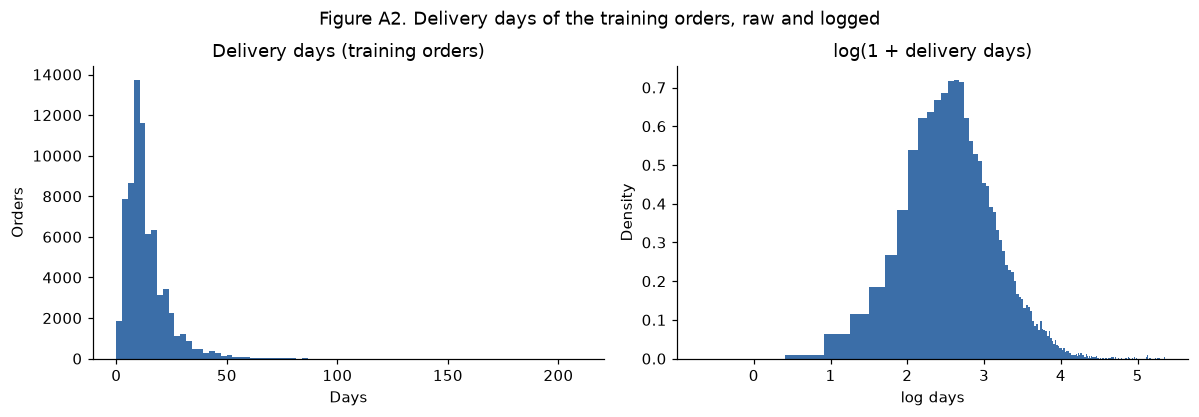

In [10]:
y_train = c1.loc[c1["split"] == "train", "delivery_days"]

shape = pd.DataFrame([{
    "orders": len(y_train), "median": y_train.median(), "mean": y_train.mean(),
    "90th pct": y_train.quantile(.90), "95th pct": y_train.quantile(.95),
    "99th pct": y_train.quantile(.99), "max": y_train.max()}])
print("Table A5. Delivery days of the training orders")
display(shape.style.format({"orders": "{:,}", "mean": "{:.1f}", "median": "{:.0f}",
                            "90th pct": "{:.0f}", "95th pct": "{:.0f}", "99th pct": "{:.0f}",
                            "max": "{:.0f}"}).hide(axis="index"))
for t in (30, 60, 100):
    print(f"training orders taking more than {t:>3} days: {(y_train > t).sum():>5,} "
          f"({(y_train > t).mean():.2%})")

log_y = np.log1p(y_train)          # log(1 + days), so a same-day delivery maps to 0
print(f"\nskewness of delivery days {y_train.skew():.2f}; of log(1 + delivery days) {log_y.skew():.2f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].hist(y_train, bins=80, color=BLUE)
axes[0].set_title("Delivery days (training orders)")
axes[0].set_xlabel("Days")
axes[0].set_ylabel("Orders")
# Days are whole numbers, so equal-width bins in log space would catch some days and miss
# others. One bin per day, shown as density because the bins differ in width, avoids the gaps.
day_edges = np.log1p(np.arange(-0.5, y_train.max() + 1.5))
axes[1].hist(log_y, bins=day_edges, density=True, color=BLUE)
axes[1].set_title("log(1 + delivery days)")
axes[1].set_xlabel("log days")
axes[1].set_ylabel("Density")
plt.tight_layout()
fig.suptitle("Figure A2. Delivery days of the training orders, raw and logged", y=1.04)
plt.show()


Half of training orders arrive within 11 days, 95% within 32, and the longest took 210; only 0.39%
took more than 60 days. These few long deliveries pull the mean, 13.6, above the median and give a
skewness of 3.86.

We plan to start with a simple model, ordinary least squares, which assumes that its errors are
normally distributed and equally spread. With a target this skewed, that is unlikely to hold: the
long deliveries pull the fitted line towards them, and errors are likely to grow for longer orders. On a
log scale the skewness falls to −0.04, close to symmetric. Which form to use is decided in Part B.


### Missing values

Phase 1 found missing values in three tables and left them unfilled. Only those in the products
table affect the features: some products have no category, and some have no weight or measurements.
The others are in review comments and in the approval, carrier and delivery dates, which are
recorded after checkout. The next cell counts the training orders that include such a product
(Table A6).


In [11]:
il = pd.read_csv(PROCESSED / "item_level.csv", low_memory=False)
train_ids = set(c1.loc[c1["split"] == "train", "order_id"])
il_train  = il.loc[il["order_id"].isin(train_ids)]

PRODUCT_COLS = ["product_weight_g", "product_length_cm", "product_height_cm",
                "product_width_cm", "product_category_name_english"]
missing = pd.DataFrame([
    {"column": col,
     "items missing": int(il_train[col].isna().sum()),
     "training orders affected": il_train.loc[il_train[col].isna(), "order_id"].nunique()}
    for col in PRODUCT_COLS])
missing["% of training orders"] = 100 * missing["training orders affected"] / len(train_ids)
print("Table A6. Missing product details among training orders")
display(missing.style.format({"items missing": "{:,}", "training orders affected": "{:,}",
                              "% of training orders": "{:.2f}"}).hide(axis="index"))


Table A6. Missing product details among training orders


column,items missing,training orders affected,% of training orders
product_weight_g,18,16,0.02
product_length_cm,18,16,0.02
product_height_cm,18,16,0.02
product_width_cm,18,16,0.02
product_category_name_english,"1,392","1,260",1.78


The gaps are small: 16 training orders, 0.02%, include a product with no weight or measurements,
and 1,260, 1.78%, include a product with no category. Two rules follow, applied in the modelling
pipeline:

- An order with a product missing its weight or measurements gets the training median for its
  total weight and volume. With 16 orders affected, a simple fill is enough.
- A product with no category is labelled `unknown`, as its own category. Dropping these orders
  would lose 1.78% of the training data, and a product with no category may also appear at
  checkout.


## A5. Features

Only information known at checkout is used as a feature.

The features fall into five groups, built in turn below: geography, the order and its payment, the
products, the time of purchase, and the seller's track record. Whether the payment is known at
checkout is less clear, and is taken up in its section. A manifest at the end lists every column,
including those left out, with the reason.


### Geography and distance

Phase 1 left the geolocation table out because it repeats each zip-code prefix many times, with
slightly different coordinates. The professor's feedback asked for it to be revisited for distance
features. The next cell drops exact duplicates and places each prefix at the median of its
coordinates. Points outside a rectangle around Brazil are removed first: every customer and seller
is in Brazil, so these points must be errors.

Distance is the haversine distance (the straight-line distance over the curve of the Earth)
between the customer's prefix and the seller's. A prefix missing from the table is placed at the
centre of its state. For an order with several sellers the farthest one counts, as the order is
complete only when the last parcel arrives. The seller's state and the same-state flag come from
that same seller, so all three features describe one journey; Phase 1's order table took them from
the seller of the first item.


In [12]:
geo_raw = pd.read_csv(RAW / "olist_geolocation_dataset.csv")
geo = geo_raw.drop_duplicates()
inside_brazil = geo["geolocation_lat"].between(-34, 6) & geo["geolocation_lng"].between(-74, -34)
print(f"geolocation rows {len(geo_raw):,}; after dropping exact duplicates {len(geo):,}; "
      f"after removing {int((~inside_brazil).sum())} points outside Brazil {int(inside_brazil.sum()):,}")
geo = geo.loc[inside_brazil]

prefix_xy = geo.groupby("geolocation_zip_code_prefix")[["geolocation_lat", "geolocation_lng"]].median()
state_xy  = geo.groupby("geolocation_state")[["geolocation_lat", "geolocation_lng"]].median()
print(f"zip-code prefixes located: {len(prefix_xy):,}")

def locate(prefix, state):
    """Latitude and longitude of a zip prefix, falling back to its state's centre."""
    lat = prefix.map(prefix_xy["geolocation_lat"])
    lng = prefix.map(prefix_xy["geolocation_lng"])
    fallback = lat.isna()
    lat = lat.fillna(state.map(state_xy["geolocation_lat"]))
    lng = lng.fillna(state.map(state_xy["geolocation_lng"]))
    return lat, lng, fallback

def haversine_km(lat1, lng1, lat2, lng2):
    """Distance over the Earth's surface between two points given in degrees."""
    lat1, lng1, lat2, lng2 = (np.radians(v) for v in (lat1, lng1, lat2, lng2))
    a = (np.sin((lat2 - lat1) / 2) ** 2
         + np.cos(lat1) * np.cos(lat2) * np.sin((lng2 - lng1) / 2) ** 2)
    return 2 * 6371 * np.arcsin(np.sqrt(a))

items = il.loc[il["order_id"].isin(c1["order_id"])].copy()
pairs = (items[["order_id", "seller_id", "seller_zip_code_prefix", "seller_state"]].drop_duplicates()
           .merge(c1[["order_id", "customer_zip_code_prefix", "customer_state"]], on="order_id"))
c_lat, c_lng, c_fb = locate(pairs["customer_zip_code_prefix"], pairs["customer_state"])
s_lat, s_lng, s_fb = locate(pairs["seller_zip_code_prefix"], pairs["seller_state"])
pairs["distance_km"]    = haversine_km(c_lat, c_lng, s_lat, s_lng)
pairs["state_fallback"] = c_fb | s_fb

distance = pairs.groupby("order_id").agg(distance_km=("distance_km", "max"),
                                         state_fallback=("state_fallback", "any"))
# The seller's state comes from the same farthest seller, so all three geography features
# describe the parcel whose journey decides when the order is complete. That seller's ID is kept
# too, only so the later parts can group its standard errors by seller.
farthest = pairs.loc[pairs.groupby("order_id")["distance_km"].idxmax()].set_index("order_id")
distance["seller_state"] = farthest["seller_state"]
distance["seller_id"]    = farthest["seller_id"]
feat = c1[["order_id", "split", "purchase_month", "order_purchase_timestamp", "delivery_days",
           "customer_state"]].join(distance, on="order_id")
feat["same_state"] = feat["customer_state"] == feat["seller_state"]

assert feat["distance_km"].notna().all()
train = feat["split"] == "train"
print(f"orders placed by state centre rather than zip prefix: {int(feat['state_fallback'].sum()):,} "
      f"({feat['state_fallback'].mean():.2%})")
print(f"training orders: median distance {feat.loc[train, 'distance_km'].median():.0f} km; "
      f"correlation with delivery days {feat.loc[train, ['distance_km', 'delivery_days']].corr().iloc[0, 1]:.2f}")

redefined = ((feat["seller_state"].values != c1["seller_state"].values)
             | (feat["same_state"].values != c1["same_state"].astype(bool).values))
print(f"orders whose seller state or same-state flag differs from Phase 1's first-seller version: "
      f"{int(redefined.sum()):,} ({redefined.mean():.2%}), all of them with more than one seller: "
      f"{bool((c1.loc[redefined, 'seller_count'] > 1).all())}")


geolocation rows 1,000,163; after dropping exact duplicates 738,332; after removing 33 points outside Brazil 738,299
zip-code prefixes located: 19,010


orders placed by state centre rather than zip prefix: 481 (0.50%)
training orders: median distance 450 km; correlation with delivery days 0.39
orders whose seller state or same-state flag differs from Phase 1's first-seller version: 263 (0.27%), all of them with more than one seller: True


Dropping exact duplicates and the 33 points outside Brazil leaves 738,299 rows, which locate 19,010
zip-code prefixes. Only 481 orders, 0.50%, needed the state-centre fallback.

Among training orders the median distance is 450 km, and distance on its own correlates 0.39 with
delivery days. The professor's point was right: the geolocation table is useful as a feature.

Taking the seller's state and the same-state flag from the farthest seller changes them for 263
orders, 0.27%, all with more than one seller. The change is small, but without it an order could
have a long distance and still be marked as staying within one state.


### The order and its payment

The item count, the number of sellers, the value of the goods and the freight charge come from
Phase 1's order table and are known at checkout. The payment type comes from the payments file;
where an order was paid by more than one method, the method covering most of its value is used.
Table A7 shows how often each method is used.

Payment type is a candidate because a *boleto*, a bank slip the customer pays separately, may hold
the order until the payment clears; Table A8 measures how long approval and carrier pickup take for
each method. Payment type and the number of instalments are known only once the customer chooses
how to pay, and the data does not show whether Olist displays the delivery date before or after
that choice. Both are therefore kept as candidates, and Part B tests whether the model needs them.

The order total and the payment total are left out. Each is the goods value plus the freight, so
including them would give the model the same information twice (multicollinearity).


In [13]:
payments = pd.read_csv(RAW / "olist_order_payments_dataset.csv")
main_payment = (payments.groupby(["order_id", "payment_type"])["payment_value"].sum().reset_index()
                        .sort_values(["order_id", "payment_value"], ascending=[True, False])
                        .drop_duplicates("order_id")
                        .set_index("order_id")["payment_type"])

ORDER_COLS = ["item_count", "seller_count", "order_item_value", "order_freight_value", "max_installments"]
feat = feat.drop(columns=ORDER_COLS, errors="ignore").join(c1.set_index("order_id")[ORDER_COLS], on="order_id")
feat["payment_type"] = feat["order_id"].map(main_payment)
assert feat["payment_type"].notna().all()

shares = (feat.loc[train, "payment_type"].value_counts(normalize=True).mul(100)
              .rename_axis("payment_type").reset_index(name="% of training orders"))
print("Table A7. Main payment method of the training orders")
display(shares.style.format({"% of training orders": "{:.2f}"}).hide(axis="index"))

redundant = c1.loc[c1["split"] == "train", ["order_item_value", "order_total_value", "payment_total"]].corr()
print(f"training orders: order total vs payment total r = {redundant.loc['order_total_value', 'payment_total']:.3f}; "
      f"goods value vs order total r = {redundant.loc['order_item_value', 'order_total_value']:.3f}")

# Evidence for the boleto reason, on training orders: how long payment approval and the handover
# to the carrier take for each payment method. Both dates are known only after purchase, so they
# serve here as evidence, never as features. Approvals were batch-recorded on two days (Section A4),
# which medians over hundreds or thousands of orders absorb.
dates = c1.set_index("order_id")[["order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date"]]
paid = feat.loc[train, ["order_id", "payment_type"]].join(dates, on="order_id")
paid["hours_to_approval"] = (paid["order_approved_at"] - paid["order_purchase_timestamp"]).dt.total_seconds() / 3600
paid["days_to_carrier"] = (paid["order_delivered_carrier_date"] - paid["order_purchase_timestamp"]).dt.total_seconds() / 86400
timing = (paid.groupby("payment_type")
              .agg(**{"training orders": ("order_id", "size"),
                      "median hours to payment approval": ("hours_to_approval", "median"),
                      "approved within a day (%)": ("hours_to_approval", lambda h: 100 * (h <= 24).mean()),
                      "median days until the carrier collects": ("days_to_carrier", "median")})
              .rename_axis("payment method").reset_index())
print("Table A8. Payment approval and carrier pickup by payment method (training orders)")
display(timing.style.format({"training orders": "{:,}", "median hours to payment approval": "{:.1f}",
                             "approved within a day (%)": "{:.2f}",
                             "median days until the carrier collects": "{:.2f}"}).hide(axis="index"))


Table A7. Main payment method of the training orders


payment_type,% of training orders
credit_card,75.19
boleto,20.45
voucher,3.30
debit_card,1.06


training orders: order total vs payment total r = 1.000; goods value vs order total r = 0.996
Table A8. Payment approval and carrier pickup by payment method (training orders)


payment method,training orders,median hours to payment approval,approved within a day (%),median days until the carrier collects
boleto,"14,490",29.2,42.59,3.34
credit_card,"53,273",0.3,92.43,2.19
debit_card,750,1.1,91.87,2.20
voucher,"2,338",0.3,85.37,2.28


The check on the totals confirms the overlap: the order total and the payment total correlate at
r = 1.000, and the goods value and the order total at 0.996.

Table A8 supports the reason for including payment type. Boleto payments take a median of 29.2
hours to be approved, against 0.3 hours for credit cards, and 42.59% are approved within a day,
against 92.43%. Boleto orders also reach the carrier later, at a median of 3.34 days after purchase
against 2.19. The boleto delay is real, although the table cannot show how much of it reaches the
customer. Payment type is therefore a reasonable candidate, but whether it is known at checkout is
still undecided.


### The products

An order's weight and volume are the sums over its items, with volume in litres from each product's
length, height and width. If any item lacks a measurement, the order's total is left empty, as a sum
that skipped the item would undercount the order; the rule in A4 then fills it with the training
median. The order's category is the category of its most expensive item, with `unknown` where it
has none.

The next cell also counts the main categories and how many cover under 1% of training orders each;
Part B merges those rare ones.


In [14]:
items["volume_l"] = (items["product_length_cm"] * items["product_height_cm"]
                     * items["product_width_cm"] / 1000)
by_order = items.groupby("order_id")
products = pd.DataFrame({"total_weight_kg": by_order["product_weight_g"].sum() / 1000,
                         "total_volume_l":  by_order["volume_l"].sum()})
# A sum over items quietly skips missing values, which would undercount the order, so an order
# with any unmeasured item is left empty instead.
products.loc[items["product_weight_g"].isna().groupby(items["order_id"]).any(), "total_weight_kg"] = np.nan
products.loc[items["volume_l"].isna().groupby(items["order_id"]).any(), "total_volume_l"] = np.nan

main_category = (items.sort_values(["order_id", "price"], ascending=[True, False])
                      .drop_duplicates("order_id")
                      .set_index("order_id")["product_category_name_english"])

feat = feat.drop(columns=products.columns, errors="ignore").join(products, on="order_id")
feat["main_category"] = feat["order_id"].map(main_category).fillna("unknown")

print(f"training orders with no weight: {int(feat.loc[train, 'total_weight_kg'].isna().sum())}, "
      f"with no volume: {int(feat.loc[train, 'total_volume_l'].isna().sum())}")
print(f"distinct main categories in training: {feat.loc[train, 'main_category'].nunique()}, "
      f"of which {int((feat.loc[train, 'main_category'].value_counts(normalize=True) < 0.01).sum())} "
      f"cover under 1% of training orders each")


training orders with no weight: 16, with no volume: 16
distinct main categories in training: 73, of which 51 cover under 1% of training orders each


### The time of purchase

Three features describe when the order was placed:

- **Weekday:** an order placed late in the week may wait over the weekend before it is handled.
- **Hour, in four bands** (night, morning, afternoon, evening): an evening order may not be handled
  before the next morning. Bands capture that without assuming the effect grows steadily with the
  hour.
- **A flag for November and December**, the Black Friday and Christmas period. The training data has
  one such season; without the flag, the model could attribute the season's slowdown to whichever
  other features were common at the time.

The calendar month and a time trend are left out. Each calendar month appears at most twice in the
training data, too few to learn a seasonal pattern, and Figure A1 shows no steady trend that could
safely be extended into the future.

Table A9 shows the hours in each band and the share of orders placed in it.


In [15]:
ts = feat["order_purchase_timestamp"]
feat["purchase_weekday"]   = ts.dt.day_name()
feat["purchase_hour_band"] = pd.cut(ts.dt.hour, bins=[-1, 5, 11, 17, 23],
                                    labels=["night", "morning", "afternoon", "evening"]).astype(str)
feat["peak_season"]        = ts.dt.month.isin([11, 12])

bands = (feat.loc[train, "purchase_hour_band"].value_counts(normalize=True).mul(100)
             .reindex(["night", "morning", "afternoon", "evening"])
             .rename_axis("hour band").reset_index(name="% of training orders"))
bands["hours"] = ["00-05", "06-11", "12-17", "18-23"]
print("Table A9. Purchase hour bands of the training orders")
display(bands[["hour band", "hours", "% of training orders"]]
        .style.format({"% of training orders": "{:.2f}"}).hide(axis="index"))
print(f"training orders placed in November or December: {feat.loc[train, 'peak_season'].mean():.2%}")


Table A9. Purchase hour bands of the training orders


hour band,hours,% of training orders
night,00-05,4.91
morning,06-11,22.18
afternoon,12-17,38.55
evening,18-23,34.36


training orders placed in November or December: 18.07%


### The seller's track record

A seller's past speed may help, as Phase 1 found that sellers differ widely in how often they are
late, even within a single state. For each order, only the seller's parcels delivered before the
order was placed are used. We assume that Olist holds this history in its own records, so it is
available at checkout.

Two features come from those earlier orders: how many the seller had completed, and the median
number of days the seller took to hand a parcel to the carrier. Handling time is used rather than
delivery time because delivery time also depends on how far away each customer was, which the
geography features already cover. The seller's late rate is not used, because "late" is measured
against Olist's own quote, which this model excludes.

A seller with no completed orders yet has no handling figure. The gap is filled with the training
median, and a yes-or-no feature records that the seller had no track record. For an order with
several sellers, the least experienced seller and the slowest handling time count: the worst case,
as the order is complete only when its last parcel arrives.


In [16]:
seller_orders = (il[["order_id", "seller_id"]].drop_duplicates()
                  .merge(ol[["order_id", "order_purchase_timestamp", "order_delivered_carrier_date",
                             "order_delivered_customer_date", "is_delivered_complete"]], on="order_id"))

# Every delivered order in the data, from any period, can inform LATER orders. Handling is
# purchase-to-carrier; the few impossible negative values from Check 8 are floored at zero.
done = seller_orders.loc[seller_orders["is_delivered_complete"].astype(bool)
                         & seller_orders["order_delivered_carrier_date"].notna()].copy()
done["handling_days"] = ((done["order_delivered_carrier_date"] - done["order_purchase_timestamp"])
                         .dt.total_seconds() / 86400).clip(lower=0)
done = done.sort_values(["seller_id", "order_delivered_customer_date"]).reset_index(drop=True)
done["completed"]       = done.groupby("seller_id").cumcount() + 1
done["median_handling"] = (done.groupby("seller_id")["handling_days"].expanding().median()
                               .reset_index(level=0, drop=True))

# For each order in the population, look up each seller's record as it stood just before the
# purchase: the latest delivery strictly earlier than the purchase timestamp.
lookup = (seller_orders.loc[seller_orders["order_id"].isin(feat["order_id"]),
                            ["order_id", "seller_id", "order_purchase_timestamp"]]
                       .sort_values("order_purchase_timestamp"))
record = pd.merge_asof(lookup,
                       done[["seller_id", "order_delivered_customer_date", "completed", "median_handling"]]
                           .sort_values("order_delivered_customer_date"),
                       left_on="order_purchase_timestamp", right_on="order_delivered_customer_date",
                       by="seller_id", direction="backward", allow_exact_matches=False)

found = record["order_delivered_customer_date"].notna()
assert (record.loc[found, "order_delivered_customer_date"]
        < record.loc[found, "order_purchase_timestamp"]).all(), "seller history uses a later delivery"

# No training order's record draws on a delivery from the test months.
train_ids = set(feat.loc[feat["split"] == "train", "order_id"])
used = record.loc[found & record["order_id"].isin(train_ids), "order_delivered_customer_date"]
assert used.max() < pd.Timestamp(TEST_FROM + "-01"), "a training order uses a test-month delivery"
print(f"latest delivery used by any training order's seller record: {used.max().date()} "
      f"(test months start {TEST_FROM})")


record["completed"] = record["completed"].fillna(0)
history = record.groupby("order_id").agg(seller_prior_orders=("completed", "min"),
                                         seller_prior_handling_days=("median_handling", "max"))
feat = feat.drop(columns=history.columns, errors="ignore").join(history, on="order_id")
feat["seller_has_history"] = feat["seller_prior_orders"] > 0

print(f"every looked-up record ends strictly before the purchase it describes ({int(found.sum()):,} checked)")
print(f"training orders where a seller had no completed orders yet: "
      f"{int((~feat.loc[train, 'seller_has_history']).sum()):,} ({(~feat.loc[train, 'seller_has_history']).mean():.2%})")
print(f"training orders: median prior orders {feat.loc[train, 'seller_prior_orders'].median():.0f}; "
      f"correlation of prior handling with delivery days "
      f"{feat.loc[train, ['seller_prior_handling_days', 'delivery_days']].corr().iloc[0, 1]:.2f}")


latest delivery used by any training order's seller record: 2018-04-30 (test months start 2018-05)
every looked-up record ends strictly before the purchase it describes (92,496 checked)
training orders where a seller had no completed orders yet: 3,938 (5.56%)
training orders: median prior orders 46; correlation of prior handling with delivery days 0.13


The check confirms the lookup: all 92,496 seller records found end strictly before the purchase
they describe. Half of training orders come from sellers with 46 or more earlier completed orders,
while 3,938 training orders, 5.56%, include a seller with none yet.

One assumption remains: each delivery date was recorded when the delivery happened. If Olist filled
some in later, as we assumed for payment approvals in A4, a record could include a delivery Olist
did not yet know about. Nothing in the data marks such cases.

Prior handling time correlates 0.13 with delivery days, weaker than distance's 0.39. Handling is
only the first part of the journey, and Phase 1 found that most of the extra time on late orders is
spent in carrier transit. Whether the seller's record adds anything once geography is accounted for
is left to the model.


### The leakage manifest

Table A10, the leakage manifest, lists every column the model could draw on. Leakage means giving
the model information it would not have at checkout, and the manifest is how we check for it: for
each column, it records when Olist knows it, whether the model uses it, and why. The code then
checks that the feature list contains no column known only after purchase and none of Olist's own
quote columns.

**<u>when Olist knows it</u>**

| Label | Meaning |
|---|---|
| at purchase | known at checkout |
| at purchase (built here), (rebuilt here) | created or recomputed in this part from information known at checkout, such as the seller's state from the farthest seller |
| once payment is chosen | the payment columns, whose timing is still undecided |
| after purchase | not known at checkout, so never a feature of the order itself; the carrier and delivery dates of a seller's earlier orders still build its track record |
| identifier, the target | the order, customer, seller and review IDs, and delivery days |

**<u>used in the model</u>**

| Label | Meaning |
|---|---|
| yes | the 19 features |
| only to build features | columns such as zip codes, used to compute a feature |
| no | left out, with the reason in the last column; a few are kept to define the split and folds, or for analysis |


In [17]:
AT, REBUILT, NEW, CHOSEN = ("at purchase", "at purchase (rebuilt here)", "at purchase (built here)",
                            "once payment is chosen")
AFTER, TARGET, ID = "after purchase", "the target", "identifier"
BUILD = "only to build features"
MANIFEST = [
    # The 36 columns of Phase 1's order table.
    ("order_id", ID, "no", "a key; carries no information about speed"),
    ("customer_id", ID, "no", "a key issued once per order"),
    ("customer_unique_id", ID, "no", "identifies a person; Phase 1 found almost all customers order once"),
    ("review_id", ID, "no", "a key for the review, which comes after delivery"),
    ("order_purchase_timestamp", AT, BUILD, "the moment of purchase; weekday, hour band and peak season come from it"),
    ("purchase_weekday", REBUILT, "yes", "orders late in the week may wait over the weekend"),
    ("purchase_month", AT, "no; kept for the split and folds",
     "each calendar month appears at most twice in training, too few to learn a season (Section A5)"),
    ("customer_state", AT, "yes", "the destination region; delivery times differ by state (Phase 1)"),
    ("customer_city", AT, "no", "too many values to learn from; state and distance carry the location"),
    ("customer_zip_code_prefix", AT, BUILD, "locates the customer, for distance"),
    ("seller_state", REBUILT, "yes", "the origin region, taken from the farthest seller (Section A5)"),
    ("same_state", REBUILT, "yes", "whether the parcel crosses a state border, for the farthest seller"),
    ("n_seller_states", AT, "no", "seller_count already marks multi-seller orders"),
    ("item_count", AT, "yes", "more items may take longer to prepare"),
    ("seller_count", AT, "yes", "several sellers mean several parcels, and the last one decides"),
    ("order_item_value", AT, "yes", "the value of the goods may change how an order is handled"),
    ("order_freight_value", AT, "yes", "freight may reflect distance and size"),
    ("max_installments", CHOSEN, "yes", "a candidate: known only once payment is chosen; Part B tests it"),
    ("order_total_value", AT, "no", "goods plus freight, so it repeats two features (Section A5 check)"),
    ("payment_total", CHOSEN, "no", "equals the order total (Section A5 check), so it repeats two features"),
    ("payment_count", CHOSEN, "no", "known only once payment is chosen; payment type and instalments already describe payment"),
    ("freight_share", AT, "no", "freight divided by goods value; repeats two features already used"),
    ("order_estimated_delivery_date", AT, "no", "Olist's quote: the benchmark the promise is compared with"),
    ("estimated_delivery_days", AT, "no", "Olist's quote in days: the benchmark"),
    ("order_status", AFTER, "no", "final only when the order ends; every order in the population is delivered"),
    ("order_approved_at", AFTER, "no", "recorded after purchase (Section A4)"),
    ("order_delivered_carrier_date", AFTER, "no", "after purchase; used only for earlier orders' seller record"),
    ("order_delivered_customer_date", AFTER, "no", "the outcome; used only for the target and earlier orders' seller record"),
    ("is_delivered_complete", AFTER, "no", "defines the population (Section A2)"),
    ("days_early", AFTER, "no", "the outcome measured against Olist's quote"),
    ("late_delivery_flag", AFTER, "no", "the outcome compared with Olist's quote"),
    ("review_score", AFTER, "no", "given after delivery"),
    ("review_creation_date", AFTER, "no", "after delivery"),
    ("review_answer_timestamp", AFTER, "no", "after delivery"),
    ("days_to_review_request", AFTER, "no", "after delivery"),
    ("delivery_days", TARGET, "target", "calendar days from purchase to delivery (Section A2)"),
    # Columns from other tables, and the columns built in this part.
    ("seller_id", ID, "no; kept for analysis",
     "farthest seller's ID; kept for the later parts (grouping standard errors, an encoding test)"),
    ("seller_zip_code_prefix", AT, BUILD, "locates the seller, for distance (from the item table)"),
    ("split", NEW, "no; defines training and test", "from the purchase month (Section A3)"),
    ("distance_km", NEW, "yes", "longer journeys may take longer (Section A5)"),
    ("payment_type", CHOSEN, "yes", "a boleto may hold the order until it clears (Table A8); a candidate Part B tests"),
    ("total_weight_kg", NEW, "yes", "heavier orders may ship by slower services"),
    ("total_volume_l", NEW, "yes", "bulkier orders may ship by slower services"),
    ("main_category", NEW, "yes", "some kinds of product may be handled or shipped differently"),
    ("purchase_hour_band", NEW, "yes", "evening orders may wait until the next morning"),
    ("peak_season", NEW, "yes", "Black Friday and Christmas; keeps the season's slowdown from being credited to other features"),
    ("seller_prior_orders", NEW, "yes", "an experienced seller may hand over faster; earlier deliveries only"),
    ("seller_prior_handling_days", NEW, "yes", "a seller's past speed may predict its next handover; earlier deliveries only"),
    ("seller_has_history", NEW, "yes", "lets the model treat sellers with no record yet differently"),
]
WHEN, USED, WHY = "when Olist knows it", "used in the model", "why used or left out"
manifest = pd.DataFrame(MANIFEST, columns=["column", WHEN, USED, WHY])
assert set(manifest["column"].iloc[:36]) == set(ol.columns), "manifest does not cover order_level"
print("Table A10. Leakage manifest: every column, when Olist knows it, and whether the model uses it")
display(manifest.style.hide(axis="index").set_properties(**{"text-align": "left"}))

NUMERIC     = ["distance_km", "item_count", "seller_count", "order_item_value", "order_freight_value",
               "max_installments", "total_weight_kg", "total_volume_l",
               "seller_prior_orders", "seller_prior_handling_days"]
BOOLEAN     = ["same_state", "peak_season", "seller_has_history"]
CATEGORICAL = ["customer_state", "seller_state", "main_category", "payment_type",
               "purchase_weekday", "purchase_hour_band"]
FEATURES    = NUMERIC + BOOLEAN + CATEGORICAL

not_allowed = set(manifest.loc[manifest[WHEN].isin([AFTER, TARGET]), "column"])
not_allowed |= {"order_estimated_delivery_date", "estimated_delivery_days"}
assert not_allowed.isdisjoint(FEATURES), "a leaking or excluded column is in the feature list"
assert set(FEATURES) == set(manifest.loc[manifest[USED] == "yes", "column"])
assert manifest["column"].is_unique
print(f"{len(FEATURES)} features: {len(NUMERIC)} numeric, {len(BOOLEAN)} yes/no, {len(CATEGORICAL)} categorical; "
      f"none is known only after purchase")


Table A10. Leakage manifest: every column, when Olist knows it, and whether the model uses it


column,when Olist knows it,used in the model,why used or left out
order_id,identifier,no,a key; carries no information about speed
customer_id,identifier,no,a key issued once per order
customer_unique_id,identifier,no,identifies a person; Phase 1 found almost all customers order once
review_id,identifier,no,"a key for the review, which comes after delivery"
order_purchase_timestamp,at purchase,only to build features,"the moment of purchase; weekday, hour band and peak season come from it"
purchase_weekday,at purchase (rebuilt here),yes,orders late in the week may wait over the weekend
purchase_month,at purchase,no; kept for the split and folds,"each calendar month appears at most twice in training, too few to learn a season (Section A5)"
customer_state,at purchase,yes,the destination region; delivery times differ by state (Phase 1)
customer_city,at purchase,no,too many values to learn from; state and distance carry the location
customer_zip_code_prefix,at purchase,only to build features,"locates the customer, for distance"


19 features: 10 numeric, 3 yes/no, 6 categorical; none is known only after purchase


## A6. The modelling table

Table A11 summarises each feature over the training orders. The finished table is then saved for
the later parts, with a small file listing which columns are numeric, yes/no or categorical, so
every part uses the same definitions.

Payment type and the number of instalments stay in the table as candidates. Whether they are known
at checkout is still undecided, so Part B measures how much they matter on the training folds before
deciding whether to keep them.


In [18]:
tr = feat.loc[train]
summary = pd.DataFrame([
    {"feature": c, "type": "numeric", "missing": int(tr[c].isna().sum()),
     "median or most common": f"{tr[c].median():,.2f}", "range or levels": f"{tr[c].min():,.2f} to {tr[c].max():,.2f}"}
    for c in NUMERIC] + [
    {"feature": c, "type": "yes/no", "missing": int(tr[c].isna().sum()),
     "median or most common": f"{tr[c].mean():.2%} yes", "range or levels": "2"}
    for c in BOOLEAN] + [
    {"feature": c, "type": "categorical", "missing": int(tr[c].isna().sum()),
     "median or most common": str(tr[c].mode()[0]), "range or levels": str(tr[c].nunique())}
    for c in CATEGORICAL])
print("Table A11. The 19 features over the training orders")
display(summary.style.format({"missing": "{:,}"}).hide(axis="index"))


Table A11. The 19 features over the training orders


feature,type,missing,median or most common,range or levels
distance_km,numeric,0,450.12,"0.00 to 3,387.26"
item_count,numeric,0,1.00,1.00 to 21.00
seller_count,numeric,0,1.00,1.00 to 5.00
order_item_value,numeric,0,85.90,"0.85 to 13,440.00"
order_freight_value,numeric,0,16.79,"0.00 to 1,002.29"
max_installments,numeric,0,2.00,0.00 to 24.00
total_weight_kg,numeric,16,0.80,0.00 to 184.40
total_volume_l,numeric,16,7.70,"0.29 to 1,476.00"
seller_prior_orders,numeric,0,46.00,"0.00 to 1,496.00"
seller_prior_handling_days,numeric,"3,839",2.27,0.02 to 62.81


In [19]:
import json

KEEP = ["order_id", "seller_id", "split", "purchase_month", "delivery_days"] + FEATURES
table_path = PROCESSED / "c1_model_table.csv"
spec_path  = PROCESSED / "c1_feature_spec.json"
feat[KEEP].to_csv(table_path, index=False)
spec_path.write_text(json.dumps({"target": "delivery_days", "split_column": "split",
                                 "numeric": NUMERIC, "boolean": BOOLEAN,
                                 "categorical": CATEGORICAL, "random_seed": RANDOM_SEED}, indent=2))

saved = pd.read_csv(table_path)
assert len(saved) == len(c1) and saved["order_id"].is_unique
print(f"saved {table_path.name}: {len(saved):,} orders x {saved.shape[1]} columns "
      f"({table_path.stat().st_size / 1e6:.1f} MB), and {spec_path.name}")


saved c1_model_table.csv: 96,203 orders x 24 columns (21.6 MB), and c1_feature_spec.json


The saved table has 96,203 orders with the 19 features, the target, the split, and each order's
farthest seller ID, which later parts use to group orders by seller.

What Table A11 shows:
- **Gaps:** only three features have any, and no order is dropped for them: each gap is filled with
  the training median. Weight and volume are missing for 16 training orders, and handling time for
  3,839 orders whose sellers had no history yet.
- **Category:** the median order has one item, so the most-expensive-item rule matters only for
  orders with several items.
- **Long tails:** weight, volume, goods value, freight and the seller's prior orders have medians far
  below their maximums. Like the target, they may suit a log scale; Part B tests this.


# Part B. The linear models

This part fits and compares linear models on the table from Part A. It starts with correlations and
a simple baseline, then ordinary least squares (OLS) and its checks; other linear models may follow,
depending on the results. The last section turns the chosen model's estimate into a promise and
compares it with Olist's quote at the same late rate.

Every choice is made on the training months, using time-ordered cross-validation.


## B1. Setup


In [20]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# The notebook lives in notebooks/ and the data in <Phase 2>/data, so step up a level when the
# kernel starts inside notebooks/, which is the VS Code default.
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESSED    = PROJECT_ROOT / "data" / "processed"

# One definition of the features, written by Part A.
spec        = json.loads((PROCESSED / "c1_feature_spec.json").read_text())
TARGET      = spec["target"]
NUMERIC     = spec["numeric"]
BOOLEAN     = spec["boolean"]
CATEGORICAL = spec["categorical"]
FEATURES    = NUMERIC + BOOLEAN + CATEGORICAL
RANDOM_SEED = spec["random_seed"]

pd.set_option("display.max_columns", 50)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
BLUE, AMBER = "#3b6ea8", "#d08c2e"

table = pd.read_csv(PROCESSED / "c1_model_table.csv")
train = table.loc[table["split"] == "train"].reset_index(drop=True)
test  = table.loc[table["split"] == "test"].reset_index(drop=True)

assert train["purchase_month"].max() < test["purchase_month"].min()
print(f"{len(FEATURES)} features: {len(NUMERIC)} numeric, {len(BOOLEAN)} yes/no, {len(CATEGORICAL)} categorical")
print(f"training: {len(train):,} orders, {train['purchase_month'].min()} to {train['purchase_month'].max()}")
print(f"test:     {len(test):,} orders, {test['purchase_month'].min()} to {test['purchase_month'].max()}")


19 features: 10 numeric, 3 yes/no, 6 categorical
training: 70,851 orders, 2017-01 to 2018-04
test:     25,352 orders, 2018-05 to 2018-08


## B2. Correlations in the training data

Before any model is fitted, this section looks at how strongly each feature is related to delivery
time, and how the features relate to each other. Part A left open whether the skewed features
should also go on a log scale, like the target.

Table B1 compares each numeric feature's correlation with delivery days in three forms: both as they
are, with only delivery days on a log scale, and with both on a log scale. A correlation runs from −1
to 1, and 0 means no straight-line relationship. The last column shows how much the relationship
changes when the feature is also put on a log scale: a positive value means it becomes stronger.
Skewness describes the feature on its own: near 0 means its values are spread evenly either side of
the middle, and a large positive value means most orders have small values and a few have very
large ones.


In [21]:
log_target = np.log1p(train[TARGET])        # log(1 + days), as in Part A

RAW, LOG_Y, LOG_BOTH = "corr. with days", "corr. with log days", "corr. of log feature with log days"
corr = pd.DataFrame([
    {"feature": c,
     "skewness": train[c].skew(),
     RAW:      train[c].corr(train[TARGET]),
     LOG_Y:    train[c].corr(log_target),
     LOG_BOTH: np.log1p(train[c]).corr(log_target)}
    for c in NUMERIC])
corr["gain from logging the feature"] = corr[LOG_BOTH].abs() - corr[LOG_Y].abs()

print("Table B1. Correlation of each numeric feature with delivery days, raw and logged (training orders)")
display(corr.sort_values(LOG_BOTH, key=abs, ascending=False)
            .style.format({c: "{:.2f}" for c in corr.columns if c != "feature"})
            .hide(axis="index"))


Table B1. Correlation of each numeric feature with delivery days, raw and logged (training orders)


feature,skewness,corr. with days,corr. with log days,corr. of log feature with log days,gain from logging the feature
distance_km,1.63,0.39,0.47,0.55,0.08
order_freight_value,8.43,0.18,0.22,0.35,0.13
seller_prior_handling_days,6.97,0.13,0.15,0.19,0.03
order_item_value,10.52,0.06,0.06,0.09,0.03
total_weight_kg,6.66,0.07,0.07,0.08,0.01
total_volume_l,7.52,0.05,0.06,0.07,0.01
max_installments,1.60,0.05,0.06,0.05,-0.00
seller_count,10.27,-0.04,-0.05,-0.05,0.00
seller_prior_orders,2.65,0.04,0.04,0.03,-0.01
item_count,8.05,-0.02,-0.02,-0.02,0.00


A log scale strengthens the three features most related to delivery time. Distance is the strongest
single feature: its correlation rises from 0.39 with raw days to 0.55 when both are on a log scale.
Freight gains the most, from 0.18 to 0.35, and the seller's prior handling time rises from 0.13 to
0.19. A log scale treats an extra 100 km as mattering more between 50 and 150 km than between 2,000
and 2,100, and the higher correlation fits that pattern.

The other seven numeric features are weakly related to delivery time on any scale, none above 0.09,
and the log scale moves them by 0.03 at most. A weak correlation is not a reason to drop a feature:
it looks at one feature at a time, and a feature can still matter once the others are held fixed.


### Categorical and yes/no features

A correlation works only with numbers, so it cannot measure a feature such as the customer's state.
Table B2 uses a measure called η (eta) instead. It asks whether orders from different states, for
example, take different times to arrive. It is 0 if every state has the same average delivery time,
and 1 if the state alone decided each order's delivery time. It uses delivery days on a log scale,
like the "corr. with log days" column of Table B1, so the two tables can be compared.

The last two columns name the fastest and slowest value of each feature, with its average delivery
in days. Values held by fewer than 1% of training orders are left out, so that a handful of orders
cannot decide them.


In [22]:
def eta(feature, y):
    """Correlation ratio: the share of y's spread explained by the feature's values, square-rooted
    so it sits on the same 0-to-1 scale as an absolute correlation."""
    value_mean = y.groupby(feature).transform("mean")
    return np.sqrt(((value_mean - y.mean()) ** 2).sum() / ((y - y.mean()) ** 2).sum())

ETA = "corr. with log days (η)"
rows = []
for c in CATEGORICAL + BOOLEAN:
    values = train[c].map({True: "yes", False: "no"}) if train[c].dtype == bool else train[c]
    days   = train[TARGET].groupby(values).agg(["mean", "size"])
    common = days.loc[days["size"] >= 0.01 * len(train)]     # values held by at least 1% of orders
    rows.append({"feature": c, "distinct values": len(days), ETA: eta(values, log_target),
                 "fastest value (mean days)": f"{common['mean'].idxmin()} ({common['mean'].min():.1f})",
                 "slowest value (mean days)": f"{common['mean'].idxmax()} ({common['mean'].max():.1f})"})

print("Table B2. Correlation ratio (η) of each categorical and yes/no feature with log delivery days (training orders)")
display(pd.DataFrame(rows).sort_values(ETA, ascending=False)
          .style.format({ETA: "{:.2f}"}).hide(axis="index"))


Table B2. Correlation ratio (η) of each categorical and yes/no feature with log delivery days (training orders)


feature,distinct values,corr. with log days (η),fastest value (mean days),slowest value (mean days)
same_state,2,0.49,yes (8.6),no (16.3)
customer_state,27,0.49,SP (9.4),PA (25.3)
main_category,73,0.14,luggage_accessories (11.6),office_furniture (20.9)
purchase_weekday,7,0.09,Sunday (13.0),Friday (14.5)
seller_state,22,0.09,RS (12.4),SC (14.8)
peak_season,2,0.08,no (13.3),yes (15.2)
payment_type,4,0.07,debit_card (12.7),boleto (14.4)
purchase_hour_band,4,0.04,morning (13.2),evening (13.9)
seller_has_history,2,0.00,no (13.5),yes (13.6)


Geography is the strongest. The same-state flag and the customer's state both score 0.49, close to
distance at 0.47 in Table B1. In-state orders take 8.6 days on average, against 16.3 for the rest.
Customers in São Paulo wait 9.4 days, those in Pará 25.3. Distance and the same-state flag probably
overlap; Table B3 checks this.

Product category scores 0.14. The weekday, the seller's state and peak season score 0.08 to 0.09,
and the purchase hour 0.04.

Payment method scores 0.07. Boleto orders are the slowest, at 14.4 days against 12.7 for debit
cards. Part of this gap may come from where the customer lives.

The seller-history flag scores 0.00 on its own. It is there to mark the orders whose handling time
was filled in.


### How the features relate to each other

This section checks the features for multicollinearity.

Table B3 gives the rank correlation between each pair of numeric and yes/no features. It compares
the order of the values, so it is the same whether or not a feature is on a log scale. Yes counts as
1 and no as 0. Red marks pairs that rise together, and blue pairs that move in opposite directions.


In [23]:
# Rank correlation is unchanged by logging, so one matrix covers both forms of each feature.
# Yes/no features enter as 0 and 1.
matrix = train[NUMERIC + BOOLEAN].astype(float).corr(method="spearman")

# The matrix mirrors itself across the diagonal, so only the lower half is shown.
lower = matrix.where(np.tril(np.ones(matrix.shape, dtype=bool), k=-1)).iloc[1:, :-1]

print("Table B3. Rank correlation between each pair of numeric and yes/no features (training orders)")
display(lower.style.format("{:.2f}", na_rep="")
             .background_gradient(cmap="RdBu_r", vmin=-1, vmax=1)
             .highlight_null(color="white"))


Table B3. Rank correlation between each pair of numeric and yes/no features (training orders)


,distance_km,item_count,seller_count,order_item_value,order_freight_value,max_installments,total_weight_kg,total_volume_l,seller_prior_orders,seller_prior_handling_days,same_state,peak_season
item_count,0.00,,,,,,,,,,,
seller_count,0.02,0.33,,,,,,,,,,
order_item_value,0.10,0.18,0.08,,,,,,,,,
order_freight_value,0.58,0.39,0.14,0.48,,,,,,,,
max_installments,0.09,0.06,0.05,0.37,0.23,,,,,,,
total_weight_kg,0.02,0.18,0.07,0.55,0.50,0.23,,,,,,
total_volume_l,0.01,0.19,0.08,0.43,0.43,0.17,0.78,,,,,
seller_prior_orders,-0.05,-0.03,-0.06,-0.08,-0.07,-0.02,-0.04,-0.03,,,,
seller_prior_handling_days,0.01,0.06,0.06,0.01,0.06,0.01,0.08,0.09,0.05,,,
same_state,-0.75,-0.00,-0.02,-0.09,-0.55,-0.07,-0.02,-0.01,0.06,0.01,,


Most pairs are weakly related. Two stand out: weight and volume at 0.78, and distance and the
same-state flag at −0.75. The seller's prior orders and the has-history flag are at 0.40, because a
seller with no history has no prior orders.

Freight rises with distance (0.58) and weight (0.50), and is lower for in-state parcels (−0.55).
Part of freight's link with delivery time in Table B1 may therefore come from distance.

No pair is close to 1.


## B3. Validation folds and baselines

Models are compared on validation folds cut from the training months. The brief asks for
cross-validation, and Phase 1's feedback for a time-ordered split, so the folds follow the same rule
as the split: train on earlier months, check on later ones. Ordinary cross-validation would shuffle
the orders and let a model learn from later months.

The training period gives four folds (Table B4). Each fold trains on every month up to a cut-off and
is checked on the next two months, and the cut-off moves forward two months each time. A model's
score is its average over the four folds.


In [24]:
# Each fold validates on two months and trains on every month before them.
VALIDATION_MONTHS = [("2017-09", "2017-10"), ("2017-11", "2017-12"),
                     ("2018-01", "2018-02"), ("2018-03", "2018-04")]
month = train["purchase_month"]
folds = [(np.flatnonzero(month < first), np.flatnonzero(month.between(first, last)))
         for first, last in VALIDATION_MONTHS]

for fit_rows, check_rows in folds:
    assert month.iloc[fit_rows].max() < month.iloc[check_rows].min()

fold_table = pd.DataFrame([
    {"fold": k + 1,
     "trains on": f"{month.iloc[fit_rows].min()} to {month.iloc[fit_rows].max()}",
     "training orders": len(fit_rows),
     "validates on": f"{first} to {last}",
     "validation orders": len(check_rows),
     "median days, validation": train[TARGET].iloc[check_rows].median()}
    for k, ((fit_rows, check_rows), (first, last)) in enumerate(zip(folds, VALIDATION_MONTHS))])

print("Table B4. Time-ordered validation folds inside the training months")
display(fold_table.style.format({"training orders": "{:,}", "validation orders": "{:,}",
                                 "median days, validation": "{:.0f}"}).hide(axis="index"))


Table B4. Time-ordered validation folds inside the training months


fold,trains on,training orders,validates on,validation orders,"median days, validation"
1,2017-01 to 2017-08,"21,997",2017-09 to 2017-10,"8,628",10
2,2017-01 to 2017-10,"30,625",2017-11 to 2017-12,"12,801",13
3,2017-01 to 2017-12,"43,426",2018-01 to 2018-02,"13,624",13
4,2017-01 to 2018-02,"57,050",2018-03 to 2018-04,"13,801",11


Training grows from 21,997 orders in fold 1 to 57,050 in fold 4, and each fold checks on 8,628 to
13,801 orders.

The check periods differ: median delivery is 10 days in fold 1, 13 in folds 2 and 3, and 11 in
fold 4.

Fold 2 checks on November and December 2017, the peak season, but trains on January to October
2017, which has no peak-season orders. Its score shows how a model does on a busy season it has not
seen.


### Baselines

Two baselines are used:

- the median delivery time of the training orders, the same for every order;
- the median for orders to the same customer state, split by whether the seller is in that state too.

Each fold works these out from its own training months. Olist's quote is scored alongside for
reference, with the share of orders that arrived before, on and after the promised day.

Three measures are used, all in days:

- **MAE** (mean absolute error): the average gap between the estimate and the actual delivery time.
  This is the main measure, because it reads directly in days and is less pulled by the few very long
  deliveries.
- **RMSE** (root mean squared error): like the MAE, but large misses weigh more.
- **R²**: the share of the variation in delivery time that the estimates explain. 1 is perfect, 0 is
  no better than the period's average, and below 0 is worse.


In [25]:
def scores(actual, predicted):
    """MAE, RMSE, R², and the signed error as a mean (the bias) and as a median, all in days.
    Positive means the estimates run long, negative that they run short."""
    error = predicted - actual
    return {"MAE": np.abs(error).mean(), "RMSE": np.sqrt((error ** 2).mean()),
            "R²": 1 - (error ** 2).sum() / ((actual - actual.mean()) ** 2).sum(),
            "bias": error.mean(), "median error": np.median(error)}



def validate(fit_predict):
    """Score a method on each fold. fit_predict learns from one frame of orders and returns
    estimated days for another."""
    return pd.DataFrame([scores(train[TARGET].iloc[check_rows].to_numpy(),
                                np.asarray(fit_predict(train.iloc[fit_rows], train.iloc[check_rows])))
                         for fit_rows, check_rows in folds], index=range(1, len(folds) + 1))

def constant_median(fit, check):
    return np.full(len(check), fit[TARGET].median())

GROUP = ["customer_state", "same_state"]
def group_median(fit, check):
    # A group never seen in training falls back to the overall median.
    medians = fit.groupby(GROUP)[TARGET].median().rename("estimate")
    return check[GROUP].join(medians, on=GROUP)["estimate"].fillna(fit[TARGET].median())

# Olist's quote is never a feature. It is read into its own lookup only to be scored alongside.
quote = (pd.read_csv(PROCESSED / "order_level.csv", usecols=["order_id", "estimated_delivery_days"])
           .set_index("order_id")["estimated_delivery_days"])
def olist_quote(fit, check):
    return check["order_id"].map(quote)

methods = {"training median, one number for every order": constant_median,
           "median by customer state and same state": group_median,
           "Olist's quote (for reference, not a baseline)": olist_quote}
cv = {name: validate(f) for name, f in methods.items()}

baseline_table = pd.DataFrame([
    {"method": name, **{f"MAE fold {k}": s.loc[k, "MAE"] for k in s.index},
     "mean MAE": s["MAE"].mean(), "mean RMSE": s["RMSE"].mean(), "mean R²": s["R²"].mean()}
    for name, s in cv.items()])

print("Table B5. Baselines scored on the four validation folds (days)")
display(baseline_table.style.format({c: "{:.2f}" for c in baseline_table.columns if c != "method"})
                      .hide(axis="index"))

# How Olist's promise compares with the actual day, over all the check orders of the four folds.
checked  = train.iloc[np.concatenate([check_rows for _, check_rows in folds])]
promised = checked["order_id"].map(quote)
print(f"Olist's quote on the {len(checked):,} check orders: {(checked[TARGET] < promised).mean():.2%} arrived "
      f"before the promised day, {(checked[TARGET] == promised).mean():.2%} on it, "
      f"and {(checked[TARGET] > promised).mean():.2%} after it")


Table B5. Baselines scored on the four validation folds (days)


method,MAE fold 1,MAE fold 2,MAE fold 3,MAE fold 4,mean MAE,mean RMSE,mean R²
"training median, one number for every order",5.04,7.61,7.67,7.24,6.89,10.60,-0.13
median by customer state and same state,4.16,6.65,6.62,5.89,5.83,9.49,0.10
"Olist's quote (for reference, not a baseline)",12.44,12.43,13.11,12.00,12.50,14.46,-1.25


Olist's quote on the 48,854 check orders: 89.10% arrived before the promised day, 1.39% on it, and 9.51% after it


The state median is the better baseline, with a mean MAE of 5.83 days against 6.89 for the single
median. A model must beat 5.83 days.

Errors change more between folds than between the two baselines: from 5.04 to 7.67 days across the
folds, but by only 0.88 to 1.35 days between the baselines within a fold.

Olist's quote has a mean MAE of 12.50 days, because 89.10% of orders arrived before the promised day
and 9.51% after it.


## B4. Linear regression

### Preparing the features

The features are prepared inside each fold:

- Missing weight, volume and seller handling time are filled with the median.
- Numeric features are standardised to an average of 0 and a spread of 1, so their coefficients can
  be compared.
- Yes/no features become 1 and 0.
- Each categorical feature becomes dummy columns, one per value, set to 1 when the order has that
  value. The most common value is left out as the reference, so each coefficient reads as a
  difference from the usual case.

In the seller's state and the product category, values held by fewer than 1% of orders are
merged into "other", so each value kept has enough orders behind it. The 1% cut-off is a judgement
call. The customer's state keeps all 27 values; the line under Table B6 shows why.

Table B6 shows what this produces for each categorical feature.


In [26]:
import warnings

from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

# Each categorical feature is coded against its most common value, so every dummy coefficient
# reads as a difference from the usual case.
REFERENCE = {c: train[c].mode()[0] for c in CATEGORICAL}
GROUPED   = [c for c in CATEGORICAL if c != "customer_state"]   # rare values merged below 1%

def name_dummy(feature, value):
    """Dummy column names, with the merged rare values called "other"."""
    return f"{feature}_{'other' if value == 'infrequent_sklearn' else value}"

# A value never seen in a fold's training months is coded as the reference, or as "other" for
# the grouped features, by design. scikit-learn warns every time that happens, so that one
# warning is silenced.
warnings.filterwarnings("ignore", message="Found unknown categories")

def prepare(log_features=False, leave_out=(), drop_reference=True, add=()):
    """Preparation steps, learned afresh from whichever orders the model is trained on.
    leave_out removes features; add appends extra numeric columns being tested; drop_reference=False
    keeps every dummy, for the regularised models."""
    numeric_cols = [c for c in NUMERIC if c not in leave_out] + list(add)
    grouped_cols = [c for c in GROUPED if c not in leave_out]
    numeric = [SimpleImputer(strategy="median")]
    if log_features:
        numeric.append(FunctionTransformer(np.log1p, feature_names_out="one-to-one"))
    numeric.append(StandardScaler())
    return ColumnTransformer([
        ("numeric", make_pipeline(*numeric), numeric_cols),
        ("yes/no",  FunctionTransformer(lambda x: x.astype(float), feature_names_out="one-to-one"),
                    [c for c in BOOLEAN if c not in leave_out]),
        ("state",   OneHotEncoder(drop=[REFERENCE["customer_state"]] if drop_reference else None,
                                  handle_unknown="ignore", sparse_output=False), ["customer_state"]),
        ("grouped", OneHotEncoder(drop=[REFERENCE[c] for c in grouped_cols] if drop_reference else None,
                                  min_frequency=0.01, handle_unknown="infrequent_if_exist",
                                  sparse_output=False, feature_name_combiner=name_dummy), grouped_cols),
    ], verbose_feature_names_out=False)

def build(estimator, log_target=False, log_features=False, leave_out=(), drop_reference=True, add=()):
    """A full model: preparation, then the estimator, optionally fitted on log(1 + days)."""
    pipeline = make_pipeline(prepare(log_features, leave_out, drop_reference, add), estimator)
    if log_target:
        return TransformedTargetRegressor(pipeline, func=np.log1p, inverse_func=np.expm1)
    return pipeline

# What the preparation produces when learned from all training orders.
prepared = prepare().fit(train[FEATURES])
state_enc, grouped_enc = prepared.named_transformers_["state"], prepared.named_transformers_["grouped"]
coding = pd.DataFrame(
    [{"feature": "customer_state", "values in training": train["customer_state"].nunique(),
      "reference value": REFERENCE["customer_state"], "values merged as rare": 0}]
    + [{"feature": c, "values in training": train[c].nunique(), "reference value": REFERENCE[c],
        "values merged as rare": 0 if rare is None else len(rare)}
       for c, rare in zip(GROUPED, grouped_enc.infrequent_categories_)])
names = pd.Series(prepared.get_feature_names_out())
coding["dummy columns"] = [names.str.startswith(f"{c}_").sum() for c in coding["feature"]]

print("Table B6. How each categorical feature is turned into dummy columns (learned from training orders)")
display(coding.style.hide(axis="index"))
share = train["customer_state"].value_counts(normalize=True)
small = train.loc[train["customer_state"].isin(share.index[share < 0.01])].groupby("customer_state")[TARGET].mean()
orders = train["customer_state"].value_counts()[small.index]
print(f"customer states kept whole although under 1% of orders: {len(small)}, with {orders.min():,} to "
      f"{orders.max():,} orders each and mean delivery from {small.min():.1f} to {small.max():.1f} days")
print(f"columns entering the regression: {len(NUMERIC)} numeric (standardised), {len(BOOLEAN)} yes/no, "
      f"{int(coding['dummy columns'].sum())} dummies; {len(names)} in all")


Table B6. How each categorical feature is turned into dummy columns (learned from training orders)


feature,values in training,reference value,values merged as rare,dummy columns
customer_state,27,SP,0,26
seller_state,22,SP,16,6
main_category,73,bed_bath_table,51,22
payment_type,4,credit_card,0,3
purchase_weekday,7,Monday,0,6
purchase_hour_band,4,afternoon,0,3


customer states kept whole although under 1% of orders: 14, with 29 to 675 orders each and mean delivery from 16.5 to 34.2 days
columns entering the regression: 10 numeric (standardised), 3 yes/no, 66 dummies; 79 in all


The six categorical features become 66 dummy columns. The product category goes from 73 values to
22 columns, with 51 rare values merged into "other", and the seller's state from 22 values to 6
columns. The customer's state keeps all 27 values as 26 columns: its 14 rare states average 16.5 to
34.2 days, too different to merge. Each of them rests on only 29 to 675 orders.

In all, the regression uses 79 columns: 10 numeric, 3 yes/no and 66 dummies.


### Ordinary least squares

OLS estimates each order's delivery days as an intercept plus each column times its coefficient. The
coefficients are chosen to make the squared misses as small as possible.

This first fit is the simplest version: delivery days and features as they are, fitted once on all
orders. Table B7 checks the fit as a whole with R², adjusted R² and the F-statistic. These describe
how well the line fits the orders it was fitted to.


In [27]:
# statsmodels.api is avoided on this machine (see requirements.txt); the pieces are imported directly.
from statsmodels.regression.linear_model import OLS
from statsmodels.tools.tools import add_constant

X_train = pd.DataFrame(prepared.transform(train[FEATURES]), columns=names)
ols = OLS(train[TARGET], add_constant(X_train)).fit()

fit_table = pd.DataFrame([
    {"measure": "orders", "value": f"{int(ols.nobs):,}",
     "what it says": "training orders the line is fitted to"},
    {"measure": "columns", "value": f"{int(ols.df_model)}",
     "what it says": "coefficients estimated, besides the intercept"},
    {"measure": "R²", "value": f"{ols.rsquared:.3f}",
     "what it says": "share of the variation in delivery days the fitted line accounts for"},
    {"measure": "adjusted R²", "value": f"{ols.rsquared_adj:.3f}",
     "what it says": "R² with a deduction for each column, so extra columns cannot inflate it"},
    {"measure": "F-statistic", "value": f"{ols.fvalue:,.1f}",
     "what it says": "tests whether all coefficients together are zero"},
    {"measure": "p-value of F", "value": "below 0.001" if ols.f_pvalue < 0.001 else f"{ols.f_pvalue:.3f}",
     "what it says": "chance of an F this large if no feature mattered"},
])
print("Table B7. Ordinary least squares on all training orders, delivery days as they are")
display(fit_table.style.hide(axis="index").set_properties(**{"text-align": "left"}))


Table B7. Ordinary least squares on all training orders, delivery days as they are


measure,value,what it says
orders,"70,851",training orders the line is fitted to
columns,79,"coefficients estimated, besides the intercept"
R²,0.247,share of the variation in delivery days the fitted line accounts for
adjusted R²,0.246,"R² with a deduction for each column, so extra columns cannot inflate it"
F-statistic,293.8,tests whether all coefficients together are zero
p-value of F,below 0.001,chance of an F this large if no feature mattered


The F-statistic of 293.8 (p below 0.001) says the features together explain something. Adjusted R²
(0.246) is almost the same as R² (0.247), so the 79 columns do not inflate the fit.

The line explains about a quarter of the variation in delivery days. Much of the rest probably
depends on what happens to the parcel after purchase, which is not known at checkout.


### Multicollinearity: the variance inflation factor

The variance inflation factor (VIF) checks, for each column, how well all the other columns together
can predict it. A VIF of 1 means the column overlaps with none of the others. The higher it is, the
less sure the regression can be about that column's own coefficient. By a common rule of thumb, above
5 the overlap is worth a closer look, and above 10 it makes the coefficient unreliable.

Table B8 lists the 13 numeric and yes/no columns; the line beneath it summarises the 66 dummy
columns.


In [28]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Each column's VIF comes from regressing it on all the others, with the intercept included.
design = add_constant(X_train).to_numpy()
vif = pd.Series([variance_inflation_factor(design, k) for k in range(1, design.shape[1])], index=names)

dummies = vif.drop(NUMERIC + BOOLEAN)
vif_table = (vif[NUMERIC + BOOLEAN].rename("VIF").rename_axis("feature").reset_index()
                .sort_values("VIF", ascending=False))
print("Table B8. Variance inflation factor of each numeric and yes/no column (all training orders)")
display(vif_table.style.format({"VIF": "{:.2f}"}).hide(axis="index"))
print(f"dummy columns: VIF from {dummies.min():.2f} to {dummies.max():.2f}; "
      f"highest {dummies.idxmax()}; {int((dummies > 5).sum())} of {len(dummies)} above 5")

# How much of distance the geography columns alone can predict, against all the other columns.
geography = [c for c in names if c.startswith(("customer_state_", "seller_state_"))] + ["same_state"]
alone = OLS(X_train["distance_km"], add_constant(X_train[geography])).fit()
print(f"share of the variation in distance explained by the customer's state, the seller's state and the "
      f"same-state flag alone: {alone.rsquared:.2f}; by all the other columns together: "
      f"{1 - 1 / vif['distance_km']:.2f}")


Table B8. Variance inflation factor of each numeric and yes/no column (all training orders)


feature,VIF
distance_km,6.36
total_volume_l,3.71
total_weight_kg,3.69
order_freight_value,3.38
same_state,2.89
item_count,1.50
order_item_value,1.40
max_installments,1.40
seller_prior_orders,1.19
seller_prior_handling_days,1.15


dummy columns: VIF from 1.02 to 1.88; highest main_category_other; 0 of 66 above 5
share of the variation in distance explained by the customer's state, the seller's state and the same-state flag alone: 0.84; by all the other columns together: 0.84


Only distance is above 5, at 6.36, and it stays below 10. The line under the table shows why: the
customer's state, the seller's state and the same-state flag alone explain 0.84 of the variation in
distance, the same as all the other columns together. Once the regression knows where the parcel
starts and ends, it can work out most of the distance. Volume and weight reach 3.71 and 3.69,
freight 3.38, and every dummy column 1.88 or below.

All the features are kept, including distance, the strongest single feature in Table B1. The cost is
a wider range for its coefficient: the model cannot cleanly separate the effect of each extra
kilometre from the effect of the states.


### Choosing how to group the standard errors

Each coefficient has a range showing how certain it is. The usual range treats every order's miss as
independent. If orders in a group share their misses, the true range is wider (Cameron and Miller,
2015). The next cell tries five ways of grouping orders (clustering the standard errors) and
measures how much each widens the ranges, compared with HC3 standard errors, which allow for uneven
spread but treat every order as independent:

- by seller: orders from one seller may share a warehouse, carrier or packing habits;
- by purchase week: orders bought in the same week may meet the same backlog or strike;
- by customer state;
- by product category;
- by seller and week together.

A grouping is worth using if it clearly widens the ranges and has enough groups: with fewer than
about 20 to 50 groups, the ranges come out too narrow (Cameron and Miller, 2015).

In Table B9, "median widening" is the typical ratio of a grouped standard error to the HC3 one across
the 13 coefficients; 1.00 means no change. "Largest widening" names the most affected coefficient.
The last column counts the coefficients with a p-value above 0.05. The purchase week is used only for
this grouping.


In [29]:
# Purchase week, read from Phase 1's order table. It is known at the moment of purchase, and it
# is used only to group standard errors, never as a feature.

purchase_time = (pd.read_csv(PROCESSED / "order_level.csv", usecols=["order_id", "order_purchase_timestamp"],
                             parse_dates=["order_purchase_timestamp"])
                   .set_index("order_id")["order_purchase_timestamp"])
week = train["order_id"].map(purchase_time).dt.to_period("W").astype(str)
assert week.notna().all()

ols_hc3 = OLS(train[TARGET], add_constant(X_train)).fit(cov_type="HC3")    # allows for uneven spread only
shown = NUMERIC + BOOLEAN                                                  # the 13 coefficients read below

def grouped_fit(*keys):
    """OLS with standard errors grouped by one key, or by two keys at once."""
    codes = (np.column_stack([pd.factorize(k)[0] for k in keys]) if len(keys) > 1
             else pd.factorize(keys[0])[0])
    return OLS(train[TARGET], add_constant(X_train)).fit(cov_type="cluster", cov_kwds={"groups": codes})

CANDIDATES = {"seller": [train["seller_id"]],
              "purchase week": [week],
              "customer state": [train["customer_state"]],
              "product category": [train["main_category"]],
              "seller and week together": [train["seller_id"], week]}
rows = [{"grouped by": "none (HC3)", "groups": f"{len(train):,} orders", "median widening": 1.0,
         "largest widening": "", "effects with p above 0.05": int((ols_hc3.pvalues[shown] > 0.05).sum())}]
for name, keys in CANDIDATES.items():
    fit = grouped_fit(*keys)
    widening = (fit.bse / ols_hc3.bse)[shown]          # grouped standard error ÷ HC3 standard error
    rows.append({"grouped by": name,
                 "groups": " and ".join(f"{k.nunique():,}" for k in keys),
                 "median widening": widening.median(),
                 "largest widening": f"{widening.max():.2f} ({widening.idxmax()})",
                 "effects with p above 0.05": int((fit.pvalues[shown] > 0.05).sum())})

print("Table B9. How much grouping the standard errors widens the ranges of the 13 numeric and yes/no "
      "coefficients, against HC3 (all training orders)")
display(pd.DataFrame(rows).style.format({"median widening": "{:.2f}"}).hide(axis="index"))

# Two-way grouping subtracts the overlap of the two groupings, so it is not always the widest.
seller_only, both = grouped_fit(train["seller_id"]), grouped_fit(train["seller_id"], week)
narrower = [c for c in shown if both.bse[c] < seller_only.bse[c]]
print(f"coefficients where seller and week together give a narrower range than seller alone: "
      f"{', '.join(narrower) if narrower else 'none'}")


Table B9. How much grouping the standard errors widens the ranges of the 13 numeric and yes/no coefficients, against HC3 (all training orders)


grouped by,groups,median widening,largest widening,effects with p above 0.05
none (HC3),"70,851 orders",1.00,,1
seller,"2,240",1.52,4.64 (seller_prior_orders),4
purchase week,70,1.38,6.49 (peak_season),1
customer state,27,1.61,5.36 (peak_season),1
product category,73,1.47,4.14 (seller_prior_orders),3
seller and week together,"2,240 and 70",1.66,6.56 (peak_season),3


coefficients where seller and week together give a narrower range than seller alone: order_item_value, seller_has_history


Every grouping widens the ranges. Grouping by seller widens them 1.52 times in the middle, and most
for the seller's prior order count (4.64). Grouping by purchase week widens them 1.38 times, and most
for the peak-season flag (6.49). So orders from one seller share some of their misses, and so do
orders bought in the same week.

Customer state widens them more (1.61), but with only 27 groups its ranges may be too narrow. Product category has
73 groups and widens them 1.47 times, less than seller and week together (1.66 in the middle, 6.56 at
most).

The coefficients use seller and week together. It is not the widest for every coefficient: it leaves
three effects with p above 0.05, against four for seller alone, and the line under the table names
two coefficients where it gives a narrower range than seller alone.


### Coefficients with standard errors grouped by seller and week

Table B10 shows, for each numeric and yes/no feature of the first OLS model (Table B7):

- **change measured:** the step the effect is measured over. For a numeric feature it is one
  standard deviation, in the feature's own units, such as kilometres or reais; for a yes/no feature
  it is switching from no to yes.
- **change in days:** how much the estimate changes for that step, with every other feature held
  fixed.
- **95% range:** the values of the effect the data allows. A range that includes zero means the
  effect is not clearly different from zero.
- **p-value:** from standard errors grouped by seller and week, as chosen in Table B9.


In [30]:
# The grouping chosen from Table B9: seller and purchase week together.
ols_grouped = grouped_fit(train["seller_id"], week)

# One standard deviation of each numeric feature, in its own units, as learned by the scaler.
sd = pd.Series(prepared.named_transformers_["numeric"].named_steps["standardscaler"].scale_, index=NUMERIC)
UNITS = {"distance_km": "km", "item_count": "items", "seller_count": "sellers",
         "order_item_value": "R$", "order_freight_value": "R$", "max_installments": "instalments",
         "total_weight_kg": "kg", "total_volume_l": "litres", "seller_prior_orders": "orders",
         "seller_prior_handling_days": "days"}

def step(v):
    """A standard deviation written with enough digits to read, whatever its size."""
    return f"{v:,.0f}" if v >= 100 else f"{v:.1f}" if v >= 1 else f"{v:.2f}"

ci = ols_grouped.conf_int()
coef_table = pd.DataFrame({
    "feature": shown,
    "change measured": [f"+{step(sd[c])} {UNITS[c]}" for c in NUMERIC] + ["no to yes"] * len(BOOLEAN),
    "change in days": ols_grouped.params[shown].values,
    "95% range, low": ci.loc[shown, 0].values,
    "95% range, high": ci.loc[shown, 1].values,
    "p-value": ols_grouped.pvalues[shown].values,
}).sort_values("change in days", key=abs, ascending=False)

print("Table B10. OLS coefficients of the numeric and yes/no features, with standard errors grouped by "
      "seller and week (all training orders)")
display(coef_table.style
        .format({"change in days": "{:+.2f}", "95% range, low": "{:+.2f}", "95% range, high": "{:+.2f}",
                 "p-value": lambda p: "below 0.001" if p < 0.001 else f"{p:.3f}"})
        .hide(axis="index"))

# The peak-season flag only changes from one week to the next, so its range rests on the few
# weeks that carry it.
peak = train["peak_season"].to_numpy()
print(f"peak-season weeks in the training months: {week[peak].nunique()}, from {week[peak].min()[:10]} "
      f"to {week[peak].max()[-10:]}, holding {int(peak.sum()):,} orders")


Table B10. OLS coefficients of the numeric and yes/no features, with standard errors grouped by seller and week (all training orders)


feature,change measured,change in days,"95% range, low","95% range, high",p-value
same_state,no to yes,-3.47,-4.12,-2.82,below 0.001
distance_km,+593 km,+2.29,+1.94,+2.64,below 0.001
peak_season,no to yes,+1.98,+0.83,+3.12,below 0.001
seller_prior_handling_days,+2.1 days,+1.05,+0.67,+1.44,below 0.001
seller_count,+0.12 sellers,-0.45,-0.52,-0.38,below 0.001
seller_prior_orders,+231 orders,+0.42,+0.07,+0.78,0.019
item_count,+0.54 items,-0.42,-0.55,-0.29,below 0.001
seller_has_history,no to yes,-0.40,-0.80,-0.00,0.048
order_freight_value,+20.2 R$,+0.39,+0.15,+0.64,0.002
total_weight_kg,+4.9 kg,+0.24,-0.04,+0.52,0.094


peak-season weeks in the training months: 9, from 2017-10-30 to 2017-12-31, holding 12,801 orders


`same_state` has the largest effect: with distance held fixed, an in-state order is estimated 3.47
days faster. `distance_km` adds 2.29 days for each further 593 km, and its range stays narrow, +1.94
to +2.64, despite its VIF of 6.36. `seller_prior_handling_days` adds 1.05 days for a seller whose
past parcels took 2.1 days longer to hand over.

`peak_season` adds 1.98 days (+0.83 to +3.12). This rests on only 9 peak-season weeks, well below
20 groups, so even this range is probably too narrow.

Some signs are unexpected: `item_count` and `seller_count` go with slightly faster delivery, and
`seller_prior_orders` with slightly slower. Each is measured with everything else held fixed,
including freight, weight and distance. `total_weight_kg`, `order_item_value` and `total_volume_l`
are not clearly different from zero (p = 0.094, 0.116 and 0.382). `seller_has_history` only just
passes, at 0.048.


### Residual checks

A residual is the gap between an order's actual delivery time and the line's estimate. Three checks
test the assumptions behind OLS:

- **pattern:** the residuals should show no pattern against the fitted values; a pattern means the
  relationship is not a straight line;
- **spread:** their spread should be about the same at every fitted value; uneven spread is called
  heteroscedasticity;
- **shape:** they should follow a normal distribution; in the QQ plot, normal residuals lie along the
  diagonal line.

The left panel of Figure B1 sorts the orders into twenty equal groups by fitted value and draws each
group's median and its 10th and 90th percentiles. The Breusch–Pagan test measures uneven spread
formally.


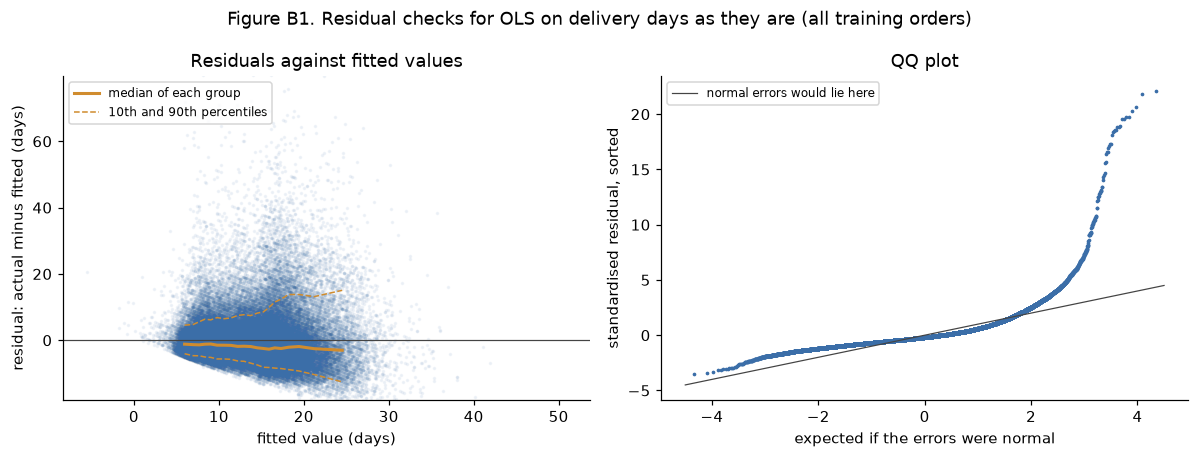

left panel: 142 orders with a residual below -17.9 or above 79.7 days, the 0.1st and 99.9th percentiles, lie off the chart; every other check uses all orders
orders whose fitted value is below zero days, which no delivery can take: 8
spread between the 10th and 90th percentiles: 8.62 days in the group with the lowest fitted values, 27.62 in the group with the highest
skewness of the residuals: 4.85 (0 for a symmetric spread)
Breusch-Pagan test: statistic 625, p-value below 0.001 (a small value means the spread is uneven)


In [31]:
from scipy import stats
from statsmodels.stats.diagnostic import het_breuschpagan

def residual_checks(fit, title, unit):
    """Recipe step 7 for a fitted statsmodels OLS: residuals against fitted values, a QQ plot of
    the standardised residuals, and the Breusch-Pagan test for uneven spread."""
    fitted, residual = fit.fittedvalues.to_numpy(), fit.resid.to_numpy()
    bands = pd.qcut(fitted, 20)                        # twenty equal-sized groups of orders
    by_band = pd.DataFrame({"fitted": fitted, "residual": residual}).groupby(bands, observed=True)
    centre, low, mid, high = (by_band["fitted"].median(), by_band["residual"].quantile(0.1),
                              by_band["residual"].median(), by_band["residual"].quantile(0.9))

    fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
    lo_cut, hi_cut = np.quantile(residual, [0.001, 0.999])
    axes[0].scatter(fitted, residual, s=2, alpha=0.06, color=BLUE, rasterized=True)
    axes[0].plot(centre, mid, color=AMBER, lw=2, label="median of each group")
    axes[0].plot(centre, low, color=AMBER, lw=1, ls="--", label="10th and 90th percentiles")
    axes[0].plot(centre, high, color=AMBER, lw=1, ls="--")
    axes[0].axhline(0, color="#444", lw=0.8)
    axes[0].set_ylim(lo_cut, hi_cut)
    axes[0].set_xlabel(f"fitted value ({unit})")
    axes[0].set_ylabel(f"residual: actual minus fitted ({unit})")
    axes[0].set_title("Residuals against fitted values")
    axes[0].legend(fontsize=8, loc="upper left")

    z = np.sort((residual - residual.mean()) / residual.std())
    normal = stats.norm.ppf((np.arange(1, len(z) + 1) - 0.5) / len(z))
    axes[1].scatter(normal, z, s=2, color=BLUE, rasterized=True)
    axes[1].plot([-4.5, 4.5], [-4.5, 4.5], color="#444", lw=0.8, label="normal errors would lie here")
    axes[1].set_xlabel("expected if the errors were normal")
    axes[1].set_ylabel("standardised residual, sorted")
    axes[1].set_title("QQ plot")
    axes[1].legend(fontsize=8, loc="upper left")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

    outside = int(((residual < lo_cut) | (residual > hi_cut)).sum())
    lm, lm_p, _, _ = het_breuschpagan(residual, fit.model.exog)
    print(f"left panel: {outside} orders with a residual below {lo_cut:.1f} or above {hi_cut:.1f} {unit}, "
          f"the 0.1st and 99.9th percentiles, lie off the chart; every other check uses all orders")
    # log(1 + days) is below zero exactly when days are, so this test suits both versions of the target.
    print(f"orders whose fitted value is below zero days, which no delivery can take: {int((fitted < 0).sum()):,}")
    print(f"spread between the 10th and 90th percentiles: {high.iloc[0] - low.iloc[0]:.2f} {unit} in the group "
          f"with the lowest fitted values, {high.iloc[-1] - low.iloc[-1]:.2f} in the group with the highest")
    print(f"skewness of the residuals: {stats.skew(residual):.2f} (0 for a symmetric spread)")
    print(f"Breusch-Pagan test: statistic {lm:,.0f}, p-value "
          f"{'below 0.001' if lm_p < 0.001 else f'{lm_p:.3f}'} (a small value means the spread is uneven)")

residual_checks(ols, "Figure B1. Residual checks for OLS on delivery days as they are (all training orders)", "days")


The raw-days model fails two of the three checks:

- **spread:** the band between the 10th and 90th percentiles is 8.62 days wide for the lowest
  estimates and 27.62 for the highest, about three times as wide. The Breusch–Pagan test agrees
  (p below 0.001).
- **shape:** the QQ plot bends sharply upwards on the right. A few orders take far longer than their
  estimate, and the residuals have a skewness of 4.85.
- **pattern:** roughly passes. The median line stays close to zero across the range, so a straight
  line describes the relationship reasonably well.

Eight orders get an estimate below zero days, a sign that a straight line on raw days does not suit
a quantity that cannot be negative. Part A showed that a log scale makes delivery days almost
symmetric.


### Log delivery days

The same columns are now fitted to log(1 + delivery days), and the same checks are drawn
(Figure B2). On this scale a residual is a proportion rather than a number of days: a residual of
0.5 stretches a 5-day estimate to about 9 days, and a 20-day estimate to about 34.


OLS on log(1 + delivery days): R² 0.380, adjusted R² 0.379 (measured on log days, so not comparable with the R² in Table B7)


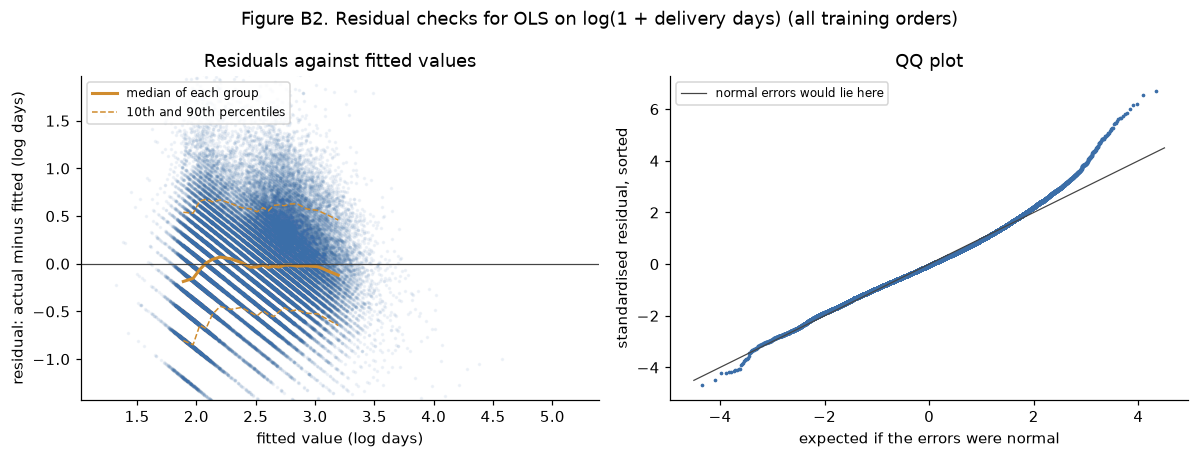

left panel: 142 orders with a residual below -1.4 or above 2.0 log days, the 0.1st and 99.9th percentiles, lie off the chart; every other check uses all orders
orders whose fitted value is below zero days, which no delivery can take: 0
spread between the 10th and 90th percentiles: 1.35 log days in the group with the lowest fitted values, 1.11 in the group with the highest
skewness of the residuals: 0.38 (0 for a symmetric spread)
Breusch-Pagan test: statistic 2,156, p-value below 0.001 (a small value means the spread is uneven)


In [32]:
# The same columns, now fitted to log(1 + delivery days), the log_target defined in Section B2.
ols_log = OLS(log_target, add_constant(X_train)).fit()
print(f"OLS on log(1 + delivery days): R² {ols_log.rsquared:.3f}, adjusted R² {ols_log.rsquared_adj:.3f} "
      f"(measured on log days, so not comparable with the R² in Table B7)")

residual_checks(ols_log, "Figure B2. Residual checks for OLS on log(1 + delivery days) (all training orders)",
                "log days")


The log version passes the checks the raw version failed:

- **spread:** the band is 1.35 log days wide for the lowest estimates and 1.11 for the highest,
  roughly level, where the raw band more than tripled;
- **shape:** the QQ plot follows the diagonal except at the far ends, and the skewness of the
  residuals falls from 4.85 to 0.38;
- **pattern:** the median line stays close to zero.

No order gets an estimate below zero days. The diagonal stripes come from delivery days being whole
numbers.

The Breusch–Pagan test still finds uneven spread (p below 0.001). It checks the spread against all
the columns, not only the estimate, so the spread may still differ between kinds of orders, for
example between states. The grouped standard errors, with 2,240 sellers and 70 weeks, allow for this.

Figure B3 puts the two bands side by side. Each band's width is divided by that model's average
width, so days and log days share one axis; a flat line at 1 means an even spread.


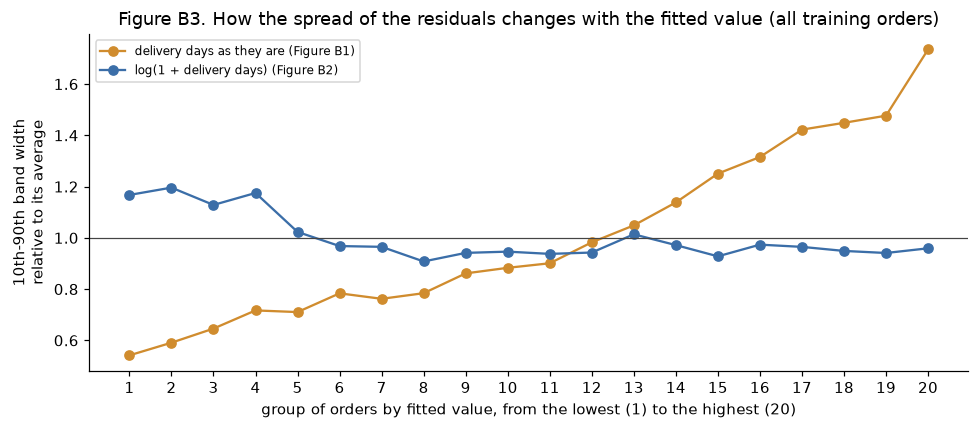

delivery days as they are (Figure B1): relative width 0.54 in the lowest group and 1.74 in the highest; widest group 3.2 times the narrowest
log(1 + delivery days) (Figure B2): relative width 1.17 in the lowest group and 0.96 in the highest; widest group 1.3 times the narrowest


In [33]:
# The same twenty groups as in Figures B1 and B2. Each model's band width is divided by its own
# average, so days and log days can share one axis: a flat line means an even spread.
fig, ax = plt.subplots(figsize=(9, 4))
summary = []
for fit, colour, label in [(ols, AMBER, "delivery days as they are (Figure B1)"),
                           (ols_log, BLUE, "log(1 + delivery days) (Figure B2)")]:
    fitted, residual = fit.fittedvalues.to_numpy(), fit.resid.to_numpy()
    by_band = pd.Series(residual).groupby(pd.qcut(fitted, 20), observed=True)
    width = (by_band.quantile(0.9) - by_band.quantile(0.1)).to_numpy()
    relative = width / width.mean()
    ax.plot(range(1, len(relative) + 1), relative, marker="o", color=colour, label=label)
    summary.append(f"{label}: relative width {relative[0]:.2f} in the lowest group and "
                   f"{relative[-1]:.2f} in the highest; widest group "
                   f"{relative.max() / relative.min():.1f} times the narrowest")
ax.axhline(1, color="#444", lw=0.8)
ax.set_xticks(range(1, 21))
ax.set_xlabel("group of orders by fitted value, from the lowest (1) to the highest (20)")
ax.set_ylabel("10th-90th band width\nrelative to its average")
ax.set_title("Figure B3. How the spread of the residuals changes with the fitted value (all training orders)")
ax.legend(fontsize=8, loc="upper left")
plt.tight_layout()
plt.show()
for line in summary:
    print(line)


On raw days the band grows from 0.54 in the lowest group to 1.74 in the highest. Its widest group is
3.2 times its narrowest. On log days the band is 1.17 in the lowest group and 0.96 in the highest,
and its widest group is 1.3 times its narrowest.

So the log version comes much closer to the even spread that OLS assumes.


### The largest misses

The QQ plot in Figure B2 bends away from the line at both ends. A standardised residual is a miss
divided by the typical size of a miss; beyond 3, normal errors would place only about one order in
740 on each side. Table B11 compares the orders beyond +3 and below −3 with all orders: how long they
took, what the model estimated, and three possible explanations: a customer in São Paulo, a parcel
staying inside one state, and a seller whose past handling time was above the 99th percentile.


In [34]:
# Standardised residuals of the log-days model; beyond 3 standard deviations counts as extreme.
z = (ols_log.resid - ols_log.resid.mean()) / ols_log.resid.std()
estimate = np.expm1(ols_log.fittedvalues)                  # back from log days to days
slow_handling = train["seller_prior_handling_days"] > train["seller_prior_handling_days"].quantile(0.99)
expected = len(z) * stats.norm.sf(3)                       # orders per tail if the errors were normal

groups = {"all training orders": z.notna(),
          "estimate far too short (residual above +3)": z > 3,
          "estimate far too long (residual below −3)": z < -3}
misses = pd.DataFrame([
    {"orders": int(rows.sum()),
     "expected if errors were normal": np.nan if name.startswith("all") else expected,
     "median actual days": train.loc[rows, TARGET].median(),
     "median estimate, days": estimate[rows].median(),
     "customer in SP (%)": 100 * (train.loc[rows, "customer_state"] == "SP").mean(),
     "same state (%)": 100 * train.loc[rows, "same_state"].mean(),
     "seller handling above 99th pct (%)": 100 * slow_handling[rows].mean()}
    for name, rows in groups.items()], index=list(groups)).rename_axis("orders compared").reset_index()

print("Table B11. The largest misses of OLS on log days, against all training orders")
display(misses.style.format({"orders": "{:,}", "expected if errors were normal": "{:.0f}",
                             "median actual days": "{:.0f}", "median estimate, days": "{:.1f}",
                             "customer in SP (%)": "{:.2f}", "same state (%)": "{:.2f}",
                             "seller handling above 99th pct (%)": "{:.2f}"}, na_rep="")
                .hide(axis="index"))


Table B11. The largest misses of OLS on log days, against all training orders


orders compared,orders,expected if errors were normal,median actual days,"median estimate, days",customer in SP (%),same state (%),seller handling above 99th pct (%)
all training orders,"70,851",,11,11.6,40.44,34.28,0.95
estimate far too short (residual above +3),385,96,57,9.2,50.39,50.91,0.00
estimate far too long (residual below −3),76,96,2,15.7,32.89,34.21,31.58


Where the estimate was far too short, there are 385 orders, against about 96 under normal errors.
They took a median of 57 days, while the model estimated 9.2. Customers in São Paulo made up 50.39%
of them, and same-state parcels 50.91%, against 40.44% and 34.28% of all orders. None came from
sellers whose past handling time was above the 99th percentile. We assume the delay arose after the
seller handed the parcel over, in line with Phase 1, which found most of the extra delay on late
orders is carrier transit.

Where the estimate was far too long, there are 76 orders, fewer than the 96 expected. They arrived
in a median of 2 days, while the model estimated 15.7. Of these, 31.58% came from sellers whose past
handling time was above the 99th percentile, against 0.95% of all orders. The model takes handling
time in days without logging it, so a few very slow past records may make the estimate too long.


### Comparing versions on the validation folds

Table B12 scores four versions of OLS on the four folds, retrained on each fold, alongside the best
baseline:

- delivery days as they are (Figures B1 and B3);
- log days (Figure B2);
- log days with the numeric features on a log scale as well, which Table B1 and the too-long
  estimates in Table B11 point towards;
- the better log version without the payment features, whose timing at checkout is undecided
  (Part A). If they add little, leaving them out lets the model work either way.

Mean MAE decides between versions. "Mean MAE on training months" scores each version on the orders
it learned from, so the gap to the folds shows how much worse it does on months it has not seen.
"Mean bias" is the average signed miss and "median error" the middle one; negative means the
estimates run short.

Turned back into days, a log version aims at the typical (median) order, while the raw version aims
at the average. A few very long deliveries pull the average above the median, so a log version shows
a negative mean bias even when it is right about the typical order; the median error is not pulled
down. For the same reason, bias and RMSE are not directly comparable between the raw and log
versions. MAE is.


In [35]:
from sklearn.linear_model import LinearRegression

def cv_scores(model):
    """Score a full model on the four folds, retraining it on each fold's training months."""
    return validate(lambda fit, check: model.fit(fit[FEATURES], fit[TARGET]).predict(check[FEATURES]))

def training_mae(model):
    """Mean over the folds of the MAE on each fold's own training months, to set against the folds."""
    return np.mean([np.abs(model.fit(train.iloc[fit_rows][FEATURES], train.iloc[fit_rows][TARGET])
                                .predict(train.iloc[fit_rows][FEATURES])
                           - train[TARGET].iloc[fit_rows]).mean()
                    for fit_rows, _ in folds])

PAYMENT = ["payment_type", "max_installments"]
VERSIONS = {"OLS, delivery days as they are":  {},
            "OLS, log days":                   {"log_target": True},
            "OLS, log days and log features":  {"log_target": True, "log_features": True}}
results = {name: cv_scores(build(LinearRegression(), **options)) for name, options in VERSIONS.items()}

# The payment features are then dropped from whichever log version scored the lower mean MAE.
better = min(list(VERSIONS)[1:], key=lambda name: results[name]["MAE"].mean())
VERSIONS[f"{better}, without the payment features"] = {**VERSIONS[better], "leave_out": PAYMENT}
results[f"{better}, without the payment features"] = cv_scores(
    build(LinearRegression(), **VERSIONS[better], leave_out=PAYMENT))
in_training = {name: training_mae(build(LinearRegression(), **options)) for name, options in VERSIONS.items()}

rows = {"baseline: median by customer state and same state": cv["median by customer state and same state"],
        **results}
fold_table = pd.DataFrame([
    {"version": name, **{f"MAE fold {k}": s.loc[k, "MAE"] for k in s.index},
     "mean MAE": s["MAE"].mean(), "mean MAE on training months": in_training.get(name, np.nan),
     "mean RMSE": s["RMSE"].mean(), "mean R²": s["R²"].mean(),
     "mean bias": s["bias"].mean(), "median error": s["median error"].mean()}
    for name, s in rows.items()])

print("Table B12. Versions of OLS scored on the four validation folds, in days, with the best baseline "
      "for reference")
display(fold_table.style.format({c: "{:.3f}" for c in fold_table.columns if c != "version"}, na_rep="")
                  .hide(axis="index"))


Table B12. Versions of OLS scored on the four validation folds, in days, with the best baseline for reference


version,MAE fold 1,MAE fold 2,MAE fold 3,MAE fold 4,mean MAE,mean MAE on training months,mean RMSE,mean R²,mean bias,median error
baseline: median by customer state and same state,4.158,6.651,6.623,5.889,5.830,,9.485,0.100,-3.270,-1.125
"OLS, delivery days as they are",4.131,6.140,6.221,5.710,5.550,4.784,8.916,0.203,-2.029,-0.024
"OLS, log days",3.984,6.399,6.533,5.656,5.643,4.626,9.283,0.138,-3.231,-1.133
"OLS, log days and log features",3.894,6.246,6.379,5.512,5.508,4.526,9.149,0.163,-3.089,-0.941
"OLS, log days and log features, without the payment features",3.907,6.256,6.385,5.519,5.517,4.541,9.148,0.163,-3.075,-0.944


Every OLS version beats the baseline on every fold. The chosen version, the last row, has a mean MAE
of 5.517 days against the baseline's 5.830, 0.313 days better.

Raw days against log days with log features:

| Evidence | Raw days | Log days, log features | Favours |
|---|---|---|---|
| mean MAE on the folds | 5.550 | 5.508 | tie: log leads by 0.042, but wins two folds and loses two |
| mean RMSE | 8.916 | 9.149 | raw days (aims at the average) |
| mean R² | 0.203 | 0.163 | raw days (aims at the average) |
| mean bias | −2.029 | −3.089 | raw days (aims at the average) |
| median error | −0.024 | −0.941 | raw days (partly from aiming higher) |
| mean MAE on training months | 4.784 | 4.526 | log days, on months it learned from |
| residual checks (Figures B1–B2) | fails spread and shape | passes | log days, on months it learned from |

OLS on log days with log features, without the payment features, is chosen. From here on it is called
Log OLS. On the folds it ties with raw days on mean MAE, the measure that decides between versions,
and it is narrowly lower. With the folds tied, three points settle it:

- it cannot give an impossible estimate: raw days gives 8 orders an estimate below zero days, log
  days none;
- on the months it learned from, its misses are evenly spread on the log scale (Figure B3), so one
  multiplier, the promise margin, suits short and long estimates alike;
- the four measures that favour raw days mostly reward aiming at the average order, and the promise
  margin offsets that kind of shortfall anyway.

Every version runs short on average. Turning a log estimate back with exp() gives roughly the median
order rather than the average, so the log versions run shorter. A smearing correction (Duan, 1983)
would raise their estimates. It is not applied. Like the promise margin, it multiplies (1 + estimate)
by a fixed factor, so the margin found on the folds would simply come out smaller. It would also move
the estimates towards the average, which would likely raise the MAE.

Leaving out the payment features costs only 0.009 days of mean MAE, 5.517 against 5.508. As they add
so little, we take the cautious view and assume the payment details are not known at checkout, so
the chosen version leaves them out.


### Shuffled folds against time-ordered folds

The Phase 1 literature review warned that random k-fold cross-validation on time-ordered data leaks
information: a model can learn from later months and be checked on earlier ones, which overstates
how well it will do (Kapoor and Narayanan, 2023). Table B13 tests this on Log OLS, scored
twice:

- with shuffled 4-fold cross-validation (seed 42): orders are dealt into four random groups, and each
  group is checked by a model trained on the other three, whatever their months;
- with the time-ordered folds of Table B4.

The last column shows how far the bias moves from fold to fold. The comparison is not exactly
like-for-like: the shuffled folds also check January to August 2017, and they train on more orders.


In [36]:
from sklearn.model_selection import KFold

# The version chosen from Table B12, scored again with ordinary shuffled 4-fold cross-validation.
CHOSEN = f"{better}, without the payment features"
chosen = build(LinearRegression(), **VERSIONS[CHOSEN])
shuffled = KFold(n_splits=4, shuffle=True, random_state=RANDOM_SEED)
shuffled_scores = pd.DataFrame(
    [scores(train[TARGET].iloc[check_rows].to_numpy(),
            chosen.fit(train.iloc[fit_rows][FEATURES], train.iloc[fit_rows][TARGET])
                  .predict(train.iloc[check_rows][FEATURES]))
     for fit_rows, check_rows in shuffled.split(train)], index=range(1, 5))

compare = pd.DataFrame([
    {"folds": name, **{f"MAE fold {k}": s.loc[k, "MAE"] for k in s.index},
     "mean MAE": s["MAE"].mean(), "mean bias": s["bias"].mean(),
     "bias, lowest to highest fold": f"{s['bias'].min():+.3f} to {s['bias'].max():+.3f}"}
    for name, s in {"shuffled 4-fold (seed 42), any order checks any other": shuffled_scores,
                    "time-ordered, Table B4": results[CHOSEN]}.items()])

print(f"Table B13. Log OLS ({CHOSEN}) scored with shuffled and with time-ordered folds, in days")
display(compare.style.format({c: "{:.3f}" for c in compare.columns
                              if c.startswith("MAE") or c.startswith("mean")}).hide(axis="index"))

# The same version fitted and scored on all training orders, to tell overfitting apart from a
# change between periods.
fitted_all = build(LinearRegression(), **VERSIONS[CHOSEN]).fit(train[FEATURES], train[TARGET])
print(f"MAE of Log OLS on the orders it learned from (all training orders): "
      f"{np.abs(fitted_all.predict(train[FEATURES]) - train[TARGET]).mean():.3f}; on unseen orders from "
      f"the same periods (shuffled): {shuffled_scores['MAE'].mean():.3f}; on unseen later months "
      f"(time-ordered): {results[CHOSEN]['MAE'].mean():.3f}")


Table B13. Log OLS (OLS, log days and log features, without the payment features) scored with shuffled and with time-ordered folds, in days


folds,MAE fold 1,MAE fold 2,MAE fold 3,MAE fold 4,mean MAE,mean bias,"bias, lowest to highest fold"
"shuffled 4-fold (seed 42), any order checks any other",5.119,5.307,5.063,5.137,5.156,-1.521,-1.687 to -1.346
"time-ordered, Table B4",3.907,6.256,6.385,5.519,5.517,-3.075,-4.604 to -0.955


MAE of Log OLS on the orders it learned from (all training orders): 5.150; on unseen orders from the same periods (shuffled): 5.156; on unseen later months (time-ordered): 5.517


With shuffled folds the mean MAE is 5.156 days, against 5.517 with the time-ordered folds. Shuffling
makes Log OLS look 0.361 days better. It also hides the drift. Under shuffling the bias
ranges from −1.687 to −1.346, while on the time-ordered folds it ranges from −4.604 to −0.955.

The line under the table separates two causes. Log OLS has an MAE of 5.150 days on the
orders it learned from, 5.156 on unseen orders from the same periods, and 5.517 on unseen later
months. The first two are almost equal, so it shows no sign of overfitting. We assume the extra 0.361
days on later months comes mostly from drift, though part may come from the other differences between
the folds noted above.


### Why the estimates run short in some periods

Table B12 found Log OLS short at the median. Table B14 looks at each fold on its own: the
model's median estimate for the check months, beside the median delivery time in the fold's training
months and in its check months. If the model kept up with changing conditions, its median estimate
would rise and fall with the check months' median.


In [37]:
# Log OLS, fold by fold: how fast the training and check months really were, and what
# the model estimated for the check months.
drift_rows = []
for k, ((fit_rows, check_rows), (first, last)) in enumerate(zip(folds, VALIDATION_MONTHS), start=1):
    fit, check = train.iloc[fit_rows], train.iloc[check_rows]
    estimate = chosen.fit(fit[FEATURES], fit[TARGET]).predict(check[FEATURES])
    error = estimate - check[TARGET].to_numpy()
    drift_rows.append({"fold": k, "checks on": f"{first} to {last}",
                       "median days, training months": fit[TARGET].median(),
                       "median days, check months": check[TARGET].median(),
                       "median estimate": np.median(estimate),
                       "median error": np.median(error),
                       "mean bias": error.mean()})
drift = pd.DataFrame(drift_rows)

print("Table B14. Log OLS fold by fold: real delivery times against its estimates, in days")
display(drift.style.format({"median days, training months": "{:.0f}", "median days, check months": "{:.0f}",
                            "median estimate": "{:.2f}", "median error": "{:+.2f}", "mean bias": "{:+.2f}"})
             .hide(axis="index"))
print(f"median estimate across the four check periods: {drift['median estimate'].min():.2f} to "
      f"{drift['median estimate'].max():.2f} days; median actual: {drift['median days, check months'].min():.0f} "
      f"to {drift['median days, check months'].max():.0f} days")


Table B14. Log OLS fold by fold: real delivery times against its estimates, in days


fold,checks on,"median days, training months","median days, check months",median estimate,median error,mean bias
1,2017-09 to 2017-10,10,10,10.29,+0.24,-0.95
2,2017-11 to 2017-12,10,13,10.26,-2.06,-4.48
3,2018-01 to 2018-02,11,13,10.51,-2.11,-4.60
4,2018-03 to 2018-04,11,11,11.26,+0.15,-2.26


median estimate across the four check periods: 10.26 to 11.26 days; median actual: 10 to 13 days


Log OLS's median estimate stays between 10.26 and 11.26 days across the four folds, while the check
months' median ranges from 10 to 13. In folds 1 and 4 the check months have the same median as the
training months, and its median errors are +0.24 and +0.15 days. In folds 2 and 3 the check-month
median rises to 13 days, from 10 and 11, and its median errors are −2.06 and −2.11, about two days
short. Its mean bias is also largest in these two folds, at −4.48 and −4.60.

None of its 17 features describes how fast deliveries are going across all sellers in the weeks
before a purchase. The closest is the peak-season flag, which marks November and December only. Fold
2 has no November or December orders in the months it learns from, so the flag has nothing to learn
from there. Fold 3 checks January and February 2018, which have the same 13-day median as fold 2 but
are not flagged.

A feature that measures recent delivery times might let the estimate follow such changes.


### Trying to give the model recent conditions

Table B14 found Log OLS about two days short at the median in folds 2 and 3, where the check months
had a higher median than the months it learned from. Table B15 adds one measure of recent conditions
at a time, each computed from what Olist had already seen before the day of purchase:

- the median delivery time of the orders delivered in the last 14, 28 or 56 days;
- the number of orders placed per day in the last 7 or 14 days.

A candidate is judged on the median error in folds 2 and 3 as well as on mean MAE. One that lowers
mean MAE but leaves most of the shortfall in those folds is not added.

"Empty" is the share of orders with fewer than 30 recent deliveries to measure; the pipeline fills
these with that measure's median. The last column lists each fold's median error, in order.


In [38]:
# Candidate measures of recent conditions, computed for each training order from what Olist had
# already seen before the day of purchase. They are tested here; none is added to the features.
DATES = ["order_purchase_timestamp", "order_delivered_customer_date"]
history = pd.read_csv(PROCESSED / "order_level.csv", usecols=["order_id", "is_delivered_complete"] + DATES,
                      parse_dates=DATES)
delivered = history.loc[history["is_delivered_complete"].astype(bool)].copy()
delivered["day"]  = delivered["order_delivered_customer_date"].dt.normalize()
delivered["took"] = (delivered["day"] - delivered["order_purchase_timestamp"].dt.normalize()).dt.days
delivered = delivered.sort_values("day")
delivery_day, delivery_took = delivered["day"].to_numpy(), delivered["took"].to_numpy()
placed = np.sort(history["order_purchase_timestamp"].to_numpy())

bought = train["order_id"].map(history.set_index("order_id")["order_purchase_timestamp"])
purchase_days = np.sort(bought.dt.normalize().unique())

def recent_median(window):
    """Median delivery time of the orders delivered in the `window` days before the day of
    purchase, left empty when fewer than 30 were delivered in that time."""
    lo = np.searchsorted(delivery_day, purchase_days - np.timedelta64(window, "D"), side="left")
    hi = np.searchsorted(delivery_day, purchase_days, side="left")     # strictly before the purchase day
    assert all(delivery_day[h - 1] < d for h, d in zip(hi, purchase_days) if h > 0)
    by_day = {d: np.median(delivery_took[a:b]) if b - a >= 30 else np.nan
              for d, a, b in zip(purchase_days, lo, hi)}
    return bought.dt.normalize().map(by_day).to_numpy()

def recent_volume(window):
    """Orders placed per day in the `window` days before the moment of purchase."""
    t = bought.to_numpy()
    return (np.searchsorted(placed, t, side="left")
            - np.searchsorted(placed, t - np.timedelta64(window, "D"), side="left")) / window

CANDIDATES_RECENT = {"median delivery, deliveries in the last 14 days": recent_median(14),
                     "median delivery, deliveries in the last 28 days": recent_median(28),
                     "median delivery, deliveries in the last 56 days": recent_median(56),
                     "orders placed per day, last 7 days": recent_volume(7),
                     "orders placed per day, last 14 days": recent_volume(14)}

def fold_line(s):
    return " / ".join(f"{v:+.2f}" for v in s["median error"])

rows = [{"candidate added": "none (Log OLS)", "empty": "",
         **{f"MAE fold {k}": v for k, v in results[CHOSEN]["MAE"].items()},
         "mean MAE": results[CHOSEN]["MAE"].mean(), "median error, folds 1 to 4": fold_line(results[CHOSEN])}]
for i, (name, values) in enumerate(CANDIDATES_RECENT.items()):
    column = f"recent_{i}"
    with_candidate = train.assign(**{column: values})
    model = build(LinearRegression(), **VERSIONS[CHOSEN], add=[column])
    s = pd.DataFrame([scores(with_candidate[TARGET].iloc[c].to_numpy(),
                             model.fit(with_candidate.iloc[f][FEATURES + [column]], with_candidate.iloc[f][TARGET])
                                  .predict(with_candidate.iloc[c][FEATURES + [column]]))
                      for f, c in folds], index=range(1, len(folds) + 1))
    rows.append({"candidate added": name, "empty": f"{np.isnan(values).mean():.2%}",
                 **{f"MAE fold {k}": v for k, v in s["MAE"].items()},
                 "mean MAE": s["MAE"].mean(), "median error, folds 1 to 4": fold_line(s)})

print("Table B15. Log OLS with one measure of recent conditions added, scored on the four folds, in days")
display(pd.DataFrame(rows).style.format({c: "{:.3f}" for c in ["MAE fold 1", "MAE fold 2", "MAE fold 3",
                                                               "MAE fold 4", "mean MAE"]})
          .hide(axis="index"))


Table B15. Log OLS with one measure of recent conditions added, scored on the four folds, in days


candidate added,empty,MAE fold 1,MAE fold 2,MAE fold 3,MAE fold 4,mean MAE,"median error, folds 1 to 4"
none (Log OLS),,3.907,6.256,6.385,5.519,5.517,+0.24 / -2.06 / -2.11 / +0.15
"median delivery, deliveries in the last 14 days",0.19%,3.906,6.218,6.337,5.483,5.486,+0.22 / -1.93 / -1.94 / +0.61
"median delivery, deliveries in the last 28 days",0.19%,3.907,6.250,6.322,5.513,5.498,+0.24 / -2.05 / -1.85 / +0.81
"median delivery, deliveries in the last 56 days",0.19%,3.907,6.255,6.384,5.667,5.553,+0.21 / -2.05 / -2.10 / +1.33
"orders placed per day, last 7 days",0.00%,3.898,6.577,6.393,5.520,5.597,-0.09 / -2.70 / -2.12 / +0.74
"orders placed per day, last 14 days",0.00%,3.896,6.510,6.415,5.518,5.585,-0.02 / -2.59 / -2.18 / +0.75


No candidate removes the shortfall. The 14-day median delivery gives the lowest mean MAE, 5.486 days
against 5.517. It narrows the shortfall in folds 2 and 3 by only 0.13 and 0.17 days, to −1.93 and
−1.94. It also moves fold 4 further over, from +0.15 to +0.61. The 28-day window lowers mean MAE to
5.498. It narrows fold 3 to −1.85 but leaves fold 2 at −2.05, and moves fold 4 to +0.81. The 56-day
window raises mean MAE to 5.553.

Order volume raises mean MAE, to 5.597 for the 7-day window and 5.585 for the 14-day window. It
deepens the shortfall in fold 2, to −2.70 and −2.59. We assume this is because order volume grew over
the training months (Figure A1), so the measure partly tracks the passing of time.

The 14-day median's gain of 0.031 days is larger than the 0.009 days that dropping the payment
features cost, but it leaves most of the shortfall. By the rule above, no candidate is added.


### Regularised regression: Ridge and Lasso

Ridge and Lasso are OLS with a penalty on the size of the coefficients. Ridge shrinks them all
towards zero, and Lasso can set some exactly to zero. The penalty can steady overlapping
coefficients, such as distance and the state features (Table B8), and can stop a model with many
columns from fitting noise. The strength of each penalty, alpha, is tuned on the four folds:

- Ridge at 13 values, from 0.01 to 10,000;
- Lasso at 9 values, from 0.00001 to 0.1.

Both use Log OLS's features but keep every dummy column, so the result does not depend on which
value is left out as the reference.

Figure B4 plots mean MAE against alpha, with Log OLS as a dashed line. Table B16 sets the best alpha
of each against Log OLS, fold by fold. A regularised version replaces Log OLS only if it lowers mean
MAE by more than a negligible amount.


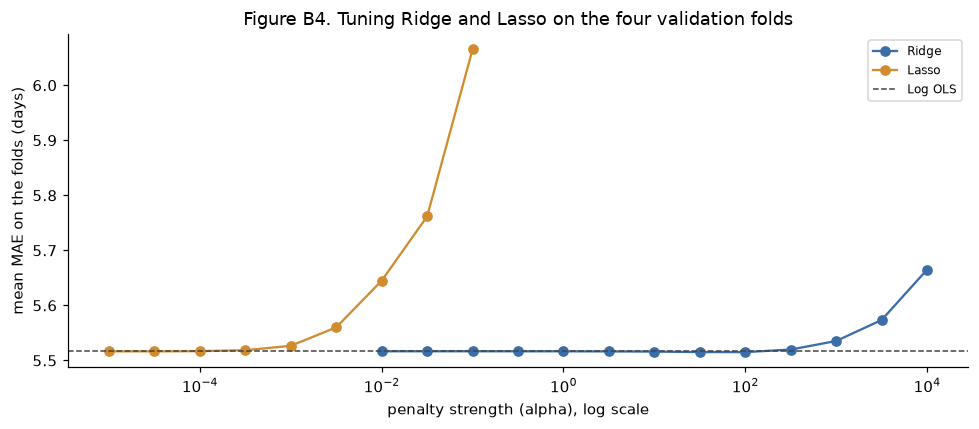

Table B16. The best Ridge and Lasso settings against OLS on the four folds, in days


model,best alpha,MAE fold 1,MAE fold 2,MAE fold 3,MAE fold 4,mean MAE,gain over OLS
Log OLS,,3.9069,6.2560,6.3852,5.5185,5.5167,0.0000
Lasso,3.2e-05,3.9046,6.2554,6.3857,5.5203,5.5165,0.0002
Ridge,1e+02,3.9018,6.2456,6.3843,5.5290,5.5152,0.0015


Lasso at its best alpha, fitted on all training orders, sets 6 of its 80 coefficients to zero


In [39]:
from sklearn.linear_model import Lasso, Ridge

# Log OLS with every dummy kept: with a penalty, dropping one value per feature would
# change the estimates, so no reference value is dropped here.
regularised = {**VERSIONS[CHOSEN], "drop_reference": False}
GRIDS = {"Ridge": (Ridge, np.logspace(-2, 4, 13)),
         "Lasso": (Lasso, np.logspace(-5, -1, 9))}

def penalised(family, alpha):
    Estimator = GRIDS[family][0]
    return Estimator(alpha=alpha, **({"max_iter": 10_000} if family == "Lasso" else {}))

tuning = pd.DataFrame([{"family": family, "alpha": alpha, "scores": cv_scores(build(penalised(family, alpha), **regularised))}
                       for family, (_, alphas) in GRIDS.items() for alpha in alphas])
tuning["mean MAE"] = tuning["scores"].map(lambda s: s["MAE"].mean())
ols_mae = results[CHOSEN]["MAE"].mean()

fig, ax = plt.subplots(figsize=(9, 4))
for family, colour in [("Ridge", BLUE), ("Lasso", AMBER)]:
    t = tuning[tuning["family"] == family]
    ax.plot(t["alpha"], t["mean MAE"], marker="o", color=colour, label=family)
ax.axhline(ols_mae, color="#444", ls="--", lw=1, label="Log OLS")
ax.set_xscale("log")
ax.set_xlabel("penalty strength (alpha), log scale")
ax.set_ylabel("mean MAE on the folds (days)")
ax.set_title("Figure B4. Tuning Ridge and Lasso on the four validation folds")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

best = tuning.loc[tuning.groupby("family")["mean MAE"].idxmin()]
lasso_alpha = best.loc[best["family"] == "Lasso", "alpha"].iloc[0]
lasso_fit = build(penalised("Lasso", lasso_alpha), **regularised).fit(train[FEATURES], train[TARGET])
zeros = int((lasso_fit.regressor_[-1].coef_ == 0).sum()), len(lasso_fit.regressor_[-1].coef_)

rows = [{"model": "Log OLS", "best alpha": "",
         **{f"MAE fold {k}": v for k, v in results[CHOSEN]["MAE"].items()}, "mean MAE": ols_mae,
         "gain over OLS": 0.0}]
for _, r in best.iterrows():
    rows.append({"model": r["family"], "best alpha": f"{r['alpha']:.2g}",
                 **{f"MAE fold {k}": v for k, v in r["scores"]["MAE"].items()},
                 "mean MAE": r["mean MAE"], "gain over OLS": ols_mae - r["mean MAE"]})
print("Table B16. The best Ridge and Lasso settings against OLS on the four folds, in days")
display(pd.DataFrame(rows).style.format({c: "{:.4f}" for c in ["MAE fold 1", "MAE fold 2", "MAE fold 3",
                                                               "MAE fold 4", "mean MAE", "gain over OLS"]})
          .hide(axis="index"))
print(f"Lasso at its best alpha, fitted on all training orders, sets {zeros[0]} of its {zeros[1]} coefficients to zero")


Both gains are negligible: at their best alpha, Ridge lowers mean MAE by 0.0015 days and Lasso by
0.0002. Ridge is lower on folds 1 to 3 but higher on fold 4. Lasso sets only 6 of its 80 coefficients
to zero, so it finds almost nothing to remove. Steadier coefficients would not change this choice, as
the model is chosen on its estimates, not its coefficients. Log OLS therefore stays.

This matches Table B13, where Log OLS scored 5.156 days on unseen orders from its own periods and
5.150 on the orders it learned from. With so small a gap, a likely reason is that there was little
overfitting for a penalty to correct.


### Quantile regression at the median

OLS makes the squared misses as small as possible. Quantile regression fits a chosen quantile
instead. At the median, q = 0.5, it makes the absolute misses as small as possible. Fitted on log
days, its estimate turned back into days is the median delivery time, the value that MAE rewards. It
is still a straight-line model, in the same family as OLS.

The next cell fits it with Log OLS's features on the same four folds (Table B17). A small adapter lets
statsmodels' QuantReg use the same preparation and scoring. The columns are as in Table B12. QuantReg
replaces Log OLS only if it lowers mean MAE by more than a negligible amount.


In [40]:
from sklearn.base import BaseEstimator, RegressorMixin
from statsmodels.regression.quantile_regression import QuantReg

class QuantileRegression(BaseEstimator, RegressorMixin):
    """statsmodels' QuantReg wrapped so it fits into the same pipeline, folds and scoring as OLS.
    q is the quantile it estimates: 0.5 is the median."""
    def __init__(self, q=0.5):
        self.q = q
    def fit(self, X, y):
        self.result_ = QuantReg(np.asarray(y), add_constant(np.asarray(X), has_constant="add")).fit(
            q=self.q, max_iter=5000)
        return self
    def predict(self, X):
        return self.result_.predict(add_constant(np.asarray(X), has_constant="add"))

# The median of log(1 + days) turned back into days is the median of days, so q = 0.5 on the
# log scale estimates the median delivery time directly.
qr_scores = cv_scores(build(QuantileRegression(q=0.5), **VERSIONS[CHOSEN]))

compare_qr = pd.DataFrame([
    {"model": name, **{f"MAE fold {k}": v for k, v in s["MAE"].items()}, "mean MAE": s["MAE"].mean(),
     "median error, folds 1 to 4": fold_line(s), "mean bias": s["bias"].mean()}
    for name, s in {"Log OLS": results[CHOSEN],
                    "QuantReg at the median, same configuration": qr_scores}.items()])

print("Table B17. Quantile regression at the median against OLS on the four folds, in days")
display(compare_qr.style.format({c: "{:.3f}" for c in ["MAE fold 1", "MAE fold 2", "MAE fold 3", "MAE fold 4",
                                                       "mean MAE", "mean bias"]}).hide(axis="index"))
print(f"gain in mean MAE over OLS: {results[CHOSEN]['MAE'].mean() - qr_scores['MAE'].mean():.4f} days")


Table B17. Quantile regression at the median against OLS on the four folds, in days


model,MAE fold 1,MAE fold 2,MAE fold 3,MAE fold 4,mean MAE,"median error, folds 1 to 4",mean bias
Log OLS,3.907,6.256,6.385,5.519,5.517,+0.24 / -2.06 / -2.11 / +0.15,-3.075
"QuantReg at the median, same configuration",3.886,6.299,6.465,5.550,5.550,+0.09 / -2.17 / -2.30 / -0.14,-3.294


gain in mean MAE over OLS: -0.0335 days


QuantReg at the median does worse than Log OLS: a mean MAE of 5.550 days against 5.517, a loss of
0.0335 days. It is better on fold 1, at 3.886 against 3.907, and worse on the other three. Its median
error is lower than Log OLS's in all four folds. In folds 2 and 3, where Log OLS already falls short,
this puts it further short: −2.17 and −2.30 against −2.06 and −2.11. We assume the lower estimates
come from the skew of the misses on the log scale (skewness 0.38 for OLS on log days, under Figure
B2). OLS fits the average of log days, and with a longer tail on the late side, the average sits
above the median.

Log OLS stays. Quantile regression is tested again for the promise, where a high quantile can give
each kind of order its own cushion.


## B5. From estimate to promise

The estimates so far aim at the typical order, and Table B12's negative median errors show check
orders taking longer than estimated more often than not. Used as promises, they would often be late,
so a promise needs a cushion. Its length matters too: a promise one day faster raised sales by 0.73%,
but faster promises also raised returns and lowered customer retention (Cui et al., 2024). The success criterion, set in the opening cell, is that at the same late rate as
Olist's quotes, the model's promise must be shorter on average.

The next cell makes that comparison on the 48,854 check orders of the four folds:

- each check order gets an out-of-fold estimate, from a model trained only on its fold's earlier
  months;
- the margin is added on the log scale, which multiplies the estimate by roughly a fixed factor, and
  the result is rounded up to a whole day; the margin is raised until the promises are late as often
  as Olist's quotes on the same orders;
- this is done for Log OLS, and for quantile regression at q = 0.85, 0.90 and 0.95, each with its own
  margin. Log OLS with one margin gives every order the same percentage cushion; a high quantile
  gives each kind of order its own;
- Olist's quotes are also scaled up and down by a single factor, rounded up to whole days, to test
  whether simply lengthening or shortening them would do as well as the model.

A promise is late when the parcel arrives after the promised day. At the same late rate, a shorter
average promise is better, and so are fewer days early for the orders that arrive on time. Table B18
compares the promises at Olist's late rate, and the line under it compares them at Olist's average
promise. Table B19 compares Log OLS with Olist's scaled quotes at several late rates. Figure B5 traces
each trade-off over a range of margins; at the same late rate, a lower curve is better.

Each margin is chosen on the same check orders it is scored on, so every row matches Olist's late
rate by construction. The rows can be compared fairly with each other, but on other months the late
rate could come out higher or lower.


Table B18. Promises at Olist's late rate on the 48,854 check orders of the four folds


promise from,margin,late,average promise,"average days early, on-time orders"
Olist's quote,,9.51%,24.69,12.67
Log OLS,× 2.012,9.51%,23.63,11.42
QuantReg at q = 0.85,× 1.365,9.51%,23.73,11.53
QuantReg at q = 0.90,× 1.223,9.51%,23.86,11.67
QuantReg at q = 0.95,× 1.030,9.51%,24.35,12.19


with the same average promise as Olist, 24.69 days, OLS plus a margin would be late on 8.36% of these orders, against Olist's 9.51%


Table B19. Average promise at the same late rate: OLS plus a margin against Olist's quote scaled, on the check orders, in days, with the multiplier each needs


late rate,Olist's factor,"Olist's quote, scaled",OLS margin,OLS plus a margin,shorter by
5.00%,× 1.240,31.15,× 2.474,29.16,1.98
9.51%,× 0.982,24.69,× 2.012,23.63,1.06
15.00%,× 0.815,20.64,× 1.717,20.08,0.56
20.00%,× 0.720,18.31,× 1.541,17.98,0.33


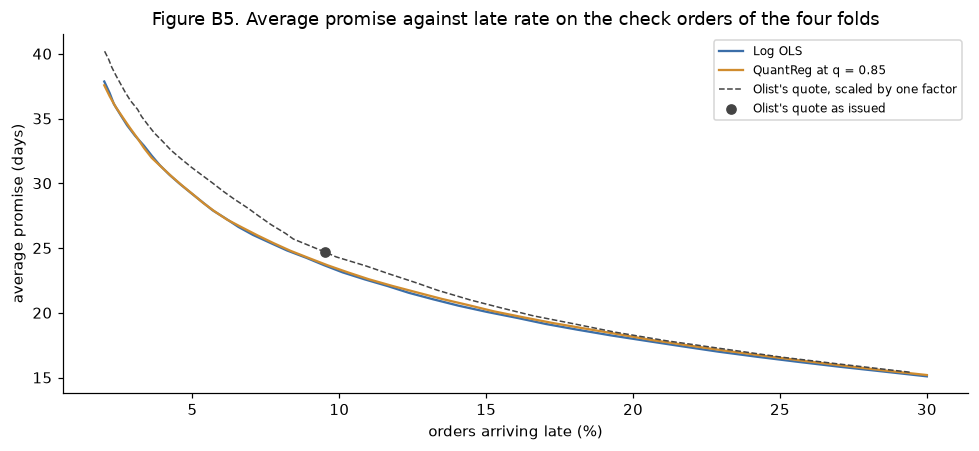

In [41]:
# Out-of-fold estimates: every check order is estimated by a model trained only on earlier months.
check_order = np.concatenate([check_rows for _, check_rows in folds])
actual = train[TARGET].to_numpy()[check_order]
olist = train["order_id"].iloc[check_order].map(quote).to_numpy()

def out_of_fold(model):
    """Log-scale estimates for every check order, each from its own fold's training months."""
    return np.concatenate([np.log1p(model.fit(train.iloc[f][FEATURES], train.iloc[f][TARGET])
                                         .predict(train.iloc[c][FEATURES]))
                           for f, c in folds])

def promise(log_estimate, margin):
    """A promise in whole days: the estimate raised by a log-scale margin, rounded up."""
    return np.ceil(np.expm1(log_estimate + margin))

def late_rate(log_estimate, margin):
    return (actual > promise(log_estimate, margin)).mean()

def margin_for(log_estimate, target):
    """The smallest margin whose late rate is no higher than the target, found by bisection."""
    lo, hi = -2.0, 3.0
    for _ in range(50):
        mid = (lo + hi) / 2
        lo, hi = (mid, hi) if late_rate(log_estimate, mid) > target else (lo, mid)
    return hi

target = (actual > olist).mean()                 # Olist's own late rate on the same check orders
estimates = {"Log OLS": out_of_fold(build(LinearRegression(), **VERSIONS[CHOSEN]))}
for q in (0.85, 0.90, 0.95):
    estimates[f"QuantReg at q = {q:.2f}"] = out_of_fold(build(QuantileRegression(q=q), **VERSIONS[CHOSEN]))

def summary(name, promised, margin_text):
    on_time = actual <= promised
    return {"promise from": name, "margin": margin_text, "late": (~on_time).mean() * 100,
            "average promise": promised.mean(),
            "average days early, on-time orders": (promised - actual)[on_time].mean()}

rows = [summary("Olist's quote", olist, "")]
for name, log_estimate in estimates.items():
    m = margin_for(log_estimate, target)
    rows.append(summary(name, promise(log_estimate, m), f"× {np.exp(m):.3f}"))
promise_table = pd.DataFrame(rows)

print(f"Table B18. Promises at Olist's late rate on the {len(actual):,} check orders of the four folds")
display(promise_table.style.format({"late": "{:.2f}%", "average promise": "{:.2f}",
                                    "average days early, on-time orders": "{:.2f}"}).hide(axis="index"))

# The same comparison the other way round: the late rate of OLS at Olist's average promise.
lo, hi = -2.0, 3.0
for _ in range(50):
    mid = (lo + hi) / 2
    lo, hi = (mid, hi) if promise(estimates["Log OLS"], mid).mean() < olist.mean() else (lo, mid)
print(f"with the same average promise as Olist, {olist.mean():.2f} days, OLS plus a margin would be late on "
      f"{100 * late_rate(estimates['Log OLS'], hi):.2f}% of these orders, against Olist's "
      f"{100 * target:.2f}%")

# Olist's quotes scaled up or down by one factor, rounded up to whole days, give Olist's own
# trade-off curve, so the model can be compared with Olist at any late rate.
def olist_scaled(factor):
    return np.ceil(olist * factor)

def factor_for(target_rate):
    lo, hi = 0.1, 5.0
    for _ in range(50):
        mid = (lo + hi) / 2
        lo, hi = (mid, hi) if (actual > olist_scaled(mid)).mean() > target_rate else (lo, mid)
    return hi

rates = [0.05, target, 0.15, 0.20]
ols_log = estimates["Log OLS"]
curve_compare = pd.DataFrame([
    {"late rate": 100 * r,
     "Olist's factor": factor_for(r), "Olist's quote, scaled": olist_scaled(factor_for(r)).mean(),
     "OLS margin": np.exp(margin_for(ols_log, r)), "OLS plus a margin": promise(ols_log, margin_for(ols_log, r)).mean()}
    for r in rates])
curve_compare["shorter by"] = curve_compare["Olist's quote, scaled"] - curve_compare["OLS plus a margin"]
print("Table B19. Average promise at the same late rate: OLS plus a margin against Olist's quote scaled, "
      "on the check orders, in days, with the multiplier each needs")
display(curve_compare.style.format({"late rate": "{:.2f}%", "Olist's factor": "× {:.3f}",
                                    "Olist's quote, scaled": "{:.2f}", "OLS margin": "× {:.3f}",
                                    "OLS plus a margin": "{:.2f}", "shorter by": "{:.2f}"}).hide(axis="index"))

# The whole trade-off: average promise against late rate, over a range of margins.
best_q = min([n for n in estimates if n.startswith("QuantReg")],
             key=lambda n: promise_table.set_index("promise from").loc[n, "average promise"])
fig, ax = plt.subplots(figsize=(9, 4.2))
for name, colour in [("Log OLS", BLUE), (best_q, AMBER)]:
    margins = np.linspace(margin_for(estimates[name], 0.30), margin_for(estimates[name], 0.02), 40)
    ax.plot([100 * late_rate(estimates[name], m) for m in margins],
            [promise(estimates[name], m).mean() for m in margins], color=colour, label=name)
factors = np.linspace(factor_for(0.30), factor_for(0.02), 40)
ax.plot([100 * (actual > olist_scaled(f)).mean() for f in factors], [olist_scaled(f).mean() for f in factors],
        color="#444", ls="--", lw=1, label="Olist's quote, scaled by one factor")
ax.scatter([100 * target], [olist.mean()], color="#444", zorder=3, label="Olist's quote as issued")
ax.set_xlabel("orders arriving late (%)")
ax.set_ylabel("average promise (days)")
ax.set_title("Figure B5. Average promise against late rate on the check orders of the four folds")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()


On the check orders, Log OLS plus a margin meets the success criterion. At Olist's late rate of
9.51%, its promises average 23.63 days against Olist's 24.69, and on-time orders arrive 11.42 days
early on average against 12.67. With the same average promise as Olist, Log OLS would be late on
8.36% of orders instead of 9.51%.

Scaling Olist's quotes does not close the gap. In Table B19, Log OLS's promise is shorter at all
four late rates, by 1.98 days at 5% late down to 0.33 days at 20%. Olist's factor at 9.51% is 0.982
rather than 1. After rounding up, it gives the same average promise, 24.69 days. The gap narrows as
more orders are allowed to be late. A likely reason is that a strict late rate depends on knowing
which orders are at risk, which is what the model adds; at a loose one, a simple rule such as
scaling Olist's quotes comes close. This has not been tested.

Quantile regression gives slightly longer promises than Log OLS with one margin: 23.73 days at q =
0.85, 23.86 at 0.90 and 24.35 at 0.95, and in Figure B5 the curves for Log OLS and QuantReg at q =
0.85 lie almost on top of each other from 2% to 30% late. A likely reason is that misses on log days
have a similar spread for short and long estimates (Figure B3), so one percentage cushion suits
both.

The cushion is large. To match Olist's late rate, Log OLS roughly doubles its estimate (margin
× 2.012). We assume this reflects how uncertain delivery is at checkout. The margin has to cover
long delays (Table B11) and shifts between periods (Table B14).


# Part C. Trees and the ensemble

This part tries the second family of models: a single decision tree, the family's simplest version
and its baseline, and a random forest. It keeps Part B's ground rules, so the two families can be
compared directly: the same four folds and scores, and Log OLS's 17 features.

**Why trees.** OLS fits one straight-line effect per feature. A tree splits the orders into groups,
one threshold on one feature at a time, so an effect can differ from one group of orders to another.
Grinsztajn et al. (2022) found tree-based models ahead of deep-learning models on tabular data like
this. Both are reasons to test trees.

**How the result is judged.** Between families, the promise decides rather than mean MAE, which chose
between versions of one model in Part B, because the success criterion in the opening cell is about
the promise. Two rules decide, each fixed before the result it judges was computed:

- the random forest replaces Log OLS only if, at Olist's late rate on the check orders, its average
  promise is shorter by more than a negligible amount;
- an equal average of the two families replaces the better single model on the same rule.

A lead that passes is then checked across random seeds before it is trusted.

## C1. Setup

The next cell loads the libraries, the feature lists that Part A saved in `c1_feature_spec.json`, and
the modelling table.


In [42]:
import json
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor

# The notebook lives in notebooks/ and the data in <Phase 2>/data, so step up a level when the
# kernel starts inside notebooks/, which is the VS Code default.
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESSED    = PROJECT_ROOT / "data" / "processed"

spec        = json.loads((PROCESSED / "c1_feature_spec.json").read_text())
TARGET      = spec["target"]
NUMERIC     = spec["numeric"]
BOOLEAN     = spec["boolean"]
CATEGORICAL = spec["categorical"]
FEATURES    = NUMERIC + BOOLEAN + CATEGORICAL
NEGLIGIBLE_DAYS = 0.01   # the rule set before the results: shorter by more than a negligible amount
RANDOM_SEED = spec["random_seed"]
PAYMENT     = ["payment_type", "max_installments"]     # left out, as decided in Table B12

pd.set_option("display.max_columns", 50)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
BLUE, AMBER, GREEN = "#3b6ea8", "#d08c2e", "#4f8a5b"
# A value never seen in a fold's training months is coded as "other" or as all zeros by design.
warnings.filterwarnings("ignore", message="Found unknown categories")

table = pd.read_csv(PROCESSED / "c1_model_table.csv")
train = table.loc[table["split"] == "train"].reset_index(drop=True)
print(f"training orders: {len(train):,}, {train['purchase_month'].min()} to {train['purchase_month'].max()}; "
      f"the test months are not used in this part")


training orders: 70,851, 2017-01 to 2018-04; the test months are not used in this part


## C2. Folds and the OLS benchmark

### The four folds

The next cell rebuilds the four folds of Table B4, as each part runs on its own, and checks that each
fold trains on months before its check months. Its check-order counts match Table B4. It also defines
the scores: MAE, RMSE, R², and the mean and median error, all in days, where an error is the estimate
minus the actual delivery time.


In [43]:
# The same four time-ordered folds as Table B4.
VALIDATION_MONTHS = [("2017-09", "2017-10"), ("2017-11", "2017-12"),
                     ("2018-01", "2018-02"), ("2018-03", "2018-04")]
month = train["purchase_month"]
folds = [(np.flatnonzero(month < first), np.flatnonzero(month.between(first, last)))
         for first, last in VALIDATION_MONTHS]
for fit_rows, check_rows in folds:
    assert month.iloc[fit_rows].max() < month.iloc[check_rows].min()

def scores(actual, predicted):
    """MAE, RMSE, R², and the signed error as a mean (the bias) and as a median, all in days."""
    error = predicted - actual
    return {"MAE": np.abs(error).mean(), "RMSE": np.sqrt((error ** 2).mean()),
            "R²": 1 - (error ** 2).sum() / ((actual - actual.mean()) ** 2).sum(),
            "bias": error.mean(), "median error": np.median(error)}

def cv_scores(model):
    """Score a model on the four folds, retraining it on each fold's training months."""
    return pd.DataFrame([scores(train[TARGET].iloc[c].to_numpy(),
                                np.asarray(model.fit(train.iloc[f][FEATURES], train.iloc[f][TARGET])
                                                .predict(train.iloc[c][FEATURES])))
                         for f, c in folds], index=range(1, len(folds) + 1))

def fold_line(s):
    return " / ".join(f"{v:+.2f}" for v in s["median error"])
print("folds:", [f"{a} to {b}: {len(c):,} check orders" for (a, b), (_, c) in zip(VALIDATION_MONTHS, folds)])


folds: ['2017-09 to 2017-10: 8,628 check orders', '2017-11 to 2017-12: 12,801 check orders', '2018-01 to 2018-02: 13,624 check orders', '2018-03 to 2018-04: 13,801 check orders']


### Preparing the features for trees, and the OLS benchmark rebuilt

The next cell does two things:

- **It prepares the features for trees.** A tree splits on one column at a time, and only the order
  of a column's values matters, so the numeric features are left as they are. Gaps are filled with
  the median. Every value of a category keeps its own yes/no column. Values held by fewer than 1% of
  orders are merged into "other", as in Part B.
- **It rebuilds Log OLS**, and checks that it reproduces Table B12's mean MAE, so both families are
  measured against the same benchmark.


In [44]:
GROUPED   = [c for c in CATEGORICAL if c != "customer_state"]
REFERENCE = {c: train[c].mode()[0] for c in CATEGORICAL}

def name_dummy(feature, value):
    return f"{feature}_{'other' if value == 'infrequent_sklearn' else value}"

def prepare_for_trees():
    """Trees split on one column at a time, so the numeric features need no scaling or logging:
    any rescaling that keeps the order of the values gives the same splits. Gaps are filled with
    the training median, every dummy is kept, and rare values below 1% are merged as in Part B."""
    numeric_cols = [c for c in NUMERIC if c not in PAYMENT]
    grouped_cols = [c for c in GROUPED if c not in PAYMENT]
    return ColumnTransformer([
        ("numeric", SimpleImputer(strategy="median"), numeric_cols),
        ("yes/no",  FunctionTransformer(lambda x: x.astype(float), feature_names_out="one-to-one"), BOOLEAN),
        ("state",   OneHotEncoder(handle_unknown="ignore", sparse_output=False), ["customer_state"]),
        ("grouped", OneHotEncoder(min_frequency=0.01, handle_unknown="infrequent_if_exist",
                                  sparse_output=False, feature_name_combiner=name_dummy), grouped_cols),
    ], verbose_feature_names_out=False)

def tree_model(estimator, log_target):
    pipeline = make_pipeline(prepare_for_trees(), estimator)
    if log_target:
        return TransformedTargetRegressor(pipeline, func=np.log1p, inverse_func=np.expm1)
    return pipeline

# Log OLS from Part B, rebuilt here so the two families can be compared directly:
# log days, log features, reference dummies dropped, payment features left out.
def prepare_for_ols():
    numeric_cols = [c for c in NUMERIC if c not in PAYMENT]
    grouped_cols = [c for c in GROUPED if c not in PAYMENT]
    return ColumnTransformer([
        ("numeric", make_pipeline(SimpleImputer(strategy="median"),
                                  FunctionTransformer(np.log1p, feature_names_out="one-to-one"),
                                  StandardScaler()), numeric_cols),
        ("yes/no",  FunctionTransformer(lambda x: x.astype(float), feature_names_out="one-to-one"), BOOLEAN),
        ("state",   OneHotEncoder(drop=[REFERENCE["customer_state"]], handle_unknown="ignore",
                                  sparse_output=False), ["customer_state"]),
        ("grouped", OneHotEncoder(drop=[REFERENCE[c] for c in grouped_cols], min_frequency=0.01,
                                  handle_unknown="infrequent_if_exist", sparse_output=False,
                                  feature_name_combiner=name_dummy), grouped_cols),
    ], verbose_feature_names_out=False)

ols = TransformedTargetRegressor(make_pipeline(prepare_for_ols(), LinearRegression()),
                                 func=np.log1p, inverse_func=np.expm1)
ols_scores = cv_scores(ols)
assert abs(ols_scores["MAE"].mean() - 5.5167) < 0.0005, "does not reproduce Table B12"
print(f"Log OLS rebuilt: mean MAE {ols_scores['MAE'].mean():.3f} days on the folds, "
      f"as in Table B12; median error by fold {fold_line(ols_scores)}")


Log OLS rebuilt: mean MAE 5.517 days on the folds, as in Table B12; median error by fold +0.24 / -2.06 / -2.11 / +0.15


The rebuilt Log OLS has a mean MAE of 5.517 days and median errors of +0.24, −2.06, −2.11 and +0.15
by fold, the same as Table B12. Every comparison in Part C uses this benchmark.


## C3. A single decision tree

The next cell tunes one decision tree on the four folds, over two settings:

- **maximum depth**, the longest chain of yes/no questions from the top of the tree to a final group,
  at 4, 6, 8, 10, 12 and 16;
- **minimum leaf size**, the fewest orders a final group may hold, at 20, 100, 500, 1,000 and 2,000.

Each of the 30 pairs is fitted on days and on log days, 60 settings in all, since the target's scale
still matters for a tree: each final group's estimate is an average. A tree on log days is turned back
into days before it is scored. Settings are chosen on mean MAE, as in Part B. The promise rule applies
only when the families are compared. Figure C1 plots mean MAE against depth, one line per leaf size,
with Log OLS as a dashed line, and Table C1 lists the five best settings. A deep tree with small final
groups can fit noise in the months it learns from, and its line then rises with depth. Both settings
span a wide range, so the best can be checked to lie inside it.


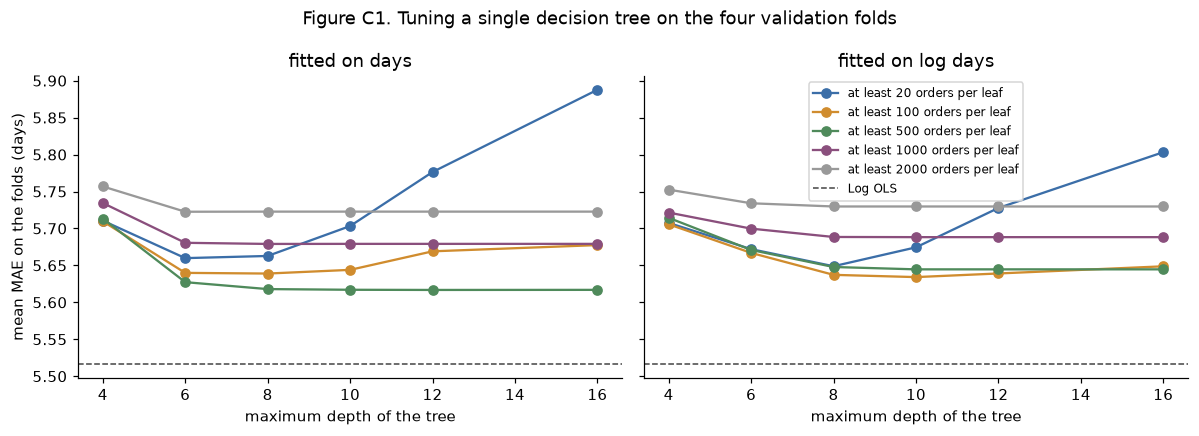

Table C1. The five best decision-tree settings of the 60 tried, on the four folds, in days


target,max depth,min leaf,MAE by fold,mean MAE
days,12,500,4.284 / 6.082 / 6.309 / 5.792,5.617
days,16,500,4.284 / 6.082 / 6.309 / 5.793,5.617
days,10,500,4.284 / 6.082 / 6.308 / 5.794,5.617
days,8,500,4.284 / 6.080 / 6.316 / 5.791,5.618
days,6,500,4.284 / 6.104 / 6.344 / 5.777,5.627


best tree: days, depth 12, at least 500 orders per leaf, mean MAE 5.617 against 5.517 for OLS [93 s]


In [45]:
t0 = time.perf_counter()
LEAVES = (20, 100, 500, 1000, 2000)
TREE_GRID = [(depth, leaf) for depth in (4, 6, 8, 10, 12, 16) for leaf in LEAVES]
tree_rows = []
for log_target in (False, True):
    for depth, leaf in TREE_GRID:
        s = cv_scores(tree_model(DecisionTreeRegressor(max_depth=depth, min_samples_leaf=leaf,
                                                       random_state=RANDOM_SEED), log_target))
        tree_rows.append({"target": "log days" if log_target else "days", "max depth": depth,
                          "min leaf": leaf, "mean MAE": s["MAE"].mean(), "scores": s})
tree_tuning = pd.DataFrame(tree_rows)

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, target_name in zip(axes, ["days", "log days"]):
    for leaf, colour in zip(LEAVES, (BLUE, AMBER, GREEN, "#8a4f7d", "#999999")):
        t = tree_tuning[(tree_tuning["target"] == target_name) & (tree_tuning["min leaf"] == leaf)]
        ax.plot(t["max depth"], t["mean MAE"], marker="o", color=colour, label=f"at least {leaf} orders per leaf")
    ax.axhline(ols_scores["MAE"].mean(), color="#444", ls="--", lw=1, label="Log OLS")
    ax.set_title(f"fitted on {target_name}")
    ax.set_xlabel("maximum depth of the tree")
axes[0].set_ylabel("mean MAE on the folds (days)")
axes[1].legend(fontsize=8)
fig.suptitle("Figure C1. Tuning a single decision tree on the four validation folds")
plt.tight_layout()
plt.show()

best_tree = tree_tuning.loc[tree_tuning["mean MAE"].idxmin()]
top = (tree_tuning.sort_values("mean MAE").head(5)
       .assign(**{"MAE by fold": lambda d: d["scores"].map(lambda s: " / ".join(f"{v:.3f}" for v in s["MAE"]))})
       [["target", "max depth", "min leaf", "MAE by fold", "mean MAE"]])
print(f"Table C1. The five best decision-tree settings of the {len(tree_tuning)} tried, on the four folds, in days")
display(top.style.format({"mean MAE": "{:.3f}"}).hide(axis="index"))
print(f"best tree: {best_tree['target']}, depth {best_tree['max depth']}, at least {best_tree['min leaf']} "
      f"orders per leaf, mean MAE {best_tree['mean MAE']:.3f} against {ols_scores['MAE'].mean():.3f} for OLS "
      f"[{time.perf_counter() - t0:.0f} s]")


No tree reaches the Log OLS line. The best, on days with a depth of 12 and at least 500 orders per
leaf, has a mean MAE of 5.617 days against 5.517.

In Figure C1, with at least 20 orders per leaf, error rises once the tree grows past depth 6 on days
and past depth 8 on log days, to about 5.89 days at depth 16 on days. These deep trees likely fit
noise in the months they learn from. With at least 500 orders per leaf the line flattens from depth
8, and Table C1 shows depths 8 to 16 within 0.001 days of each other. Leaves of 1,000 and 2,000 orders
do worse than 500 at every depth. The best setting lies inside both ranges, and all five best settings fit
days.


## C4. A random forest

A random forest averages many trees. Each tree is grown on a random resample of the orders, and at
each split it may choose only among a random share of the features, so that the trees differ and
their average is steadier than any one of them. The next cell tunes the forest on the same folds:

- the **share of features** each split may choose from, at 10%, 20%, 30% and 60%;
- the **minimum leaf size**, at 5, 10, 20 and 100 orders.

Each of the 16 pairs is fitted on days and on log days, 32 settings in all, each with 200 trees and a
fixed random seed. Table C2 lists the ten best, read as Table C1.


In [46]:
t0 = time.perf_counter()
FOREST_GRID = [(features, leaf) for features in (0.1, 0.2, 0.3, 0.6) for leaf in (5, 10, 20, 100)]
forest_rows = []
for log_target in (False, True):
    for features, leaf in FOREST_GRID:
        forest = RandomForestRegressor(n_estimators=200, max_features=features, min_samples_leaf=leaf,
                                       n_jobs=-1, random_state=RANDOM_SEED)
        s = cv_scores(tree_model(forest, log_target))
        forest_rows.append({"target": "log days" if log_target else "days", "features per split": features,
                            "min leaf": leaf, "mean MAE": s["MAE"].mean(), "scores": s})
forest_tuning = pd.DataFrame(forest_rows)
forest_tuning["MAE by fold"] = forest_tuning["scores"].map(lambda s: " / ".join(f"{v:.3f}" for v in s["MAE"]))
print(f"Table C2. The ten best of {len(forest_tuning)} random-forest settings on the four folds, 200 trees each, in days")
display(forest_tuning[["target", "features per split", "min leaf", "MAE by fold", "mean MAE"]]
        .sort_values("mean MAE").head(10).style.format({"features per split": "{:.0%}", "mean MAE": "{:.3f}"})
        .hide(axis="index"))
best_forest = forest_tuning.loc[forest_tuning["mean MAE"].idxmin()]
print(f"best forest: {best_forest['target']}, {best_forest['features per split']:.0%} of features per split, "
      f"at least {best_forest['min leaf']} orders per leaf, mean MAE {best_forest['mean MAE']:.3f}, against "
      f"{best_tree['mean MAE']:.3f} for the best single tree and {ols_scores['MAE'].mean():.3f} for OLS "
      f"[{time.perf_counter() - t0:.0f} s]")


Table C2. The ten best of 32 random-forest settings on the four folds, 200 trees each, in days


target,features per split,min leaf,MAE by fold,mean MAE
days,20%,10,4.064 / 5.973 / 6.132 / 5.667,5.459
days,10%,5,4.088 / 5.976 / 6.124 / 5.671,5.465
days,20%,20,4.079 / 5.985 / 6.152 / 5.649,5.466
days,30%,20,4.071 / 5.983 / 6.165 / 5.660,5.470
days,20%,5,4.075 / 5.966 / 6.141 / 5.701,5.471
days,30%,10,4.061 / 5.974 / 6.151 / 5.697,5.471
days,10%,10,4.094 / 5.996 / 6.130 / 5.667,5.472
log days,20%,5,3.856 / 6.226 / 6.391 / 5.458,5.483
days,30%,5,4.080 / 5.973 / 6.147 / 5.733,5.483
days,10%,20,4.115 / 6.010 / 6.146 / 5.678,5.487


best forest: days, 20% of features per split, at least 10 orders per leaf, mean MAE 5.459, against 5.617 for the best single tree and 5.517 for OLS [324 s]


The forest has the lowest mean MAE of the three. The best setting, on days with 20% of the features
per split and at least 10 orders per leaf, has a mean MAE of 5.459 days, against 5.617 for the best
tree and 5.517 for Log OLS. It lies inside both ranges.

The ten best settings span 5.459 to 5.487 days, a narrower spread than the 0.158-day step from the
best tree to the forest. The best setting on log days is eighth, at 5.483. Among the ten, it has the
lowest MAE on folds 1 and 4, 3.856 and 5.458, and the highest on folds 2 and 3, 6.226 and 6.391, the
two periods in Table B14 where the check months had a higher median.


## C5. The two families compared

Table C3 sets Log OLS, the best single tree and the best forest side by side. Besides each fold's MAE
and their mean, it gives the mean MAE on training months, the median error in each fold and the mean
bias, as defined for Table B12.


In [47]:
def best_forest_model():
    return RandomForestRegressor(n_estimators=200, max_features=best_forest["features per split"],
                                 min_samples_leaf=int(best_forest["min leaf"]), n_jobs=-1, random_state=RANDOM_SEED)

def best_tree_model():
    return DecisionTreeRegressor(max_depth=int(best_tree["max depth"]), min_samples_leaf=int(best_tree["min leaf"]),
                                 random_state=RANDOM_SEED)

MODELS = {"Log OLS (family A)": lambda: TransformedTargetRegressor(
              make_pipeline(prepare_for_ols(), LinearRegression()), func=np.log1p, inverse_func=np.expm1),
          "best single decision tree": lambda: tree_model(best_tree_model(), best_tree["target"] == "log days"),
          "best random forest": lambda: tree_model(best_forest_model(), best_forest["target"] == "log days")}

def training_mae(make):
    """Mean over the folds of the MAE on each fold's own training months."""
    return np.mean([np.abs(make().fit(train.iloc[f][FEATURES], train.iloc[f][TARGET]).predict(train.iloc[f][FEATURES])
                           - train[TARGET].iloc[f]).mean() for f, _ in folds])

fold_scores = {"Log OLS (family A)": ols_scores,
               "best single decision tree": best_tree["scores"], "best random forest": best_forest["scores"]}
family_table = pd.DataFrame([
    {"model": name, **{f"MAE fold {k}": v for k, v in s["MAE"].items()}, "mean MAE": s["MAE"].mean(),
     "mean MAE on training months": training_mae(MODELS[name]),
     "median error, folds 1 to 4": fold_line(s), "mean bias": s["bias"].mean()}
    for name, s in fold_scores.items()])
print("Table C3. The two families compared on the four folds, in days")
display(family_table.style.format({c: "{:.3f}" for c in ["MAE fold 1", "MAE fold 2", "MAE fold 3", "MAE fold 4",
                                                         "mean MAE", "mean MAE on training months", "mean bias"]})
        .hide(axis="index"))


Table C3. The two families compared on the four folds, in days


model,MAE fold 1,MAE fold 2,MAE fold 3,MAE fold 4,mean MAE,mean MAE on training months,"median error, folds 1 to 4",mean bias
Log OLS (family A),3.907,6.256,6.385,5.519,5.517,4.541,+0.24 / -2.06 / -2.11 / +0.15,-3.075
best single decision tree,4.284,6.082,6.309,5.792,5.617,4.811,+1.66 / -1.07 / -1.04 / +1.50,-1.755
best random forest,4.064,5.973,6.132,5.667,5.459,4.053,+1.35 / -1.06 / -0.93 / +1.72,-1.745


The forest has the lowest mean MAE, but not in every fold. Against Log OLS it is better in folds 2 and
3, 5.973 against 6.256 and 6.132 against 6.385, and worse in folds 1 and 4, 4.064 against 3.907 and
5.667 against 5.519. Its gains of 0.283 and 0.253 days outweigh its losses of 0.157 and 0.148. Folds 2
and 3 are where Log OLS is about two days short at the median. There the forest's median errors are
−1.06 and −0.93, against −2.06 and −2.11. In folds 1 and 4 its estimates run more than a day long, at
+1.35 and +1.72. The forest beats the single tree in every fold, so the tree is not taken further.

All three models have a negative mean bias, −3.075 days for Log OLS and about −1.75 for the tree and
the forest, though several median errors are positive. A mean below the median fits a minority of
orders taking far longer than estimated, as in Table B11.

Each model does better on the orders it learned from than on the folds: by 1.406 days for the forest,
4.053 against 5.459, and by 0.976 for Log OLS, 4.541 against 5.517. The forest fits the months it
learned from more closely and loses more of that on later months.


## C6. Promises against Olist's quote

An estimate becomes a promise as in Part B. The next cell:

- builds an estimate for every check order, from the model trained on its fold's earlier months;
- applies the margin and rounds up to whole days;
- sets each model's margin to the smallest whose late rate is no higher than Olist's on the same
  orders;
- compares the promises at that late rate (Table C4), at four late rates against Olist's quotes scaled
  by one factor (Table C5), and fold by fold with each margin held fixed (Table C6).

At the same late rate, the shorter average promise is better.


In [48]:
quote = (pd.read_csv(PROCESSED / "order_level.csv", usecols=["order_id", "estimated_delivery_days"])
           .set_index("order_id")["estimated_delivery_days"])
check_order = np.concatenate([c for _, c in folds])
fold_of = np.concatenate([np.full(len(c), k) for k, (_, c) in enumerate(folds, start=1)])
actual = train[TARGET].to_numpy()[check_order]
olist = train["order_id"].iloc[check_order].map(quote).to_numpy()
target = (actual > olist).mean()                 # the late rate of Olist's quotes on these check orders

def out_of_fold(make):
    """Log-scale estimates for every check order, each from a model trained on its fold's earlier months."""
    return np.concatenate([np.log1p(np.asarray(make().fit(train.iloc[f][FEATURES], train.iloc[f][TARGET])
                                                     .predict(train.iloc[c][FEATURES])))
                           for f, c in folds])

def promise(log_estimate, margin):
    """A promise in whole days: the estimate raised by a log-scale margin, rounded up."""
    return np.ceil(np.expm1(log_estimate + margin))

def margin_for(log_estimate, rate):
    """The smallest margin whose late rate is no higher than the given rate, found by bisection."""
    lo, hi = -2.0, 3.0
    for _ in range(50):
        mid = (lo + hi) / 2
        lo, hi = (mid, hi) if (actual > promise(log_estimate, mid)).mean() > rate else (lo, mid)
    return hi

def factor_for(rate):
    """The smallest factor on Olist's quotes whose late rate is no higher than the given rate."""
    lo, hi = 0.1, 5.0
    for _ in range(50):
        mid = (lo + hi) / 2
        lo, hi = (mid, hi) if (actual > np.ceil(olist * mid)).mean() > rate else (lo, mid)
    return hi

OLS_NAME, FOREST_NAME = "Log OLS (family A)", "best random forest"
estimates = {OLS_NAME: out_of_fold(MODELS[OLS_NAME]), FOREST_NAME: out_of_fold(MODELS[FOREST_NAME])}
margins = {name: margin_for(e, target) for name, e in estimates.items()}
promises = {"Olist's quote": olist, **{name: promise(e, margins[name]) for name, e in estimates.items()}}

def summary(name, promised):
    on_time = actual <= promised
    return {"promise from": name, "margin": "" if name == "Olist's quote" else f"× {np.exp(margins[name]):.3f}",
            "late": 100 * (~on_time).mean(), "average promise": promised.mean(),
            "average days early, on-time orders": (promised - actual)[on_time].mean()}

print(f"Table C4. Promises at the late rate of Olist's quotes on the {len(actual):,} check orders of the four folds")
display(pd.DataFrame([summary(n, p) for n, p in promises.items()])
        .style.format({"late": "{:.2f}%", "average promise": "{:.2f}", "average days early, on-time orders": "{:.2f}"})
        .hide(axis="index"))
gap = promises[OLS_NAME].mean() - promises[FOREST_NAME].mean()
print(f"the forest's average promise is {gap:+.2f} days shorter than Log OLS's at the same late rate; the rule set before "
      f"the results asks for more than a negligible amount, so the forest {'clears' if gap > NEGLIGIBLE_DAYS else 'does not clear'} it")

rates = [0.05, target, 0.15, 0.20]
scaled = pd.DataFrame([{"late rate": 100 * r, "Olist's quote, scaled": np.ceil(olist * factor_for(r)).mean(),
                        **{name: promise(e, margin_for(e, r)).mean() for name, e in estimates.items()}}
                       for r in rates])
print("Table C5. Average promise at the same late rate: OLS, the forest and Olist's quotes scaled by one factor, in days")
display(scaled.style.format({"late rate": "{:.2f}%", **{c: "{:.2f}" for c in scaled.columns if c != "late rate"}})
        .hide(axis="index"))

SHORT = [("Olist", "Olist's quote"), ("OLS", OLS_NAME), ("forest", FOREST_NAME)]
by_fold = pd.DataFrame([
    {"fold": k, "checks on": f"{a} to {b}",
     **{f"late, {s}": 100 * (actual[fold_of == k] > promises[n][fold_of == k]).mean() for s, n in SHORT},
     **{f"average promise, {s}": promises[n][fold_of == k].mean() for s, n in SHORT}}
    for k, (a, b) in enumerate(VALIDATION_MONTHS, start=1)])
print("Table C6. The promises of Table C4 fold by fold, each margin held fixed: late rate and average promise")
display(by_fold.style.format({c: ("{:.2f}%" if c.startswith("late") else "{:.2f}")
                              for c in by_fold.columns if c not in ("fold", "checks on")}).hide(axis="index"))


Table C4. Promises at the late rate of Olist's quotes on the 48,854 check orders of the four folds


promise from,margin,late,average promise,"average days early, on-time orders"
Olist's quote,,9.51%,24.69,12.67
Log OLS (family A),× 2.012,9.51%,23.63,11.42
best random forest,× 1.802,9.51%,23.53,11.32


the forest's average promise is +0.10 days shorter than Log OLS's at the same late rate; the rule set before the results asks for more than a negligible amount, so the forest clears it


Table C5. Average promise at the same late rate: OLS, the forest and Olist's quotes scaled by one factor, in days


late rate,"Olist's quote, scaled",Log OLS (family A),best random forest
5.00%,31.15,29.16,28.94
9.51%,24.69,23.63,23.53
15.00%,20.64,20.08,20.04
20.00%,18.31,17.98,17.98


Table C6. The promises of Table C4 fold by fold, each margin held fixed: late rate and average promise


fold,checks on,"late, Olist","late, OLS","late, forest","average promise, Olist","average promise, OLS","average promise, forest"
1,2017-09 to 2017-10,4.28%,3.64%,3.66%,23.37,23.19,22.89
2,2017-11 to 2017-12,10.27%,12.55%,13.01%,25.40,23.04,22.51
3,2018-01 to 2018-02,9.75%,12.08%,12.46%,26.09,23.21,22.93
4,2018-03 to 2018-04,11.84%,7.83%,7.01%,23.48,24.86,25.47


At Olist's late rate of 9.51%, the forest promises 23.53 days on average, Log OLS 23.63 and Olist
24.69. The forest's promise is 0.10 days shorter than Log OLS's, more than a negligible amount. Its
margin is × 1.802, against × 2.012 for Log OLS. On-time orders arrive 11.32 days early under the
forest's promise, against 11.42 for Log OLS and 12.67 for Olist.

In Table C5 the forest's promise is shorter than Log OLS's or equal to it at all four late rates, and
the gap shrinks from 0.22 days at 5% late to none at 20%. Both models stay below Olist's scaled quotes
at all four; the forest's lead over them falls from 2.21 days at 5% late to 0.33 at 20%.

With each margin held fixed, the late rate moves from fold to fold (Table C6). In folds 2 and 3,
Olist's quotes are longest, 25.40 and 26.09 days, and late on 10.27% and 9.75% of orders. The models'
promises stay between 22.51 and 23.21 days in folds 1 to 3, so in folds 2 and 3 they are late on
12.08% to 13.01% of orders. In fold 4 the order reverses: the models promise more than Olist, 24.86
and 25.47 days against 23.48, and are late less often, 7.83% and 7.01% against 11.84%. We assume
Olist's quotes respond to conditions at purchase, while the models, which learn only from earlier
months, follow them with a delay. All three are late on under 5% of orders in fold 1.


Figure C2 traces the whole trade-off on the same check orders: the average promise against the late
rate, over a range of margins, for Log OLS, the forest and Olist's quotes scaled by one factor. The
dot is Olist's quotes as issued. A lower curve gives shorter promises at the same late rate.


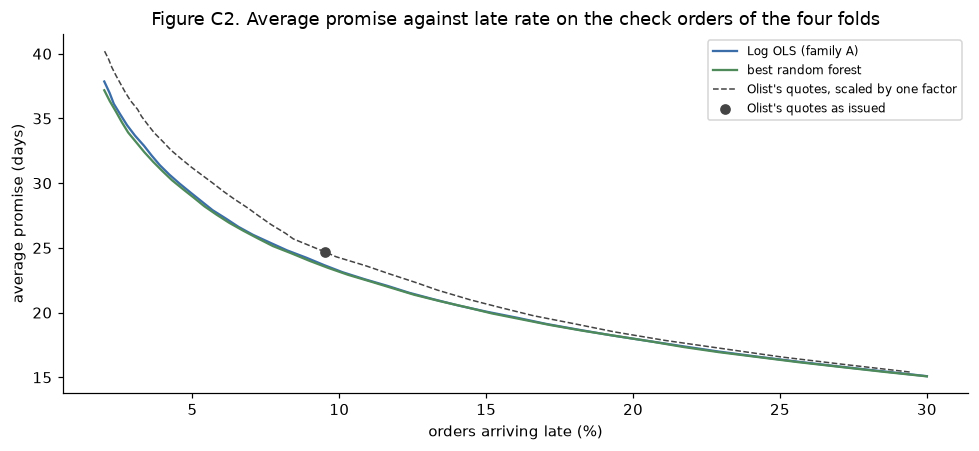

In [49]:
fig, ax = plt.subplots(figsize=(9, 4.2))
for name, colour in [(OLS_NAME, BLUE), (FOREST_NAME, GREEN)]:
    e = estimates[name]
    grid = np.linspace(margin_for(e, 0.30), margin_for(e, 0.02), 40)
    ax.plot([100 * (actual > promise(e, m)).mean() for m in grid], [promise(e, m).mean() for m in grid],
            color=colour, label=name)
factors = np.linspace(factor_for(0.30), factor_for(0.02), 40)
ax.plot([100 * (actual > np.ceil(olist * f)).mean() for f in factors], [np.ceil(olist * f).mean() for f in factors],
        color="#444", ls="--", lw=1, label="Olist's quotes, scaled by one factor")
ax.scatter([100 * target], [olist.mean()], color="#444", zorder=3, label="Olist's quotes as issued")
ax.set_xlabel("orders arriving late (%)")
ax.set_ylabel("average promise (days)")
ax.set_title("Figure C2. Average promise against late rate on the check orders of the four folds")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()


In Figure C2 the curves for Log OLS and the forest lie almost on top of each other from 2% to 30%
late, so the forest's lead is small at every late rate shown. Both lie below Olist's dashed curve
throughout, with the widest gap at the low late rates on the left. The dot for Olist's quotes as
issued sits on the dashed curve.


## C7. How firm is the forest's lead?

The forest's lead over Log OLS in Table C4 is a tenth of a day. The next cell checks two ways it could
come from the set-up rather than the model:

- **Overfitting.** Table C7 scores each model on the orders it learned from, on unseen orders from the
  same periods (shuffled folds, seed 42) and on unseen later months (the time-ordered folds), as Table
  B13 did for Log OLS.
- **The random seed.** A forest depends on the random draws used to grow it. Table C8 refits the best
  forest with seeds 42, 7 and 2026, and repeats the promise of Table C4 for each.

In Table C7, the gap between the first two columns measures overfitting. The gap between the last two
shows how much worse a model does on later months than on new orders from its own periods.


In [50]:
from sklearn.model_selection import KFold

def forest_with_seed(seed):
    return lambda: tree_model(RandomForestRegressor(n_estimators=200, max_features=best_forest["features per split"],
                                                    min_samples_leaf=int(best_forest["min leaf"]), n_jobs=-1,
                                                    random_state=seed), best_forest["target"] == "log days")

# Fitting gap: each model scored on the orders it learned from (all training orders), on unseen
# orders from the same periods (shuffled 4-fold, seed 42), and on unseen later months (the folds).
def gap_row(name, make):
    fitted = make().fit(train[FEATURES], train[TARGET])
    in_sample = np.abs(np.asarray(fitted.predict(train[FEATURES])) - train[TARGET]).mean()
    shuffled = np.mean([np.abs(np.asarray(make().fit(train.iloc[f][FEATURES], train.iloc[f][TARGET])
                                              .predict(train.iloc[c][FEATURES])) - train[TARGET].iloc[c]).mean()
                        for f, c in KFold(n_splits=4, shuffle=True, random_state=RANDOM_SEED).split(train)])
    return {"model": name, "orders it learned from": in_sample, "unseen orders, same periods": shuffled,
            "unseen later months (the folds)": fold_scores[name]["MAE"].mean()}

fit_gap = pd.DataFrame([gap_row(OLS_NAME, MODELS[OLS_NAME]), gap_row(FOREST_NAME, MODELS[FOREST_NAME])])
print("Table C7. Mean MAE, in days, on the orders each model learned from, on unseen orders from the same "
      "periods, and on unseen later months")
display(fit_gap.style.format({c: "{:.3f}" for c in fit_gap.columns if c != "model"}).hide(axis="index"))

# Seed stability: the forest's promise at the same late rate, with three random seeds.
seed_rows = []
for seed in (RANDOM_SEED, 7, 2026):
    e = out_of_fold(forest_with_seed(seed))
    p = promise(e, margin_for(e, target)).mean()
    seed_rows.append({"forest seed": seed, "average promise": p,
                      "shorter than Log OLS by": promises[OLS_NAME].mean() - p})
seeds = pd.DataFrame(seed_rows)
print("Table C8. The forest's average promise at the late rate of Olist's quotes, with three random seeds, in days")
display(seeds.style.format({"average promise": "{:.3f}", "shorter than Log OLS by": "{:.3f}"}).hide(axis="index"))
print(f"with every seed the forest's promise is shorter than Log OLS's by more than a negligible amount: "
      f"{bool((seeds['shorter than Log OLS by'] > NEGLIGIBLE_DAYS).all())}")


Table C7. Mean MAE, in days, on the orders each model learned from, on unseen orders from the same periods, and on unseen later months


model,orders it learned from,"unseen orders, same periods",unseen later months (the folds)
Log OLS (family A),5.150,5.156,5.517
best random forest,4.552,5.236,5.459


Table C8. The forest's average promise at the late rate of Olist's quotes, with three random seeds, in days


forest seed,average promise,shorter than Log OLS by
42,23.532,0.095
7,23.569,0.058
2026,23.576,0.051


with every seed the forest's promise is shorter than Log OLS's by more than a negligible amount: True


The forest overfits; Log OLS shows no sign of it. The forest has a mean MAE of 4.552 days on the
orders it learned from and 5.236 on unseen orders from the same periods, a gap of 0.684 days. For Log
OLS the two are 5.150 and 5.156. On unseen orders from the same periods, Log OLS is the more accurate,
5.156 against 5.236. The forest's lead in Table C3 appears only on later months: it loses 0.223 days
going from new orders to later months, 5.236 to 5.459, against 0.361 for Log OLS, 5.156 to 5.517.

The forest's promise is shorter than Log OLS's with every seed, by 0.095, 0.058 and 0.051 days, each
more than a negligible amount. The seed alone moves the forest's promise by up to 0.044 days, from
23.532 to 23.576, almost half the lead. The lead is better quoted as 0.05 to 0.10 days than as the
0.10 of Table C4.

## C8. The ensemble: a simple average of the two families

Table C3 found Log OLS and the forest each ahead in two of the four folds, so their errors may partly
cancel. The next cell averages their two estimates for each check order, on the log scale and with
equal weight; from here on this average is called **the ensemble**. It gets its own margin, as in
Table C4, and its promise is compared with theirs.

The rule was fixed before the ensemble was computed: it replaces the better single model, the
forest, only if its average promise is shorter by more than a negligible amount at the same late
rate.

Table C9's columns are as in Table C4. Its last column pools all 48,854 check orders, so every order
counts once; Table C3 gives each fold equal weight, so the two do not match.


In [51]:
# A simple average of the two families' estimates, on the log scale, with its own margin.
average = (estimates[OLS_NAME] + estimates[FOREST_NAME]) / 2
average_margin = margin_for(average, target)
average_promise = promise(average, average_margin)
best_single = min(promises[OLS_NAME].mean(), promises[FOREST_NAME].mean())

def ensemble_row(name, log_estimate, margin, promised):
    return {"promise from": name, "margin": f"× {np.exp(margin):.3f}", "late": 100 * (actual > promised).mean(),
            "average promise": promised.mean(),
            "MAE of the estimate, all check orders together": np.abs(np.expm1(log_estimate) - actual).mean()}

ensemble = pd.DataFrame([ensemble_row(n, estimates[n], margins[n], promises[n]) for n in (OLS_NAME, FOREST_NAME)]
                        + [ensemble_row("the ensemble", average, average_margin, average_promise)])
print("Table C9. A simple average of OLS and the forest at the late rate of Olist's quotes, on the check orders, in days")
display(ensemble.style.format({"late": "{:.2f}%", "average promise": "{:.3f}",
                               "MAE of the estimate, all check orders together": "{:.3f}"}).hide(axis="index"))
saving = best_single - average_promise.mean()
print(f"the ensemble's promise is {saving:+.3f} days shorter than the better single model's; the rule set before "
      f"the results asks for more than a negligible amount, so the ensemble {'clears' if saving > NEGLIGIBLE_DAYS else 'does not clear'} it")


Table C9. A simple average of OLS and the forest at the late rate of Olist's quotes, on the check orders, in days


promise from,margin,late,average promise,"MAE of the estimate, all check orders together"
Log OLS (family A),× 2.012,9.51%,23.627,5.669
best random forest,× 1.802,9.51%,23.532,5.594
the ensemble,× 1.893,9.51%,23.397,5.564


the ensemble's promise is +0.134 days shorter than the better single model's; the rule set before the results asks for more than a negligible amount, so the ensemble clears it


The ensemble gives the shortest promise. At the same late rate, 9.51%, it promises 23.397 days on
average, against 23.532 for the forest and 23.627 for Log OLS. That is 0.134 days shorter than the
forest, so the ensemble becomes the candidate for the final model. Its margin is × 1.893, and its
estimate has the lowest pooled MAE of the three, 5.564 days against 5.594 and 5.669. These pooled
errors run higher than Table C3's means because fold 1, with the fewest check orders and the
smallest errors, weighs less once every order counts once.

The two models' errors partly offset. The ensemble's pooled MAE is lower than either model's, which
suggests that on some orders one model runs short while the other runs long. Table C3 suggests
where: in folds 1 and 4, Log OLS's median errors are close to zero, +0.24 and +0.15, so about half
its estimates run short, while the forest's run more than a day long at the median, +1.35 and +1.72.
Both models still run short on average, with mean biases of −3.075 and −1.745 days. So averaging
partly corrects the two models' different mistakes, but not the shortfall they share; the margin
covers that.

### How firm is the ensemble's lead?

Table C9 put the ensemble ahead with the forest grown from one seed, 42. The next cell checks whether
it can be taken as the final model, with the two checks the forest had in Tables C6 and C8:

- Table C10 splits its promise by fold, with its margin of × 1.893 held fixed;
- Table C11 rebuilds it with the forest grown from seeds 42, 7 and 2026. Only the seed changes, and
  each margin is retuned to Olist's late rate on that seed's estimates.

The ensemble is taken as the final model if it keeps its lead over the forest with each of the three
seeds. It would then keep seed 42, fixed in advance, so that no seed is picked for its result. In
both tables, mean MAE is shown as context only.

In [52]:
# The ensemble checked as the forest was in Tables C6 and C8.
# Fold by fold, with the ensemble's margin held fixed as in Table C6.
AVERAGE_NAME = "the ensemble"
avg_by_fold = pd.DataFrame([
    {"fold": k, "checks on": f"{a} to {b}",
     "late, ensemble": 100 * (actual[fold_of == k] > average_promise[fold_of == k]).mean(),
     "late, Olist": 100 * (actual[fold_of == k] > olist[fold_of == k]).mean(),
     "average promise, ensemble": average_promise[fold_of == k].mean(),
     "shorter than the forest by": (promises[FOREST_NAME][fold_of == k] - average_promise[fold_of == k]).mean(),
     "shorter than Olist by": (olist[fold_of == k] - average_promise[fold_of == k]).mean()}
    for k, (a, b) in enumerate(VALIDATION_MONTHS, start=1)])
print("Table C10. The ensemble's promise fold by fold, its margin held fixed: late rate and average promise, in days")
display(avg_by_fold.style.format({c: ("{:.2f}%" if c.startswith("late") else "{:.2f}")
                                  for c in avg_by_fold.columns if c not in ("fold", "checks on")}).hide(axis="index"))

# The same average rebuilt with the forest grown from each of the three seeds of Table C8. Only the
# seed changes; each margin is retuned to Olist's late rate on that seed's own estimates.
def mean_fold_mae(log_estimate):
    """Mean over the four folds of each fold's MAE, as in Table C3."""
    return np.mean([np.abs(np.expm1(log_estimate[fold_of == k]) - actual[fold_of == k]).mean()
                    for k in range(1, len(folds) + 1)])

seed_rows = []
for seed in (RANDOM_SEED, 7, 2026):
    forest_e = estimates[FOREST_NAME] if seed == RANDOM_SEED else out_of_fold(forest_with_seed(seed))
    forest_m = margin_for(forest_e, target)
    avg_e = (estimates[OLS_NAME] + forest_e) / 2
    avg_m = margin_for(avg_e, target)
    forest_p, avg_p = promise(forest_e, forest_m).mean(), promise(avg_e, avg_m).mean()
    seed_rows.append({"forest seed": seed,
                      "margin, forest": f"× {np.exp(forest_m):.3f}", "margin, ensemble": f"× {np.exp(avg_m):.3f}",
                      "average promise, forest": forest_p, "average promise, ensemble": avg_p,
                      "shorter than the forest by": forest_p - avg_p,
                      "mean MAE, forest": mean_fold_mae(forest_e), "mean MAE, ensemble": mean_fold_mae(avg_e)})
avg_seeds = pd.DataFrame(seed_rows)
print("Table C11. The ensemble against the forest at the late rate of Olist's quotes, with the forest grown from three "
      "seeds, in days")
display(avg_seeds.style.format({c: "{:.3f}" for c in avg_seeds.columns
                                if c not in ("forest seed", "margin, forest", "margin, ensemble")}).hide(axis="index"))
spread = avg_seeds["average promise, ensemble"].max() - avg_seeds["average promise, ensemble"].min()
print(f"the ensemble's lead over the forest: smallest {avg_seeds['shorter than the forest by'].min():.3f} days, "
      f"against {spread:.3f} days of movement in the ensemble's own promise from the seed alone")
kept = bool((avg_seeds["shorter than the forest by"] > NEGLIGIBLE_DAYS).all())
print(f"with every seed the ensemble's promise is shorter than the forest's by more than a negligible amount: {kept}; "
      f"by the rule fixed beforehand, the final model is {'the ensemble' if kept else 'the forest'}")


Table C10. The ensemble's promise fold by fold, its margin held fixed: late rate and average promise, in days


fold,checks on,"late, ensemble","late, Olist","average promise, ensemble",shorter than the forest by,shorter than Olist by
1,2017-09 to 2017-10,3.69%,4.28%,22.87,0.02,0.50
2,2017-11 to 2017-12,12.76%,10.27%,22.60,-0.09,2.80
3,2018-01 to 2018-02,12.21%,9.75%,22.89,0.04,3.19
4,2018-03 to 2018-04,7.48%,11.84%,24.96,0.51,-1.48


Table C11. The ensemble against the forest at the late rate of Olist's quotes, with the forest grown from three seeds, in days


forest seed,"margin, forest","margin, ensemble","average promise, forest","average promise, ensemble",shorter than the forest by,"mean MAE, forest","mean MAE, ensemble"
42,× 1.802,× 1.893,23.532,23.397,0.134,5.459,5.420
7,× 1.805,× 1.895,23.569,23.423,0.146,5.462,5.420
2026,× 1.806,× 1.897,23.576,23.441,0.135,5.464,5.422


the ensemble's lead over the forest: smallest 0.134 days, against 0.044 days of movement in the ensemble's own promise from the seed alone
with every seed the ensemble's promise is shorter than the forest's by more than a negligible amount: True; by the rule fixed beforehand, the final model is the ensemble


The ensemble's lead holds under every seed. Its promise is shorter than the forest's by 0.134, 0.146
and 0.135 days, so the ensemble is chosen as the final model, with seed 42 and its margin of ×
1.893. The seed moves the ensemble's own promise by 0.044 days, from 23.397 to 23.441, about a third
of the smallest lead. Its mean MAE stays between 5.420 and 5.422 days, against 5.459 to 5.464 for
the forest.

The lead is not spread evenly across the folds. Most of it comes from fold 4, where the ensemble's
promise is 0.51 days shorter than the forest's. In folds 1 and 3 the difference is 0.02 and 0.04 days,
and in fold 2 the forest's promise is shorter, by 0.09. Like Log OLS and the forest in Table C6, the
ensemble is late more often than Olist's quotes in folds 2 and 3, on 12.76% and 12.21% of orders
against 10.27% and 9.75%, with promises 2.80 and 3.19 days shorter. In fold 4 it is late less often,
7.48% against 11.84%, with a promise 1.48 days longer. Its 9.51% late rate over all four folds
balances these periods.


### The ensemble's promise without its margin, and by region

The next cell looks at the ensemble's promise in two more ways, on the check orders of the four
folds:

- how late each model's estimate would be if used as the promise with no margin, rounded up to whole
  days, to show what the margin is for;
- Table C12 splits the ensemble's promise, with its margin of × 1.893 held fixed, by customer region,
  against Olist's quotes on the same orders. One margin applies to every order, so the late rate may
  differ by where the order goes. The 27 customer states are grouped into Brazil's five official
  regions, and a line under the table gives the range across the states with at least 500 check
  orders.


In [53]:
# The final model, as decided by the rule above (Table C11).
FINAL_NAME = AVERAGE_NAME if kept else FOREST_NAME
final_promise = average_promise if kept else promises[FOREST_NAME]
log_estimates = {**estimates, AVERAGE_NAME: average}

# Without a margin: each model's estimate used as the promise, rounded up to whole days.
bare = {name: promise(log_estimates[name], 0.0) for name in (OLS_NAME, FOREST_NAME, AVERAGE_NAME)}
bare_late = {name: 100 * (actual > p).mean() for name, p in bare.items()}
late_by = (actual - bare[AVERAGE_NAME])[actual > bare[AVERAGE_NAME]]
print(f"with no margin, the ensemble's estimate used as the promise is late on {bare_late[AVERAGE_NAME]:.2f}% of "
      f"orders (OLS {bare_late[OLS_NAME]:.2f}%, forest {bare_late[FOREST_NAME]:.2f}%), and a late order arrives a "
      f"median of {np.median(late_by):.0f} days after the promised day")

# Late rate by region: one margin for every order, so the late rate may differ by where the order goes.
REGION = {**dict.fromkeys(["AC", "AM", "AP", "PA", "RO", "RR", "TO"], "North"),
          **dict.fromkeys(["AL", "BA", "CE", "MA", "PB", "PE", "PI", "RN", "SE"], "Northeast"),
          **dict.fromkeys(["DF", "GO", "MS", "MT"], "Centre-West"),
          **dict.fromkeys(["ES", "MG", "RJ", "SP"], "Southeast"),
          **dict.fromkeys(["PR", "RS", "SC"], "South")}
state = train["customer_state"].to_numpy()[check_order]
assert set(np.unique(state)) <= set(REGION), "a customer state has no region"
region = pd.Series(state).map(REGION).to_numpy()
by_region = pd.DataFrame([
    {"customer region": r, "check orders": int((region == r).sum()),
     "late, Olist": 100 * (actual[region == r] > olist[region == r]).mean(),
     "late, final model": 100 * (actual[region == r] > final_promise[region == r]).mean(),
     "average promise, Olist": olist[region == r].mean(),
     "average promise, final model": final_promise[region == r].mean()}
    for r in ["North", "Northeast", "Centre-West", "Southeast", "South"]])
print(f"Table C12. Late rate and average promise by customer region, the final model ({FINAL_NAME}, margin fixed) "
      f"against Olist's quotes, on the check orders of the four folds")
display(by_region.style.format({"check orders": "{:,}", "late, Olist": "{:.2f}%", "late, final model": "{:.2f}%",
                                "average promise, Olist": "{:.2f}", "average promise, final model": "{:.2f}"})
        .hide(axis="index"))

# The same by customer state, for states with at least 500 check orders, as one summary line.
states = pd.DataFrame({"state": state, "late": actual > final_promise, "olist_late": actual > olist})
big = states.groupby("state").filter(lambda g: len(g) >= 500).groupby("state")[["late", "olist_late"]].mean() * 100
print(f"by customer state (the {len(big)} states with at least 500 check orders): the final model is late on "
      f"{big['late'].min():.2f}% ({big['late'].idxmin()}) to {big['late'].max():.2f}% ({big['late'].idxmax()}); "
      f"Olist's quotes on {big['olist_late'].min():.2f}% ({big['olist_late'].idxmin()}) to "
      f"{big['olist_late'].max():.2f}% ({big['olist_late'].idxmax()})")


with no margin, the ensemble's estimate used as the promise is late on 45.30% of orders (OLS 49.76%, forest 41.17%), and a late order arrives a median of 5 days after the promised day
Table C12. Late rate and average promise by customer region, the final model (the ensemble, margin fixed) against Olist's quotes, on the check orders of the four folds


customer region,check orders,"late, Olist","late, final model","average promise, Olist","average promise, final model"
North,878,13.78%,12.53%,39.41,38.64
Northeast,"4,614",17.79%,7.93%,30.14,36.69
Centre-West,"2,950",9.39%,6.78%,27.12,28.47
Southeast,"33,407",8.42%,9.84%,22.66,20.07
South,"7,005",8.78%,9.78%,27.90,26.49


by customer state (the 12 states with at least 500 check orders): the final model is late on 6.36% (DF) to 19.41% (RJ); Olist's quotes on 5.01% (SP) to 22.42% (CE)


Without a margin the estimates would make poor promises. Used as they are, they are late on 41.17% to
49.76% of orders, 45.30% for the ensemble, and a late order arrives a median of 5 days after the
promised day. The margin of × 1.893 brings the ensemble down to Olist's 9.51%.

With that margin, the ensemble's late rate ranges across regions from 6.78% in the Centre-West to
12.53% in the North, a narrower range than Olist's 8.42% to 17.79%. The largest difference is in the
Northeast: Olist's quotes are late on 17.79% of orders and the ensemble's promise on 7.93%, as it
promises 36.69 days on average against 30.14. In the Southeast, which holds 33,407 of the 48,854 check
orders, it is the other way round: the ensemble's promise is shorter, 20.07 days against 22.66, and
late a little more often, 9.84% against 8.42%. Most of the overall saving comes from the Southeast,
while the Northeast gets longer promises.

A single margin does not give every state the same late rate. By state, the ensemble's promise is late
on 6.36% of orders in the Federal District up to 19.41% in Rio de Janeiro, about twice the overall
9.51%, against 5.01% to 22.42% for Olist's quotes.


## C9. Which features the models rely on

The forest has no coefficients to read, so the next cell measures how much each model relies on each
feature by permutation:

- each model is fitted on fold 4's training months, January 2017 to February 2018, and scored on its
  check months, March and April 2018;
- one feature at a time is shuffled among the check orders, five times, and the average rise in MAE is
  recorded;
- Table C13 lists that rise for Log OLS and the forest, with the features in the forest's order. The
  ensemble averages these two models, so the table covers its two parts.

A larger rise means the model leans more on that feature. Shuffling one feature breaks its link with
the others, so two features that carry similar information, such as distance and same state, may each
look less important alone than together. The ranking describes March and April 2018.


In [54]:
from sklearn.inspection import permutation_importance

# Fitted on fold 4's training months and scored on its unseen check months, March and April 2018.
USED = [c for c in FEATURES if c not in PAYMENT]
fit_rows, check_rows = folds[-1]
importance = {}
for name in [OLS_NAME, FOREST_NAME]:
    fitted = MODELS[name]().fit(train.iloc[fit_rows][USED], train.iloc[fit_rows][TARGET])
    result = permutation_importance(fitted, train.iloc[check_rows][USED], train[TARGET].iloc[check_rows],
                                    scoring="neg_mean_absolute_error", n_repeats=5, random_state=RANDOM_SEED)
    importance[name] = pd.Series(result.importances_mean, index=USED)
importance_table = (pd.DataFrame(importance).rename_axis("feature").reset_index()
                    .sort_values(FOREST_NAME, ascending=False))
print("Table C13. Rise in MAE, in days, when each feature is shuffled on the fold 4 check months (March and April 2018)")
display(importance_table.style.format({c: "{:+.3f}" for c in importance}).hide(axis="index"))
print(f"share of the fold 4 check orders in peak-season weeks: "
      f"{train['peak_season'].iloc[check_rows].astype(float).mean():.2%}")


Table C13. Rise in MAE, in days, when each feature is shuffled on the fold 4 check months (March and April 2018)


feature,Log OLS (family A),best random forest
distance_km,+0.824,+0.550
same_state,+0.210,+0.457
customer_state,+0.325,+0.313
seller_prior_handling_days,+0.197,+0.193
order_freight_value,+0.174,+0.186
seller_prior_orders,+0.020,+0.041
seller_state,+0.040,+0.038
total_weight_kg,+0.005,+0.034
item_count,+0.053,+0.021
order_item_value,+0.001,+0.019


share of the fold 4 check orders in peak-season weeks: 0.00%


The two models lean most on the same five features, in a different order. `distance_km` comes first
for both, with a rise of 0.824 days for Log OLS and 0.550 for the forest. The forest leans harder on
`same_state`, 0.457 against 0.210; we assume this reflects its ability to treat in-state orders as a
group of their own. Then come `customer_state`, 0.325 and 0.313, `seller_prior_handling_days`, 0.197
and 0.193, and `order_freight_value`, 0.174 and 0.186. Every other feature raises MAE by less than
0.06 days for both models.

`peak_season` shows no effect, +0.000 for both, because none of the March and April check orders fall
in peak-season weeks. `main_category` adds almost nothing, 0.018 days for Log OLS and none for the
forest.


## C10. Target encoding instead of dummy columns

Target encoding replaces each value of a category with a smoothed average of the target over the
orders with that value (Micci-Barreca, 2001). Pargent et al. (2022), also in the Phase 1 review, found
it ahead of dummy columns for features with many values. Table C14 tests it on the four folds: on
customer state, seller state and category in Log OLS, and on the seller's ID, added to Log OLS and to
the forest, to see whether knowing which seller adds anything beyond its track record. Each encoding is
learned within each fold's training months, with a five-way split so that each order's value comes
from the other orders. The last column is the change in mean MAE against the same model without target
encoding; a positive change means worse.


In [55]:
from sklearn.preprocessing import TargetEncoder

# Target encoding replaces each value of a category with a smoothed average of log days for that
# value. scikit-learn cross-fits it inside the data it is given (a five-way split), so here it is
# learned from each fold's training months only.
TO_ENCODE    = ["customer_state", "seller_state", "main_category"]
numeric_cols = [c for c in NUMERIC if c not in PAYMENT]
grouped_cols = [c for c in GROUPED if c not in PAYMENT]
WITH_SELLER  = FEATURES + ["seller_id"]

def target_encoder():
    return TargetEncoder(target_type="continuous", smooth="auto", random_state=RANDOM_SEED)

def ols_prep(encode_categories, add_seller):
    kept = [c for c in grouped_cols if not (encode_categories and c in TO_ENCODE)]
    parts = [("numeric", make_pipeline(SimpleImputer(strategy="median"),
                                       FunctionTransformer(np.log1p, feature_names_out="one-to-one"),
                                       StandardScaler()), numeric_cols),
             ("yes/no", FunctionTransformer(lambda x: x.astype(float), feature_names_out="one-to-one"), BOOLEAN),
             ("grouped", OneHotEncoder(drop=[REFERENCE[c] for c in kept], min_frequency=0.01,
                                       handle_unknown="infrequent_if_exist", sparse_output=False,
                                       feature_name_combiner=name_dummy), kept)]
    if not encode_categories:
        parts.append(("state", OneHotEncoder(drop=[REFERENCE["customer_state"]], handle_unknown="ignore",
                                             sparse_output=False), ["customer_state"]))
    encoded = (TO_ENCODE if encode_categories else []) + (["seller_id"] if add_seller else [])
    parts.append(("target", make_pipeline(target_encoder(), StandardScaler()), encoded))
    return ColumnTransformer(parts, verbose_feature_names_out=False)

def ols_with(prep):
    return TransformedTargetRegressor(make_pipeline(prep, LinearRegression()), func=np.log1p, inverse_func=np.expm1)

def forest_with_seller():
    prep = prepare_for_trees()
    prep.transformers.append(("seller", target_encoder(), ["seller_id"]))
    return make_pipeline(prep, best_forest_model())

def cv_with(model, cols):
    return pd.DataFrame([scores(train[TARGET].iloc[c].to_numpy(),
                                np.asarray(model.fit(train.iloc[f][cols], train.iloc[f][TARGET])
                                                .predict(train.iloc[c][cols])))
                         for f, c in folds], index=range(1, len(folds) + 1))

encoding_runs = [
    (OLS_NAME, "dummy columns, as chosen", ols_scores),
    (OLS_NAME, "target encoding for customer state, seller state and category",
     cv_with(ols_with(ols_prep(True, False)), FEATURES)),
    (OLS_NAME, "dummy columns, plus the seller's ID target-encoded",
     cv_with(ols_with(ols_prep(False, True)), WITH_SELLER)),
    (FOREST_NAME, "dummy columns, as chosen", best_forest["scores"]),
    (FOREST_NAME, "dummy columns, plus the seller's ID target-encoded",
     cv_with(forest_with_seller(), WITH_SELLER)),
]
base = {OLS_NAME: ols_scores["MAE"].mean(), FOREST_NAME: best_forest["scores"]["MAE"].mean()}
encoding_table = pd.DataFrame([
    {"model": m, "categories coded as": coding, "MAE by fold": " / ".join(f"{v:.3f}" for v in s["MAE"]),
     "mean MAE": s["MAE"].mean(), "change against dummy columns": s["MAE"].mean() - base[m]}
    for m, coding, s in encoding_runs])
print("Table C14. Target encoding against dummy columns on the four folds, in days")
display(encoding_table.style.format({"mean MAE": "{:.3f}", "change against dummy columns": "{:+.3f}"})
        .hide(axis="index"))
print(f"distinct sellers in the training months: {train['seller_id'].nunique():,}")


Table C14. Target encoding against dummy columns on the four folds, in days


model,categories coded as,MAE by fold,mean MAE,change against dummy columns
Log OLS (family A),"dummy columns, as chosen",3.907 / 6.256 / 6.385 / 5.519,5.517,+0.000
Log OLS (family A),"target encoding for customer state, seller state and category",3.916 / 6.260 / 6.419 / 5.551,5.537,+0.020
Log OLS (family A),"dummy columns, plus the seller's ID target-encoded",3.908 / 6.282 / 6.358 / 5.528,5.519,+0.003
best random forest,"dummy columns, as chosen",4.064 / 5.973 / 6.132 / 5.667,5.459,+0.000
best random forest,"dummy columns, plus the seller's ID target-encoded",4.076 / 5.990 / 6.094 / 5.788,5.487,+0.028


distinct sellers in the training months: 2,240


Target encoding does not help. Encoding customer state, seller state and category raises Log OLS's
mean MAE from 5.517 to 5.537 days, and it is worse in every fold. The seller's ID adds nothing: Log OLS
moves to 5.519, and the forest from 5.459 to 5.487. We assume the seller's track record already
describes each seller from its earlier parcels. Dummy columns stay, and the seller's ID is left out.


## C11. Conclusion

- **The single tree** does not beat Log OLS: 5.617 days against 5.517 at its best, so it is dropped.
- **The random forest** has the lower mean MAE, 5.459 days, by doing better in folds 2 and 3 and worse
  in folds 1 and 4. At Olist's late rate its promise is 23.53 days against 23.63 for Log OLS, shorter
  with all three seeds, by 0.05 to 0.10 days.
- **The ensemble** of Log OLS and the forest promises 23.397 days, 0.134 shorter than the forest, and
  keeps its lead with all three seeds. At the same 9.51% late rate it is 1.29 days shorter than
  Olist's quotes. **The ensemble is the final model**, with seed 42 and a margin of × 1.893.
- **Target encoding** does not improve on dummy columns, and the seller's ID adds nothing (Table C14).

The caveats:

- The gains between models are small: about a tenth of a day on a promise of about 23.5 days.
- The forest overfits (Table C7), and its lead appears only on later months.
- The forest is harder to explain than Log OLS, whose coefficients Table B10 lists; Table C13 gives
  only how much each model relies on each feature, on one fold.
- Neither model lengthens its promise in folds 2 and 3, where Olist's quotes do (Table C6).
- The ensemble's lead over the forest comes mostly from fold 4 (Table C10).
- One margin is not equally reliable everywhere: by state, the ensemble's promise is late on 6.36% to
  19.41% of orders, highest in Rio de Janeiro (Table C12).

The margins found here, × 1.802 for the forest, × 2.012 for Log OLS and × 1.893 for the ensemble, stay
fixed when the models are scored on the test months.


# Part D. The test

This part scores the final model on the test months, May to August 2018. Everything it uses was fixed
in Parts A to C before the test months were opened: the features, the models, the margins that turn an
estimate into a promise, and how the test is scored and judged.


## D1. Setup

The next cell loads the modelling table, Olist's quotes and the two pipelines from `src/c1_model.py`,
a small module holding the versions chosen in Parts B and C; a saved model can only refer to code that
lives in a file. As a check, it rebuilds the four folds, recomputes each model's mean MAE and margin on
their check orders, and checks that both match Parts B and C. These exact margins are the ones used on
the test months.


In [56]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import warnings
# A value never seen in a fold's training months is coded as "other" or as all zeros, by design.
warnings.filterwarnings("ignore", message="Found unknown categories")

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESSED    = PROJECT_ROOT / "data" / "processed"
sys.path.insert(0, str(PROJECT_ROOT / "src"))
from c1_model import PAYMENT, DeliveryPromise, build_forest, build_ols, promise_days

spec        = json.loads((PROCESSED / "c1_feature_spec.json").read_text())
TARGET      = spec["target"]
FEATURES    = spec["numeric"] + spec["boolean"] + spec["categorical"]
USED        = [c for c in FEATURES if c not in PAYMENT]      # payment left out (Table B12)
RANDOM_SEED = spec["random_seed"]
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

table = pd.read_csv(PROCESSED / "c1_model_table.csv")
train = table.loc[table["split"] == "train"].reset_index(drop=True)
test  = table.loc[table["split"] == "test"].reset_index(drop=True)
REFERENCE = {c: train[c].mode()[0] for c in spec["categorical"]}      # learned from training orders
quote = (pd.read_csv(PROCESSED / "order_level.csv", usecols=["order_id", "estimated_delivery_days"])
           .set_index("order_id")["estimated_delivery_days"])
MODELS = {"OLS":    lambda: build_ols(spec, REFERENCE),
          "forest": lambda: build_forest(spec, RANDOM_SEED)}

# The four folds of Table B4, inside the training months.
VALIDATION_MONTHS = [("2017-09", "2017-10"), ("2017-11", "2017-12"),
                     ("2018-01", "2018-02"), ("2018-03", "2018-04")]
month = train["purchase_month"]
folds = [(np.flatnonzero(month < a), np.flatnonzero(month.between(a, b))) for a, b in VALIDATION_MONTHS]
check_order = np.concatenate([c for _, c in folds])
fold_of = np.concatenate([np.full(len(c), k) for k, (_, c) in enumerate(folds, start=1)])
actual = train[TARGET].to_numpy()[check_order]
olist_late_rate = (actual > train["order_id"].iloc[check_order].map(quote).to_numpy()).mean()

def out_of_fold(make):
    """log(1 + days) estimates for every check order, each from its own fold's earlier months."""
    return np.concatenate([np.log1p(np.asarray(make().fit(train.iloc[f][USED], train.iloc[f][TARGET])
                                               .predict(train.iloc[c][USED]))) for f, c in folds])

def margin_for(log_estimate, rate):
    """The smallest log-scale margin whose late rate on the check orders is no higher than rate."""
    lo, hi = -2.0, 3.0
    for _ in range(50):
        mid = (lo + hi) / 2
        lo, hi = (mid, hi) if (actual > promise_days(log_estimate, mid)).mean() > rate else (lo, mid)
    return hi

fold_estimates = {name: out_of_fold(make) for name, make in MODELS.items()}
fold_estimates["ensemble"] = (fold_estimates["OLS"] + fold_estimates["forest"]) / 2
MARGINS = {name: margin_for(e, olist_late_rate) for name, e in fold_estimates.items()}
fold_mae = {name: np.mean([np.abs(np.expm1(e[fold_of == k]) - actual[fold_of == k]).mean()
                           for k in range(1, len(folds) + 1)]) for name, e in fold_estimates.items()}

# As chosen in Table B12 and Tables C3, C9 and C11.
CHOSEN = {"OLS": (5.517, 2.012), "forest": (5.459, 1.802), "ensemble": (5.420, 1.893)}
for name, (mae, margin) in CHOSEN.items():
    assert round(fold_mae[name], 3) == mae and round(np.exp(MARGINS[name]), 3) == margin, name

print("Table D1. The final models rebuilt from src/c1_model.py, on the check orders of the four folds")
display(pd.DataFrame([{"model": name, "mean MAE on the folds": fold_mae[name], "margin": f"× {np.exp(MARGINS[name]):.3f}",
                       "late, fold check orders": 100 * (actual > promise_days(fold_estimates[name], MARGINS[name])).mean()}
                      for name in CHOSEN])
        .style.format({"mean MAE on the folds": "{:.3f}", "late, fold check orders": "{:.2f}%"}).hide(axis="index"))
print(f"training months: {len(train):,} orders, {month.min()} to {month.max()}; test months: {len(test):,} orders, "
      f"{test['purchase_month'].min()} to {test['purchase_month'].max()}, not used until Section D4")


Table D1. The final models rebuilt from src/c1_model.py, on the check orders of the four folds


model,mean MAE on the folds,margin,"late, fold check orders"
OLS,5.517,× 2.012,9.51%
forest,5.459,× 1.802,9.51%
ensemble,5.420,× 1.893,9.51%


training months: 70,851 orders, 2017-01 to 2018-04; test months: 25,352 orders, 2018-05 to 2018-08, not used until Section D4


Table D1 reproduces Parts B and C: a mean MAE of 5.517 days for Log OLS, 5.459 for the forest and
5.420 for the ensemble, with margins of × 2.012, × 1.802 and × 1.893, each late on 9.51% of the check
orders, as Olist's quotes are. The models tested below are the ones chosen in Parts B and C.


## D2. The final model, refitted on all training months

For the test, Log OLS and the forest are fitted once more, on all 70,851 training orders, January 2017
to April 2018, with the same settings and seed.

**The final model is the ensemble:** for each order, the two estimates are averaged on the log scale,
raised by the margin of × 1.893 from Table D1 and rounded up to whole days. This is the regression form
of what the brief calls a voting ensemble.

The next cell prints each model's error on the orders it learned from, a fitting error to set beside
the fold and test errors.


In [57]:
ols_final    = MODELS["OLS"]().fit(train[USED], train[TARGET])
forest_final = MODELS["forest"]().fit(train[USED], train[TARGET])
final_model  = DeliveryPromise(ols_final, forest_final, MARGINS["ensemble"], USED)

learned = {"OLS": np.asarray(ols_final.predict(train[USED])),
           "forest": np.asarray(forest_final.predict(train[USED])),
           "ensemble": final_model.estimate(train)}
print("MAE on the training orders each model learned from: "
      + ", ".join(f"{name} {np.abs(e - train[TARGET]).mean():.3f}" for name, e in learned.items()) + " days")


MAE on the training orders each model learned from: OLS 5.150, forest 4.552, ensemble 4.784 days


## D3. The plan, stated before the test months are opened

With every model and margin fixed as above, the test is measured and judged as follows:

- **Measures**, for Log OLS, the forest, the ensemble and Olist's quotes as issued: the late rate, the
  average promise, the average days early for on-time orders, and the MAE of the estimate.
- **Success.** The margins were set to Olist's 9.51% late rate on the folds, but the test months' late
  rate will differ. So the ensemble's promise is compared with Olist's quotes scaled by one factor to
  the same late rate the ensemble reaches on the test months, using the smallest factor whose late
  rate is no higher. The ensemble succeeds if its promise is shorter on average. Olist's factor is set
  on the test months while the ensemble's margin stays fixed from training, so the comparison favours
  Olist. The ensemble's late rate is also reported against 9.51% and against Olist's quotes as issued.
- **Uncertainty.** McNemar's test compares, order by order, whether the ensemble's promise and Olist's
  quote were late. A bootstrap that resamples whole purchase weeks, 2,000 times with seed 42, gives 95%
  ranges for the paired differences with Olist's quotes, as issued and scaled.
- **Over time and place.** Results are broken down by month, by May–June against July–August, and by
  customer region. August may look slightly better than it was: Part A estimated that about 0.31% of
  August's orders, the slowest, had not arrived when the data ends.

Nothing in Part D changes a model or a margin.


## D4. Scoring the test months

The next cell applies each model to the 25,352 test orders with its margin fixed from Table D1, and
sets the promises beside Olist's quotes as issued (Table D2). The line under the table applies the
success criterion of Section D3, and a second line sets the ensemble's late rate beside the 9.51% it
was set to on the folds.


In [58]:
# Every promise of the plan in Section D3 for one set of orders: the three models with their fixed
# margins, and Olist's quotes as issued.
def promises_for(frame):
    actual_days = frame[TARGET].to_numpy()
    quoted = frame["order_id"].map(quote).to_numpy()
    logs = {"OLS": np.log1p(np.asarray(ols_final.predict(frame[USED]))),
            "forest": np.log1p(np.asarray(forest_final.predict(frame[USED])))}
    logs["ensemble"] = (logs["OLS"] + logs["forest"]) / 2
    promised = {"Olist's quote, as issued": quoted,
                **{name: promise_days(e, MARGINS[name]) for name, e in logs.items()}}
    estimated = {"Olist's quote, as issued": quoted, **{name: np.expm1(e) for name, e in logs.items()}}
    return actual_days, quoted, promised, estimated

def summary(actual_days, promised, estimated):
    rows = []
    for name, p in promised.items():
        on_time = actual_days <= p
        rows.append({"promise from": name if name.startswith("Olist") else f"{name}, margin × {np.exp(MARGINS[name]):.3f}",
                     "late": 100 * (~on_time).mean(), "average promise": p.mean(),
                     "average days early, on-time orders": (p - actual_days)[on_time].mean(),
                     "MAE of the estimate": np.abs(estimated[name] - actual_days).mean()})
    return pd.DataFrame(rows)

def olist_factor(actual_days, quoted, rate):
    """The smallest factor on Olist's quotes, rounded up to whole days, whose late rate is no higher than rate."""
    lo, hi = 0.1, 5.0
    for _ in range(50):
        mid = (lo + hi) / 2
        lo, hi = (mid, hi) if (actual_days > np.ceil(quoted * mid)).mean() > rate else (lo, mid)
    return hi

def primary(actual_days, quoted, average_promise):
    """The success criterion set in the opening cell."""
    our_rate = (actual_days > average_promise).mean()
    factor = olist_factor(actual_days, quoted, our_rate)
    scaled = np.ceil(quoted * factor)
    return {"our late rate": our_rate, "factor": factor, "Olist scaled, late": (actual_days > scaled).mean(),
            "Olist scaled, promise": scaled.mean(), "our promise": average_promise.mean(),
            "shorter by": scaled.mean() - average_promise.mean()}

# The test months, scored once.
test_actual, test_quoted, test_promised, test_estimated = promises_for(test)
print("Table D2. The test months, May to August 2018, scored once: each promise against the actual delivery days")
display(summary(test_actual, test_promised, test_estimated)
        .style.format({"late": "{:.2f}%", "average promise": "{:.2f}", "average days early, on-time orders": "{:.2f}",
                       "MAE of the estimate": "{:.3f}"}).hide(axis="index"))
result = primary(test_actual, test_quoted, test_promised["ensemble"])
print(f"success criterion: at the ensemble's test late rate of {result['our late rate']:.2%}, "
      f"Olist's quotes scaled by × {result['factor']:.3f} are late on {result['Olist scaled, late']:.2%} and promise "
      f"{result['Olist scaled, promise']:.2f} days on average, against {result['our promise']:.2f} for the ensemble: "
      f"shorter by {result['shorter by']:+.2f} days, so the criterion is {'met' if result['shorter by'] > 0 else 'not met'}")
print(f"the ensemble's late rate on the test months: {result['our late rate']:.2%}, against {olist_late_rate:.2%} "
      f"on the check orders of the training folds")


Table D2. The test months, May to August 2018, scored once: each promise against the actual delivery days


promise from,late,average promise,"average days early, on-time orders",MAE of the estimate
"Olist's quote, as issued",4.40%,21.99,13.59,13.294
"OLS, margin × 2.012",2.06%,23.92,15.10,4.354
"forest, margin × 1.802",1.86%,24.31,15.46,5.267
"ensemble, margin × 1.893",1.91%,23.93,15.07,4.721


success criterion: at the ensemble's test late rate of 1.91%, Olist's quotes scaled by × 1.294 are late on 1.90% and promise 28.99 days on average, against 23.93 for the ensemble: shorter by +5.06 days, so the criterion is met
the ensemble's late rate on the test months: 1.91%, against 9.51% on the check orders of the training folds


The ensemble meets the success criterion. On the test months it was late on 1.91% of orders. For
Olist's quotes to be late as rarely, they would have to be scaled up by × 1.294, to an average of
28.99 days; the ensemble promised 23.93, 5.06 days shorter. That comparison favours Olist, whose
factor is set on these months.

Against Olist's quotes as issued, the ensemble's promise is about 1.9 days longer, 23.93 against
21.99, but late on 1.91% of orders against 4.40%, less than half as often. The two sit at different
points of the trade-off between length and lateness, which is why the criterion compares them at the
same late rate. The ensemble's late rate is far below the 9.51% its margin was set to, and Olist's
quotes were late on 4.40% against 9.51% on the folds, so we assume the test months were easier.

On the estimate itself, Log OLS has an MAE of 4.354 days, the ensemble 4.721 and the forest 5.267. On
the folds the forest had been ahead of Log OLS; on the test months it is behind. The promises at the
fixed margins are almost the same, 23.92 days for Log OLS and 23.93 for the ensemble. Olist's MAE of
13.294 is not comparable, as its quote is a promise with a cushion built in (Table B5).


## D5. Is the difference real?

Table D2 covers one set of four months. The next cell measures how firm its comparison with Olist is:

- **McNemar's test** looks only at the orders where the two promises disagree, late under one and on
  time under the other, and asks whether the split between them could be chance;
- **a bootstrap** redraws the test months 2,000 times by whole purchase weeks, as orders bought in the
  same week share their misses (Table B9), and recomputes each difference. Table D3 gives the middle
  95% of the results.


In [59]:
from statsmodels.stats.contingency_tables import mcnemar

ours = test_promised["ensemble"]
ours_late, olist_late = test_actual > ours, test_actual > test_quoted

# McNemar's test: only the orders where the two promises disagree carry information.
only_ours  = int((ours_late & ~olist_late).sum())       # late under the ensemble, on time under Olist
only_olist = int((~ours_late & olist_late).sum())       # on time under the ensemble, late under Olist
paired = mcnemar([[int((~ours_late & ~olist_late).sum()), only_olist],
                  [only_ours, int((ours_late & olist_late).sum())]], exact=False, correction=True)
print(f"McNemar's test against Olist's quotes as issued: {only_ours:,} orders late only under the ensemble, "
      f"{only_olist:,} late only under Olist; statistic {paired.statistic:,.1f}, p-value "
      f"{'below 0.001' if paired.pvalue < 0.001 else f'{paired.pvalue:.3f}'}")

# Week-block bootstrap: whole purchase weeks are resampled, since orders in one week share their misses.
purchased = (pd.read_csv(PROCESSED / "order_level.csv", usecols=["order_id", "order_purchase_timestamp"],
                         parse_dates=["order_purchase_timestamp"])
               .set_index("order_id")["order_purchase_timestamp"])
test_week = test["order_id"].map(purchased).dt.to_period("W").astype(str).to_numpy()
week_rows = [np.flatnonzero(test_week == w) for w in np.unique(test_week)]

def differences(rows):
    a, q, p = test_actual[rows], test_quoted[rows], ours[rows]
    return {"average promise, the ensemble minus Olist's as issued (days)": p.mean() - q.mean(),
            "late rate, the ensemble minus Olist's as issued (points)": 100 * ((a > p).mean() - (a > q).mean()),
            "primary: Olist's quotes scaled to the ensemble's late rate, minus the ensemble (days)": primary(a, q, p)["shorter by"]}

rng = np.random.default_rng(RANDOM_SEED)
draws = pd.DataFrame([differences(np.concatenate([week_rows[i] for i in rng.integers(0, len(week_rows), len(week_rows))]))
                      for _ in range(2000)])
observed = differences(np.arange(len(test_actual)))
ranges = pd.DataFrame({"difference": list(observed), "on the test months": list(observed.values()),
                       "95% range, low": draws.quantile(0.025).values, "95% range, high": draws.quantile(0.975).values})
print(f"Table D3. Paired differences between the ensemble and Olist's quotes on the test months, with 95% ranges from "
      f"2,000 resamples of the {len(week_rows)} purchase weeks")
display(ranges.style.format({c: "{:+.2f}" for c in ranges.columns if c != "difference"}).hide(axis="index"))


McNemar's test against Olist's quotes as issued: 109 orders late only under the ensemble, 741 late only under Olist; statistic 468.4, p-value below 0.001


Table D3. Paired differences between the ensemble and Olist's quotes on the test months, with 95% ranges from 2,000 resamples of the 18 purchase weeks


difference,on the test months,"95% range, low","95% range, high"
"average promise, the ensemble minus Olist's as issued (days)",+1.93,-0.72,+4.11
"late rate, the ensemble minus Olist's as issued (points)",-2.49,-3.93,-1.08
"primary: Olist's quotes scaled to the ensemble's late rate, minus the ensemble (days)",+5.06,+3.27,+7.84


Both checks agree. Of the orders where the two promises disagree, 741 were late only under Olist's
quote and 109 only under the ensemble; McNemar's test puts the chance of a split this uneven, if the
two were equally reliable, below 0.001. Across 2,000 resamples of the 18 purchase weeks, the ensemble
is late less often than Olist's quotes as issued by 1.08 to 3.93 points, and shorter than Olist's
quotes scaled to its own late rate by 3.27 to 7.84 days, so the success criterion holds across the
range. Its extra length against Olist's quotes as issued, 1.93 days, is less certain: the range runs
from 0.72 days shorter to 4.11 longer. We assume this is because Olist's quotes varied over these
months.


## D6. Over time

The next cell splits Table D2 by purchase month and by half, May–June against July–August, with every
margin still fixed (Table D4). Two lines under it compare orders bought in the first and second halves
of August, as slow orders bought late in August may not have arrived when the data ends.


In [60]:
# The test months one by one, and in two halves, with each margin still fixed.
test_month = test["purchase_month"].to_numpy()
PERIODS = ([(m, test_month == m) for m in sorted(np.unique(test_month))]
           + [("May and June", np.isin(test_month, ["2018-05", "2018-06"])),
              ("July and August", np.isin(test_month, ["2018-07", "2018-08"])),
              ("all four months", np.ones(len(test_month), dtype=bool))])
by_period = pd.DataFrame([
    {"purchase month": name, "orders": int(rows.sum()), "median days": np.median(test_actual[rows]),
     "late, Olist": 100 * (test_actual[rows] > test_quoted[rows]).mean(),
     "late, ensemble": 100 * (test_actual[rows] > ours[rows]).mean(),
     "average promise, Olist": test_quoted[rows].mean(), "average promise, ensemble": ours[rows].mean()}
    for name, rows in PERIODS])
print("Table D4. The test months by purchase month and by half: delivery time, late rate and average promise, "
      "each margin held fixed")
display(by_period.style.format({"orders": "{:,}", "median days": "{:.0f}", "late, Olist": "{:.2f}%",
                                "late, ensemble": "{:.2f}%", "average promise, Olist": "{:.2f}",
                                "average promise, ensemble": "{:.2f}"}).hide(axis="index"))

# The August check: slow orders bought late in August may not have arrived before the data ends.
day = test["order_id"].map(purchased).dt.day.to_numpy()
for label, rows in [("bought 1 to 15 August", (test_month == "2018-08") & (day <= 15)),
                    ("bought 16 to 31 August", (test_month == "2018-08") & (day > 15))]:
    print(f"{label}: {int(rows.sum()):,} orders, median {np.median(test_actual[rows]):.0f} days, "
          f"late {100 * (test_actual[rows] > test_quoted[rows]).mean():.2f}% under Olist and "
          f"{100 * (test_actual[rows] > ours[rows]).mean():.2f}% under the ensemble")

# Every order bought in August, whatever its status, to see whether the dataset itself thins out.
every = pd.read_csv(PROCESSED / "order_level.csv", usecols=["order_purchase_timestamp", "order_status"],
                    parse_dates=["order_purchase_timestamp"])
august = every.loc[every["order_purchase_timestamp"].dt.strftime("%Y-%m") == "2018-08"]
august_day = august["order_purchase_timestamp"].dt.day
per_day = august_day.value_counts()
print(f"every order bought in August, any status: {int((august_day <= 15).sum()):,} from 1 to 15 August and "
      f"{int((august_day > 15).sum()):,} from 16 to 31; {per_day.get(20, 0)} bought on 20 August and "
      f"{per_day.get(31, 0)} on 31 August; bought 16 to 31 August and still in transit when the data ends: "
      f"{int(((august_day > 15) & (august['order_status'] == 'shipped')).sum())}")


Table D4. The test months by purchase month and by half: delivery time, late rate and average promise, each margin held fixed


purchase month,orders,median days,"late, Olist","late, ensemble","average promise, Olist","average promise, ensemble"
2018-05,"6,749",9,6.56%,3.45%,23.53,23.87
2018-06,"6,096",8,1.16%,1.41%,28.41,24.47
2018-07,"6,156",7,3.38%,1.56%,20.33,24.70
2018-08,"6,351",7,6.19%,1.07%,15.82,22.71
May and June,"12,845",8,4.00%,2.48%,25.84,24.15
July and August,"12,507",7,4.81%,1.31%,18.04,23.69
all four months,"25,352",8,4.40%,1.91%,21.99,23.93


bought 1 to 15 August: 4,219 orders, median 7 days, late 8.27% under Olist and 1.52% under the ensemble
bought 16 to 31 August: 2,132 orders, median 6 days, late 2.06% under Olist and 0.19% under the ensemble


every order bought in August, any status: 4,332 from 1 to 15 August and 2,180 from 16 to 31; 256 bought on 20 August and 1 on 31 August; bought 16 to 31 August and still in transit when the data ends: 12


The test months were faster than the training months: the median delivery time fell from 9 days in
May to 7 in July and August, against 10 to 13 on the folds (Table B4). Olist's average quote followed,
falling from 28.41 days in June to 15.82 in August, while the ensemble's stayed between 22.71 and
24.70. June's long quotes and Olist's high late rate in May, 6.56%, coincide with Brazil's truckers'
strike of 21 May to 1 June 2018 (Reuters, 25 May 2018).

In July and August the ensemble promised 5.65 days more than Olist, 23.69 against 18.04, and was late
on 1.31% of orders against 4.81%. This is the cost of a margin fixed on earlier months: it is too
cautious when deliveries speed up.

Late August is thin because the dataset ends: orders per day fall from 256 on 20 August to 1 on 31
August, with only 12 still in transit. The 2,132 late-August orders, 8.4% of the test months, may
still look slightly faster than they were.


### The whole trade-off on the test months

The success criterion compared the two promises at one late rate, 1.91%. Figure D1 draws the whole
trade-off on the test months, as Figure C2 did on the folds: the ensemble with its margin varied, and
Olist's quotes scaled by one factor. The margins and factors along the curves are found on the test
months themselves, so the figure is description only. The two lines under it read off the gap at
Olist's late rate as issued, 4.40%, and at the folds' 9.51%.


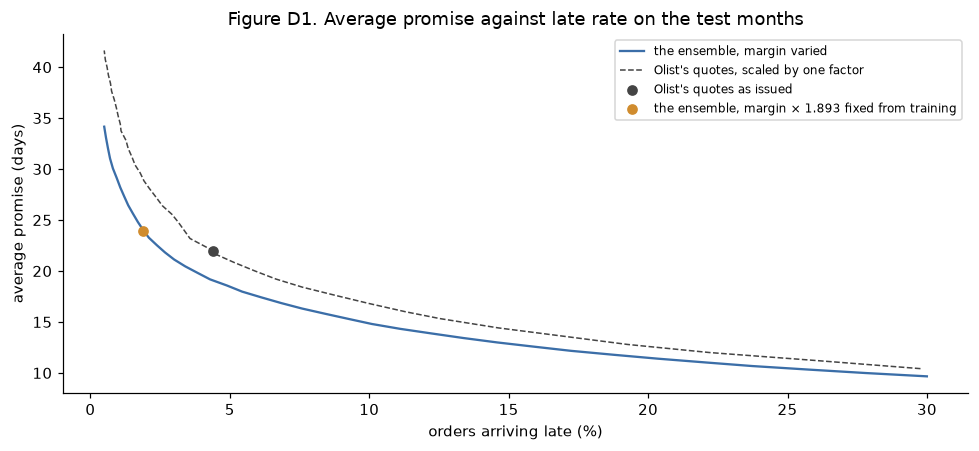

at 4.40% late: the ensemble would promise 19.06 days, Olist's scaled quotes 21.95, a gap of 2.88 days
at 9.51% late: the ensemble would promise 15.13 days, Olist's scaled quotes 17.12, a gap of 1.99 days


In [61]:
# The whole trade-off on the test months, as in Figure C2. Description only: the margins and
# factors here are found on the test months themselves, and nothing is chosen from them.
ensemble_log = np.log1p(np.asarray(ols_final.predict(test[USED]))) / 2 \
              + np.log1p(np.asarray(forest_final.predict(test[USED]))) / 2

def test_margin(rate):
    """The smallest log-scale margin whose late rate on the test months is no higher than rate."""
    lo, hi = -2.0, 3.0
    for _ in range(50):
        mid = (lo + hi) / 2
        lo, hi = (mid, hi) if (test_actual > promise_days(ensemble_log, mid)).mean() > rate else (lo, mid)
    return hi

fig, ax = plt.subplots(figsize=(9, 4.2))
margins = np.linspace(test_margin(0.30), test_margin(0.005), 40)
ax.plot([100 * (test_actual > promise_days(ensemble_log, m)).mean() for m in margins],
        [promise_days(ensemble_log, m).mean() for m in margins], color="#3b6ea8", label="the ensemble, margin varied")
factors = np.linspace(olist_factor(test_actual, test_quoted, 0.30), olist_factor(test_actual, test_quoted, 0.005), 40)
ax.plot([100 * (test_actual > np.ceil(test_quoted * f)).mean() for f in factors],
        [np.ceil(test_quoted * f).mean() for f in factors], color="#444", ls="--", lw=1,
        label="Olist's quotes, scaled by one factor")
ax.scatter([100 * (test_actual > test_quoted).mean()], [test_quoted.mean()], color="#444", zorder=3,
           label="Olist's quotes as issued")
ax.scatter([100 * (test_actual > ours).mean()], [ours.mean()], color="#d08c2e", zorder=3,
           label="the ensemble, margin × 1.893 fixed from training")
ax.set_xlabel("orders arriving late (%)")
ax.set_ylabel("average promise (days)")
ax.set_title("Figure D1. Average promise against late rate on the test months")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

for rate in (test_late := (test_actual > test_quoted).mean(), olist_late_rate):
    ours_at = promise_days(ensemble_log, test_margin(rate)).mean()
    olist_at = np.ceil(test_quoted * olist_factor(test_actual, test_quoted, rate)).mean()
    print(f"at {rate:.2%} late: the ensemble would promise {ours_at:.2f} days, Olist's scaled quotes {olist_at:.2f}, "
          f"a gap of {olist_at - ours_at:.2f} days")


The ensemble's curve lies below Olist's at every late rate drawn, from 0.5% to 30%. At Olist's own
late rate on these months, 4.40%, it would promise 19.06 days against 21.95 for Olist's scaled quotes,
2.88 days shorter; at 9.51%, 15.13 against 17.12, 1.99 shorter. The gap narrows as more lateness is
allowed, as on the folds, but stays open. The fixed margin placed the ensemble at 1.91%, left of
Olist's quotes as issued; a margin set for these faster months would have moved it along the same
curve.


## D7. From the training months to the test months

Table D5 sets each model's error side by side at every stage: on the orders it learned from, on
shuffled and time-ordered folds, and on the test months, with the median error, estimate minus actual,
on the folds and on the test months. The ensemble's shuffled score is new; those of Log OLS and the
forest repeat Tables B13 and C7. It shows which kind of fold better anticipated the test.


In [62]:
from sklearn.model_selection import KFold

# Shuffled 4-fold cross-validation inside the training months, seed 42, as in Table B13 and
# Table C7, now for all three models. Log-scale estimates, so the ensemble is their average.
shuffled_log = {name: np.zeros(len(train)) for name in ("OLS", "forest")}
for fit_rows, check_rows in KFold(n_splits=4, shuffle=True, random_state=RANDOM_SEED).split(train):
    for name, make in MODELS.items():
        shuffled_log[name][check_rows] = np.log1p(np.asarray(
            make().fit(train.iloc[fit_rows][USED], train.iloc[fit_rows][TARGET]).predict(train.iloc[check_rows][USED])))
shuffled_log["ensemble"] = (shuffled_log["OLS"] + shuffled_log["forest"]) / 2
fold_of_shuffled = np.zeros(len(train), dtype=int)
for k, (_, check_rows) in enumerate(KFold(n_splits=4, shuffle=True, random_state=RANDOM_SEED).split(train), start=1):
    fold_of_shuffled[check_rows] = k

def mean_fold_mae(log_estimate, truth, fold_index):
    return np.mean([np.abs(np.expm1(log_estimate[fold_index == k]) - truth[fold_index == k]).mean()
                    for k in np.unique(fold_index)])

train_days = train[TARGET].to_numpy()
test_log = {"OLS": np.log1p(np.asarray(ols_final.predict(test[USED]))),
            "forest": np.log1p(np.asarray(forest_final.predict(test[USED])))}
test_log["ensemble"] = (test_log["OLS"] + test_log["forest"]) / 2
ttt = pd.DataFrame([
    {"model": name,
     "orders it learned from": np.abs(learned[name] - train_days).mean(),
     "shuffled folds": mean_fold_mae(shuffled_log[name], train_days, fold_of_shuffled),
     "time-ordered folds": fold_mae[name],
     "test months": np.abs(np.expm1(test_log[name]) - test_actual).mean(),
     "median error, time-ordered folds": np.median(np.expm1(fold_estimates[name]) - actual),
     "median error, test months": np.median(np.expm1(test_log[name]) - test_actual)}
    for name in ("OLS", "forest", "ensemble")])
print("Table D5. MAE of each model's estimate, in days, from the orders it learned from to the test months, "
      "with the median error (estimate minus actual) on the folds and on the test months")
display(ttt.style.format({c: ("{:+.2f}" if c.startswith("median") else "{:.3f}") for c in ttt.columns if c != "model"})
        .hide(axis="index"))


Table D5. MAE of each model's estimate, in days, from the orders it learned from to the test months, with the median error (estimate minus actual) on the folds and on the test months


model,orders it learned from,shuffled folds,time-ordered folds,test months,"median error, time-ordered folds","median error, test months"
OLS,5.150,5.156,5.517,4.354,-0.97,+2.56
forest,4.552,5.236,5.459,5.267,+0.29,+3.88
ensemble,4.784,5.105,5.420,4.721,-0.35,+3.16


Neither kind of fold anticipated the test score closely. Log OLS had an MAE of 5.156 days on shuffled
folds and 5.517 on time-ordered ones, against 4.354 on the test months; the shuffled figure came
closer. We assume this is because the test months were faster than any period the folds checked. The
time-ordered folds did show that the error moves between periods, and the test confirms it the other
way: Log OLS's median error went from −0.97 days on the folds to +2.56 on the test months, from a
little short to about two and a half days long.

The median errors also explain the change in ranking. Every model ran long on the test months, the
forest most, with a median error of +3.88 days against +2.56 for Log OLS and +3.16 for the ensemble.
We assume the forest, fitted on days rather than log days, aims higher (its median error on the folds
is +0.29, against −0.97 for Log OLS); that helped in the slower folds and hurt in the faster test
months. The ensemble sits between the two.


## D8. By region on the test months

The next cell repeats the region breakdown of Table C12 on the test months, with every margin fixed,
against Olist's quotes as issued (Table D6), and adds a line for the states with at least 500 test
orders.


In [63]:
# The test months by customer region, as Table C12 did on the folds, every margin still fixed.
REGION = {**dict.fromkeys(["AC", "AM", "AP", "PA", "RO", "RR", "TO"], "North"),
          **dict.fromkeys(["AL", "BA", "CE", "MA", "PB", "PE", "PI", "RN", "SE"], "Northeast"),
          **dict.fromkeys(["DF", "GO", "MS", "MT"], "Centre-West"),
          **dict.fromkeys(["ES", "MG", "RJ", "SP"], "Southeast"),
          **dict.fromkeys(["PR", "RS", "SC"], "South")}
test_state = test["customer_state"].to_numpy()
assert set(np.unique(test_state)) <= set(REGION), "a customer state has no region"
test_region = pd.Series(test_state).map(REGION).to_numpy()
by_region = pd.DataFrame([
    {"customer region": r, "test orders": int((test_region == r).sum()),
     "late, Olist": 100 * (test_actual[test_region == r] > test_quoted[test_region == r]).mean(),
     "late, ensemble": 100 * (test_actual[test_region == r] > ours[test_region == r]).mean(),
     "average promise, Olist": test_quoted[test_region == r].mean(),
     "average promise, ensemble": ours[test_region == r].mean()}
    for r in ["North", "Northeast", "Centre-West", "Southeast", "South"]])
print("Table D6. Late rate and average promise by customer region on the test months, the ensemble (margin fixed) "
      "against Olist's quotes as issued")
display(by_region.style.format({"test orders": "{:,}", "late, Olist": "{:.2f}%", "late, ensemble": "{:.2f}%",
                                "average promise, Olist": "{:.2f}", "average promise, ensemble": "{:.2f}"})
        .hide(axis="index"))
states = pd.DataFrame({"state": test_state, "late": test_actual > ours, "olist_late": test_actual > test_quoted})
big = states.groupby("state").filter(lambda g: len(g) >= 500).groupby("state")[["late", "olist_late"]].mean() * 100
print(f"by customer state (the {len(big)} states with at least 500 test orders): the ensemble is late on "
      f"{big['late'].min():.2f}% ({big['late'].idxmin()}) to {big['late'].max():.2f}% ({big['late'].idxmax()}); "
      f"Olist's quotes on {big['olist_late'].min():.2f}% ({big['olist_late'].idxmin()}) to "
      f"{big['olist_late'].max():.2f}% ({big['olist_late'].idxmax()})")


Table D6. Late rate and average promise by customer region on the test months, the ensemble (margin fixed) against Olist's quotes as issued


customer region,test orders,"late, Olist","late, ensemble","average promise, Olist","average promise, ensemble"
North,392,3.83%,0.26%,36.58,44.11
Northeast,"2,191",7.26%,2.01%,29.39,38.51
Centre-West,"1,452",4.27%,0.96%,24.80,30.18
Southeast,"17,980",4.39%,2.11%,19.99,20.51
South,"3,337",2.67%,1.32%,25.00,27.69


by customer state (the 8 states with at least 500 test orders): the ensemble is late on 1.09% (SC) to 2.50% (BA); Olist's quotes on 2.23% (RS) to 8.82% (BA)


Table D6 shows mainly the cost of the fixed margin. The ensemble's promises are longer than Olist's in
every region: by 0.52 days in the Southeast, which holds 17,980 of the 25,352 test orders, and by 7.53
days in the North and 9.12 in the Northeast. Being late less often, on 0.26% to 2.11% of orders against
2.67% to 7.26%, follows from those longer promises; the fair comparison is at the same late rate
(Figure D1). By state the ensemble is late on 1.09% to 2.50% of orders, against 2.23% to 8.82% for
Olist; the North's rate rests on 392 orders.


## D9. What this means for Olist

- **Rank the orders by risk, then set the cushion.** At every late rate drawn, the ensemble's promise
  is shorter than Olist's quotes, on the folds and on the test months (Figures C2 and D1): 2.88 days
  shorter at Olist's own late rate on the test months. On the folds, at 9.51% late, its late rate also
  varied less across regions than Olist's (Table C12).
- **The margin matters more than the model.** Log OLS and the ensemble promise almost the same on the
  test months, 23.92 and 23.93 days, while a margin fixed on slower months made every promise too
  cautious: late on 1.91% of orders against the 9.51% intended, and 5.65 days longer than Olist's
  quotes in July and August (Table D4). The margin should be refreshed as delivery speed changes.
- **Choose the late rate deliberately.** The trade-off curve puts a price on lateness: on the test
  months, allowing 9.51% of orders to be late instead of 4.40% shortens the ensemble's promise from
  19.06 to 15.13 days (Figure D1). Which point to use is a business decision, between longer promises,
  which Cui et al. (2024) link to lower sales, and late deliveries, which Phase 1 linked to lower
  review scores.
- **The route sets most of the wait.** Distance, whether the parcel stays inside one state, and the
  customer's state matter most to both models (Table C13), and crossing a state border adds about 3.5
  days at the same distance (Table B10).


## D10. Limitations

- The test months were faster than the training months, so the fixed margin was too cautious: late on
  1.91% of orders against 9.51% intended, and 1.93 days longer than Olist's quotes as issued (95% range
  −0.72 to +4.11).
- One margin serves every order. On the folds, the state late rates ranged from 6.36% to 19.41% (Table
  C12).
- The dataset thins out at the end: half as many orders were bought in the second half of August as in
  the first, whatever their status, and those that remain were delivered faster. Missing slow orders
  may flatter the late rates of those 2,132 orders a little (8.4% of the test months).
- Only delivered orders are modelled; the 1,699 orders still open at the end of the data are left out
  (Part A).
- The four folds were used for tuning, for the margins and for choosing the model, so the fold scores
  are slightly optimistic; the test months are the unbiased check.
- Nothing at checkout says how fast deliveries are going at that moment, and five measures of recent
  conditions did not help (Table B15). We assume this, more than the model, limits accuracy: the
  estimate misses by 4.7 days on the test months.
- The training months hold one peak season and the test months none, so the peak-season effect is
  untested on new months.
- The models differ by about a tenth of a day at the same late rate, and the bar for choosing between
  them was a negligible amount. The final choice holds under a stricter bar tied to the seed's own
  movement, 0.044 days: the ensemble leads the forest by 0.134 to 0.146 days and Log OLS by 0.186 to
  0.230 (Tables C9 and C11).
- Log OLS was chosen over raw days on a tie in mean MAE (Table B12). Raw days was never turned into a
  promise, so whether it would give a shorter promise at the same late rate is untested.
- Payment type and instalments were left out, as the data does not show whether Olist displays the
  date before or after payment is chosen; leaving them out cost 0.009 days on the folds.
- Delivery dates are assumed to be recorded when the delivery happened (Part A).
- The North has only 392 test orders, and late rates by state rest on a few hundred orders each.


## D11. Saving the final model

The next cell saves the ensemble exactly as it was tested, fitted on the training months with its
margin, to `models/c1_delivery_promise.pkl`, with a description beside it in
`models/c1_delivery_promise.json`: what the model is, how to load it, its features, margin and seed,
the months it learned from, its results on the folds and the test months, and the library versions.
The model's code lives in `src/c1_model.py`, because a saved model can only be loaded again if the
code it refers to is in a file. It then reloads the saved model and checks that it gives the same
promise for every test order.


In [64]:
import platform

import joblib
import sklearn

# The final model as tested above, fitted on the training months, saved with its description.
MODEL_DIR = PROJECT_ROOT / "models"
MODEL_DIR.mkdir(exist_ok=True)
model_path, card_path = MODEL_DIR / "c1_delivery_promise.pkl", MODEL_DIR / "c1_delivery_promise.json"
joblib.dump(final_model, model_path, compress=3)

# A saved model is only useful if it gives the same promises when loaded again.
reloaded = joblib.load(model_path)
assert np.array_equal(reloaded.promise(test), final_model.promise(test)), "the reloaded model differs"

card = {
    "model": "C1 delivery promise: an equal-weight averaging ensemble of OLS (log days, log features) "
             "and a random forest (days), averaged on log(1 + days), raised by one margin, rounded up to whole days",
    "load": "sys.path.insert(0, 'src'); import joblib; model = joblib.load('models/c1_delivery_promise.pkl'); "
            "model.promise(orders)",
    "input columns": final_model.features,
    "margin": round(float(np.exp(MARGINS["ensemble"])), 6),
    "margin, log scale": float(MARGINS["ensemble"]),
    "random seed": RANDOM_SEED,
    "trained on": f"{len(train):,} delivered orders bought {train['purchase_month'].min()} to {train['purchase_month'].max()}",
    "training folds (check orders of the four time-ordered folds)": {
        "mean MAE": round(float(fold_mae["ensemble"]), 3), "late rate": round(float(olist_late_rate), 4)},
    "test months": {
        "orders": len(test), "late rate": round(float(result["our late rate"]), 4),
        "average promise": round(float(result["our promise"]), 2),
        "MAE": round(float(np.abs(test_estimated["ensemble"] - test_actual).mean()), 3),
        "Olist as issued": {"late rate": round(float((test_actual > test_quoted).mean()), 4),
                            "average promise": round(float(test_quoted.mean()), 2)},
        "success criterion": {"Olist scaled to the same late rate, average promise": round(float(result["Olist scaled, promise"]), 2),
                              "shorter by": round(float(result["shorter by"]), 2)}},
    "versions": {"python": platform.python_version(), "scikit-learn": sklearn.__version__,
                 "numpy": np.__version__, "pandas": pd.__version__, "joblib": joblib.__version__},
}
card_path.write_text(json.dumps(card, indent=2), encoding="utf-8")
print(f"saved {model_path.name} ({model_path.stat().st_size / 1e6:.1f} MB) and {card_path.name}; reloaded model gives "
      f"identical promises on all {len(test):,} test orders")


saved c1_delivery_promise.pkl (27.6 MB) and c1_delivery_promise.json; reloaded model gives identical promises on all 25,352 test orders
